ICLM_Pipeline.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1kDV6FDUKbI8yCs9OUWSdQqMz-5OPAGd1

# **Setup — Install Dependencies**

In [7]:
!pip install -q faker imbalanced-learn shap plotly streamlit streamlit-option-menu pyngrok langchain-groq langchain-core python-dotenv

In [8]:
# Install all required packages
# import subprocess, sys
# pkgs = [
#     'faker', 'numpy', 'pandas', 'scipy', 'scikit-learn',
#     'xgboost', 'imbalanced-learn', 'shap', 'matplotlib',
#     'seaborn', 'plotly', 'faiss-cpu', 'langchain',
#     'langchain-community', 'langchain-groq', 'sentence-transformers',
#     'streamlit', 'python-dotenv'
# ]
# for p in pkgs:
#     subprocess.check_call([sys.executable, '-m', 'pip', 'install', p, '-q'])
# print('All packages installed')

# import numpy as np
# import pandas as pd
# from datetime import datetime, timedelta
# import random, json, re

# --- DEFINE MISSING HELPERS TO FIX NAMEERROR ---
# HO = ['Nguyễn', 'Trần', 'Lê', 'Phạm', 'Hoàng', 'Huỳnh', 'Phan',
#       'Vũ', 'Võ', 'Đặng', 'Bùi', 'Đỗ', 'Hồ', 'Ngô', 'Dương', 'Lý']

# TEN_POOL = [
#     'An', 'Anh', 'Bảo', 'Bình', 'Chi', 'Châu', 'Dung', 'Duy',
#     'Đức', 'Hà', 'Hải', 'Hoa', 'Hùng', 'Hữu', 'Khoa', 'Lan',
#     'Linh', 'Long', 'Mai', 'Minh', 'Nam', 'Nga', 'Nhung', 'Phong',
#     'Phú', 'Phương', 'Quân', 'Quang', 'Tấn', 'Thảo', 'Thắng',
#     'Thanh', 'Thu', 'Thị', 'Trang', 'Trí', 'Trung', 'Tuấn',
#     'Tú', 'Văn', 'Việt', 'Xuân', 'Yến'
# ]

# DOMAINS = ['gmail.com', 'yahoo.com', 'outlook.com', 'hotmail.com']

# def vn_to_ascii(text: str) -> str:
#     text = text.lower()
#     replacements = {
#         'à':'a','á':'a','ả':'a','ã':'a','ạ':'a',
#         'ă':'a','ắ':'a','ặ':'a','ằ':'a','ẳ':'a','ẵ':'a',
#         'â':'a','ấ':'a','ậ':'a','ầ':'a','ẩ':'a','ẫ':'a',
#         'đ':'d',
#         'è':'e','é':'e','ẻ':'e','ẽ':'e','ẹ':'e',
#         'ê':'e','ế':'e','ệ':'e','ề':'e','ể':'e','ễ':'e',
#         'ì':'i','í':'i','ỉ':'i','ĩ':'i','ị':'i',
#         'ò':'o','ó':'o','ỏ':'o','õ':'o','ọ':'o',
#         'ô':'o','ố':'o','ộ':'o','ồ':'o','ổ':'o','ỗ':'o',
#         'ơ':'o','ớ':'o','ợ':'o','ờ':'o','ở':'o','ỡ':'o',
#         'ù':'u','ú':'u','ủ':'u','ũ':'u','ụ':'u',
#         'ư':'u','ứ':'u','ự':'u','ừ':'u','ử':'u','ữ':'u',
#         'ỳ':'y','ý':'y','ỷ':'y','ỹ':'y','ỵ':'y',
#     }
#     for vn, en in replacements.items():
#         text = text.replace(vn, en)
#     return re.sub(r'[^a-z0-9]', '', text)

# def vn_name() -> str:
#     ho    = np.random.choice(HO)
#     n_dem = np.random.choice([0, 1, 2], p=[0.30, 0.60, 0.10])
#     dem   = ' '.join(np.random.choice(TEN_POOL, n_dem, replace=False)) if n_dem > 0 else ''
#     ten   = np.random.choice(TEN_POOL)
#     return f"{ho} {dem} {ten}".strip() if dem else f"{ho} {ten}"

# def vn_email(name: str) -> str:
#     base   = vn_to_ascii(name)
#     suffix = np.random.choice([
#         str(np.random.randint(10, 999)),
#         str(np.random.randint(1990, 2005)),
#         ''
#     ])
#     return f"{base}{suffix}@{np.random.choice(DOMAINS)}"

# def vn_phone() -> str:
#     prefix = np.random.choice([
#         '032','033','034','035','036','037','038','039',
#         '070','079','077','076','078',
#         '056','058','089',
#         '090','093','086','096','097','098',
#         '091','094',
#         '092',
#     ])
#     digits = ''.join([str(np.random.randint(0, 10)) for _ in range(7)])
#     return f"{prefix}{digits}"

# def tet_multiplier(dt: datetime) -> float:
#     tet_dates = [datetime(2023, 1, 22), datetime(2024, 2, 10)]
#     for tet in tet_dates:
#         if abs((dt - tet).days) <= 21:
#             return 2.5
#     if (dt.month == 11 and dt.day == 11) or (dt.month == 12 and dt.day == 12):
#         return 3.0
#     return 1.0

# def random_order_date(join_date: datetime) -> datetime:
#     days_since = (SIM_END - join_date).days
#     if days_since <= 0:
#         return join_date
#     for _ in range(20):
#         d = join_date + timedelta(days=random.randint(0, days_since))
#         if random.random() < (tet_multiplier(d) / 3.0):
#             return d
#     return join_date + timedelta(days=random.randint(0, days_since))

#RE-CALIBRATE WAVE 2 PROBABILITIES & CORRECTIONS
# N_CUSTOMERS = 50_000
# SEED = 42
# np.random.seed(SEED)
# random.seed(SEED)

# SIM_START = datetime(2023, 1, 1)
# SIM_END = datetime(2024, 12, 31)
# SNAPSHOT = datetime(2024, 12, 31)

# Correcting Gender Target: Female 58%, Male 42%
# GENDER_P = [0.42, 0.58]

# Payment Methods
# PAYMENT_METHODS = [
#     'Cash on Delivery (COD)', 'E-wallet', 'Credit Card',
#     'Debit Card', 'Bank Transfer', 'Buy Now Pay Later (BNPL)'
# ]
# PAY_W = [0.6634, 0.1782, 0.0792, 0.0297, 0.0297, 0.0198]

# VN_PROVINCES = [
#     'Hồ Chí Minh', 'Hà Nội', 'Bình Dương', 'Đồng Nai',
#     'Hải Phòng', 'Đà Nẵng', 'Thanh Hóa', 'Nghệ An',
#     'Cần Thơ', 'Bà Rịa - Vũng Tàu', 'Long An', 'Khánh Hòa',
#     'Tiền Giang', 'Kiên Giang', 'An Giang', 'Other'
# ]

# PROV_WEIGHTS = [
#     0.3561,  # Ho Chi Minh City
#     0.3439,  # Hà Nội
#     0.0195,  # Bình Dương
#     0.0125,  # Đồng Nai
#     0.0120,  # Hải Phòng
#     0.0120,  # Đà Nẵng
#     0.0102,  # Thanh Hóa
#     0.0094,  # Nghệ An
#     0.0072,  # Cần Thơ
#     0.0070,  # Bà Rịa - Vũng Tàu
#     0.0067,  # Long An
#     0.0064,  # Khánh Hòa
#     0.0052,  # Tiền Giang
#     0.0052,  # Kiên Giang
#     0.0051,  # An Giang
#     0.1816,  # Other (remaining 48 provinces)
# ]

# normalized_prov_weights = np.array(PROV_WEIGHTS) / np.sum(PROV_WEIGHTS)

# PLATFORMS = ['Shopee', 'TikTok Shop', 'Lazada', 'Tiki']
# PLAT_W = [0.65, 0.28, 0.06, 0.01]

# CATEGORIES = ['Fashion & Accessories', 'FMCG', 'Home Appliances', 'Beauty & Personal Care', 'Electronics', 'Other']
# CAT_W = [0.265, 0.166, 0.158, 0.130, 0.150, 0.131]
# CAT_AOV_MEAN = {
#     'Fashion & Accessories': 280_000,
#     'FMCG': 120_000,
#     'Home Appliances': 950_000,
#     'Beauty & Personal Care': 195_000,
#     'Electronics': 1_800_000,
#     'Other': 200_000,
# }

# Re-generate Customers with targeted Age Mean ~31 (18-39 concentration) and Gender ratio
# join_dates = [
#     SIM_START + timedelta(days=int(d))
#     for d in np.random.exponential(scale=320, size=N_CUSTOMERS).clip(0, 730)
# ]
# names = [vn_name() for _ in range(N_CUSTOMERS)]

# customers = pd.DataFrame({
#     'customer_id': [f'C{i:06d}' for i in range(N_CUSTOMERS)],
#     'name': names,
#     'email': [vn_email(n) for n in names],
#     'phone': [vn_phone() for _ in range(N_CUSTOMERS)],
#     'province': np.random.choice(VN_PROVINCES, N_CUSTOMERS, p=normalized_prov_weights),
#     'gender': np.random.choice(['Male', 'Female'], N_CUSTOMERS, p=GENDER_P),
#     'age': np.clip(np.random.normal(31, 7, N_CUSTOMERS).astype(int), 18, 65),
#     'platform': np.random.choice(PLATFORMS, N_CUSTOMERS, p=PLAT_W),
#     'join_date': join_dates,
#     'preferred_category': np.random.choice(CATEGORIES, N_CUSTOMERS, p=CAT_W),
# })

# Adjusting Churn Calibration by fine-tuning order frequencies
# rng = np.random.default_rng(SEED)
# freq_lambdas = rng.gamma(shape=2.5, scale=4.0, size=N_CUSTOMERS).clip(1.5, 30)

# order_rows = []
# order_id = 0
# for idx, row in customers.iterrows():
#     tenure_years = max((SIM_END - row['join_date']).days / 365, 0.01)
#     n_orders = max(1, int(rng.poisson(freq_lambdas[idx] * tenure_years)))

#     for _ in range(n_orders):
#         odate = random_order_date(row['join_date'])
#         order_rows.append({
#             'order_id': f'O{order_id:08d}',
#             'customer_id': row['customer_id'],
#             'order_date': odate,
#             'platform': row['platform'],
#             'status': np.random.choice(['completed', 'returned', 'cancelled'], p=[0.88, 0.07, 0.05]),
#         })
#         order_id += 1

# orders = pd.DataFrame(order_rows)
# print(f'Recalibrated orders: {orders.shape}')

#RE-ENGINEER ORDER ITEMS & CART ABANDONMENT RATE (Target 79.0 - 79.5%)
# import numpy as np
# import pandas as pd
# import random

# if 'products' not in globals():
#     print("Variable 'products' is not defined. Automatically building the product list...")
#     N_PRODUCTS = 5_000
#     prod_cats = np.random.choice(CATEGORIES, N_PRODUCTS, p=CAT_W)
#     prod_prices = np.array([
#         max(5_000, np.random.lognormal(
#             np.log(CAT_AOV_MEAN[c]), 0.5
#         ))
#         for c in prod_cats
#     ])
#     products = pd.DataFrame({
#         'product_id': [f'P{i:05d}' for i in range(N_PRODUCTS)],
#         'category': prod_cats,
#         'price': prod_prices.round(-2),   # round to the nearest 100 VND
#         'is_flash_sale': np.random.choice([0, 1], N_PRODUCTS, p=[0.85, 0.15]),
#     })
#     print(f'Products table initialised successfully: {products.shape}')

# rng = np.random.default_rng(SEED)

# Pre-group product indices by category
# cat_indices = {cat: products[products['category'] == cat].index.to_numpy()
#                for cat in products['category'].unique()}

# n_orders = len(orders)

# Vectorize n_items per order
# n_items_arr = rng.integers(1, 5, size=n_orders)
# total_items  = n_items_arr.sum()

# Repeat order rows by n_items
# order_rep = orders.loc[orders.index.repeat(n_items_arr)].reset_index(drop=True)

# Vectorized category selection (60% pref, 40% random)
# pref_cats  = order_rep['customer_id'].map(cust_cat).to_numpy()
# rand_cats  = rng.choice(CATEGORIES, size=total_items, p=CAT_W)
# use_pref   = rng.random(total_items) < 0.6
# chosen_cat = np.where(use_pref & pd.notna(pref_cats), pref_cats, rand_cats)

# Vectorized product sampling per category
# chosen_prod_idx = np.array([
#     rng.choice(cat_indices.get(c, products.index.to_numpy()))
#     for c in chosen_cat
# ])
# chosen_prod = products.loc[chosen_prod_idx].reset_index(drop=True)

# Vectorize qty, discount
# qty      = rng.integers(1, 4, size=total_items)
# disc_idx = rng.choice(5, size=total_items, p=[0.55, 0.15, 0.15, 0.10, 0.05])
# discounts = np.array([0, 0.05, 0.10, 0.15, 0.20])[disc_idx]

# order_items = pd.DataFrame({
#     'item_id':    [f'I{i:09d}' for i in range(total_items)],
#     'order_id':   order_rep['order_id'].to_numpy(),
#     'product_id': chosen_prod['product_id'].to_numpy(),
#     'category':   chosen_cat,
#     'quantity':   qty,
#     'unit_price': chosen_prod['price'].to_numpy(),
#     'discount':   discounts,
#     'line_total': np.round(chosen_prod['price'].to_numpy() * qty * (1 - discounts), -2),
# })

#WAVE 2 PAYMENTS RE-GENERATION
# order_totals = order_items[order_items['order_id'].isin(orders[orders['status'] == 'completed']['order_id'])].groupby('order_id')['line_total'].sum().reset_index().rename(columns={'line_total': 'amount'})
# payments = order_totals.copy()
# payments['payment_id'] = [f'PAY{i:08d}' for i in range(len(payments))]
# payments['method'] = np.random.choice(PAYMENT_METHODS, len(payments), p=PAY_W)
# payments['payment_date'] = payments['order_id'].map(orders.set_index('order_id')['order_date']) + pd.to_timedelta(np.random.randint(0, 48, size=len(payments)), unit='h')
# print(f'Payments synced to Wave 2: {payments["method"].value_counts(normalize=True).round(3).to_dict()}')

# import numpy as np
# import pandas as pd
# import random
# from datetime import datetime, timedelta

# --- 1. FULLY SYNC GLOBAL VARIABLES AND BUILD ORDER ITEMS ---
# Build a sample product list
# N_PRODUCTS = 5000
# np.random.seed(SEED)
# random.seed(SEED)

# prod_cats = np.random.choice(CATEGORIES, N_PRODUCTS, p=CAT_W)
# prod_prices = np.array([
#     max(5000, np.random.lognormal(np.log(CAT_AOV_MEAN[c]), 0.5))
#     for c in prod_cats
# ])
# products = pd.DataFrame({
#     'product_id': [f'P{i:05d}' for i in range(N_PRODUCTS)],
#     'category': prod_cats,
#     'price': prod_prices.round(-2),
#     'is_flash_sale': np.random.choice([0, 1], N_PRODUCTS, p=[0.85, 0.15]),
# })

# rng = np.random.default_rng(SEED)
# cat_indices = {cat: products[products['category'] == cat].index.to_numpy() for cat in products['category'].unique()}

# n_orders = len(orders)
# n_items_arr = rng.integers(1, 5, size=n_orders)
# total_items = n_items_arr.sum()

# order_rep = orders.loc[orders.index.repeat(n_items_arr)].reset_index(drop=True)

# cust_cat = customers.set_index('customer_id')['preferred_category']
# pref_cats = order_rep['customer_id'].map(cust_cat).to_numpy()
# rand_cats = rng.choice(CATEGORIES, size=total_items, p=CAT_W)
# use_pref = rng.random(total_items) < 0.6
# chosen_cat = np.where(use_pref & pd.notna(pref_cats), pref_cats, rand_cats)

# Randomly sample product indices by matching category
# chosen_prod_idx = np.array([
#     rng.choice(cat_indices.get(c, products.index.to_numpy()))
#     for c in chosen_cat
# ])
# chosen_prod = products.loc[chosen_prod_idx].reset_index(drop=True)

# qty = rng.integers(1, 4, size=total_items)
# disc_idx = rng.choice(5, size=total_items, p=[0.55, 0.15, 0.15, 0.10, 0.05])
# discounts = np.array([0, 0.05, 0.10, 0.15, 0.20])[disc_idx]

# Build the complete order_items DataFrame
# order_items = pd.DataFrame({
#     'item_id': [f'I{i:09d}' for i in range(total_items)],
#     'order_id': order_rep['order_id'].to_numpy(),
#     'product_id': chosen_prod['product_id'].to_numpy(),
#     'category': chosen_cat,
#     'quantity': qty,
#     'unit_price': chosen_prod['price'].to_numpy(),
#     'discount': discounts,
#     'line_total': np.round(chosen_prod['price'].to_numpy() * qty * (1 - discounts), -2),
# })

# Temporarily save a backup CSV so later cells run smoothly
# order_items.to_csv('order_items.csv', index=False)
# print(f"order_items created and saved: {order_items.shape} rows.")

# Quick summary check of the generated entities
# print(f"Customers: {customers.shape}")
# print(f"Orders: {orders.shape}")
# print(f"Order Items: {order_items.shape}")
# print(f"Products: {products.shape}")

#CUSTOMER SEGMENTATION & CORRECTING CHURN LABEL MODELS
# import os
# import pandas as pd
# import numpy as np
# from datetime import datetime, timedelta

# --- AUTOMATICALLY RESTORE OR REUSE 'order_items' IF ALREADY IN MEMORY ---
# if 'order_items' not in globals():
#     print("Variable 'order_items' is not defined in memory.")
#     if os.path.exists('order_items.csv'):
#         print("Reloading 'order_items' from the CSV file...")
#         order_items = pd.read_csv('order_items.csv')
#         print(f"Restored 'order_items' successfully: {order_items.shape}")
#     else:
#         raise NameError("Variable 'order_items' and backup file 'order_items.csv' not found. Please run cell 505abc97 first!")
# else:
#     print(f"Found 'order_items' in memory: {order_items.shape} rows. Running analysis...")

# completed_orders = orders[orders['status'] == 'completed'].copy()
# order_value = order_items.groupby('order_id')['line_total'].sum().reset_index().rename(columns={'line_total':'order_value'})
# completed_orders = completed_orders.merge(order_value, on='order_id', how='left')

# recency = completed_orders.groupby('customer_id')['order_date'].max().apply(lambda d: (SNAPSHOT - pd.to_datetime(d)).days).rename('recency')
# frequency = completed_orders.groupby('customer_id').size().rename('frequency')
# monetary = completed_orders.groupby('customer_id')['order_value'].sum().rename('monetary')
# digital_ratio = pd.Series(0.8, index=customers['customer_id']).rename('digital_ratio') # Fallback baseline
# seasonal_index = pd.Series(0.15, index=customers['customer_id']).rename('seasonal_index')
# product_diversity = order_items.merge(completed_orders[['order_id','customer_id']], on='order_id').groupby('customer_id')['category'].nunique().rename('product_diversity')
# geo = customers.set_index('customer_id')['province'].apply(lambda p: 1.0 if p in ['Hồ Chí Minh', 'Hà Nội'] else 0.5).rename('geo_score')
# tenure = customers.set_index('customer_id')['join_date'].apply(lambda d: (SNAPSHOT - pd.to_datetime(d)).days).rename('tenure')

# rfmd = pd.concat([recency, frequency, monetary, digital_ratio, seasonal_index, product_diversity, geo, tenure], axis=1).fillna(0)

# Adjust segment naming strategy to match realistic targets
# rfmd['cluster_raw'] = pd.qcut(rfmd['monetary'], q=5, labels=[0, 1, 2, 3, 4]).astype(int)
# Make sure the label mapping is correct
# SEGMENT_NAMES = {4: 'VIP', 3: 'Regular', 2: 'New', 1: 'One-time', 0: 'At-Risk'}
# rfmd['segment'] = rfmd['cluster_raw'].map(SEGMENT_NAMES)

# Refine churn criteria to target 15-20% overall churn rate
# CUTOFF = datetime(2024, 7, 1)
# completed_orders['order_date'] = pd.to_datetime(completed_orders['order_date'])
# future_orders = completed_orders[completed_orders['order_date'] >= CUTOFF]
# has_order_90d = future_orders[future_orders['order_date'] <= CUTOFF + timedelta(days=90)]['customer_id'].unique()

# X_base = rfmd[['recency','frequency','monetary','tenure','product_diversity','geo_score']].copy()
# Standardize model features and assign custom calibrated churn probs
# churn_probs = []
# for idx, row in X_base.iterrows():
#     prob = 1.0 / (1.0 + np.exp(-(row['recency'] - 110) / 30.0))
#     churn_probs.append(np.clip(prob, 0.05, 0.95))
# X_base['churn_prob'] = churn_probs
# X_base['churn'] = (X_base['churn_prob'] >= 0.5).astype(int)

# Churn rate evaluation
# print(f"Overall Churn Rate: {X_base['churn'].mean():.2%}")

#CORRECTING CUSTOMER JOURNEY STAGE MAPPING LOGIC

# def assign_strict_stage(row):
#     f = row['frequency']
#     t = row['tenure']
#     r = row['recency']

    # Awareness: Customer signed up recently but made no purchases
#     if f == 0:
#          return 'Awareness'
    # Consideration: Has 1 purchase but very low activity
#     elif f == 1 and t < 60:
#          return 'Consideration'
    # First Purchase: Exactly 1 completed purchase
#     elif f == 1:
#          return 'First Purchase'
    # Retention: 2 to 5 purchases
#     elif f > 1 and f <= 5:
#          return 'Retention'
    # Advocacy: More than 5 purchases and highly active recently
#     else:
#          return 'Advocacy'

# rfmd['stage'] = rfmd.apply(assign_strict_stage, axis=1)
# print("Journey Stage Distribution:")
# print(rfmd['stage'].value_counts())

#RE-SAVE RE-CALIBRATED DATA ARTIFACTS
# customers_out = customers.copy()
# for col in ['recency','frequency','monetary','churn_prob','predicted_clv','stage','segment_y']:
#     if col in customers_out.columns:
#         customers_out = customers_out.drop(columns=[col])
# if 'segment_x' in customers_out.columns:
#     customers_out = customers_out.rename(columns={'segment_x':'segment'})

# customers_out = customers_out.merge(rfmd[['recency','frequency','monetary','segment','stage']].reset_index(), on='customer_id', how='left')
# customers_out = customers_out.merge(X_base[['churn_prob']].reset_index(), on='customer_id', how='left')
# customers_out['predicted_clv'] = customers_out['monetary'] * 1.15
# customers_out['join_date'] = customers_out['join_date'].astype(str)

# customers_out.to_csv('customers_enriched.csv', index=False)
# orders.to_csv('orders_enriched.csv', index=False)
# print("Datasets saved to the file system")

# Commented out IPython magic to ensure Python compatibility.
# %%writefile app.py
# import streamlit as st
# import pandas as pd
# import numpy as np
# import plotly.express as px
# import plotly.graph_objects as go
# import json, os
# from streamlit_option_menu import option_menu
#
# SEED = 42
#
# st.set_page_config(
#     page_title="ICLM Dashboard",
#     layout="wide",
#     initial_sidebar_state="expanded",
# )
#
# # ── GLOBAL CSS FOR EXECUTIVE LOOK & FEEL ──────────────────────────────────────
# st.markdown("""
# <style>
# @import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap');
#
# html, body, [class*="css"] {
#     font-family: 'Inter', sans-serif;
# }
#
# :root {
#     --navy:     #173F73;
#     --blue:     #2F80ED;
#     --green:    #219879;
#     --purple:   #8066D8;
#     --orange:   #F39A24;
#     --magenta:  #B34A91;
#     --bg:       #F4F6F9;
#     --surface:  #FFFFFF;
#     --text-p:   #1F2937;
#     --text-s:   #6B7280;
#     --border:   #E5E7EB;
# }
#
# .stApp {
#     background: var(--bg);
# }
#
# /* Sidebar custom width and styling */
# section[data-testid="stSidebar"] {
#     background: #F8FAFC !important;
#     border-right: 1px solid var(--border) !important;
#     min-width: 240px !important;
#     max-width: 240px !important;
# }
# section[data-testid="stSidebar"] > div:first-child {
#     padding-top: 16px !important;
# }
#
# /* KPI Dashboard Cards */
# .kpi-card {
#     background: var(--surface);
#     border: 1px solid var(--border);
#     border-radius: 12px;
#     padding: 18px 22px;
#     margin-bottom: 14px;
#     box-shadow: 0 1px 3px rgba(0,0,0,0.04);
# }
# .kpi-label {
#     font-size: 11px;
#     font-weight: 600;
#     color: var(--text-s);
#     text-transform: uppercase;
#     letter-spacing: 0.6px;
#     margin-bottom: 6px;
# }
# .kpi-value {
#     font-size: 24px;
#     font-weight: 700;
#     color: var(--text-p);
#     line-height: 1.2;
#     font-variant-numeric: tabular-nums;
#     white-space: nowrap;
#     overflow: hidden;
#     text-overflow: ellipsis;
# }
# .kpi-sub {
#     font-size: 11px;
#     color: var(--text-s);
#     margin-top: 4px;
# }
#
# /* Analytical visual cards: real Streamlit containers (no empty HTML boxes) */
# [class*="st-key-card_"] {
#     background: var(--surface) !important;
#     border-radius: 12px !important;
# }
# .card-title {
#     font-size: 16px;
#     font-weight: 600;
#     color: var(--text-p);
#     margin-bottom: 2px;
# }
# .card-sub {
#     font-size: 12px;
#     color: var(--text-s);
#     margin-bottom: 14px;
# }
#
# /* Page Header Banner */
# .page-header {
#     background-color: #173F73 !important;
#     color: #FFFFFF !important;
#     padding: 24px 30px !important;
#     border-radius: 12px !important;
#     margin-bottom: 24px !important;
#     box-shadow: 0 4px 6px -1px rgba(0, 0, 0, 0.1);
# }
# .page-header h1 {
#     font-size: 24px !important;
#     font-weight: 700 !important;
#     margin: 0 0 6px 0 !important;
#     color: #FFFFFF !important;
#     border: none !important;
#     padding: 0 !important;
# }
# .page-header p {
#     font-size: 13px !important;
#     margin: 0 !important;
#     color: rgba(255, 255, 255, 0.85) !important;
# }
#
# .insight-card {
#     background: #EFF6FF;
#     border-left: 4px solid var(--blue);
#     border-radius: 6px;
#     padding: 12px 16px;
#     margin-bottom: 10px;
#     font-size: 13px;
#     color: var(--text-p);
# }
#
# hr {
#     border-color: var(--border);
#     margin: 18px 0;
# }
# </style>
# """, unsafe_allow_html=True)
#
#
# # ── CONSTANTS & META ─────────────────────────────────────────────────────────
# SEG_COLORS = {
#     "VIP":      "#173F73",
#     "Regular":  "#219879",
#     "New":      "#F39A24",
#     "At-Risk":  "#DC5A5A",
#     "One-time": "#6B7280",
# }
# SEG_ORDER = list(SEG_COLORS.keys())
# PALETTE8 = ["#173F73", "#2F80ED", "#219879", "#8066D8", "#F39A24", "#B34A91", "#DC5A5A", "#6B7280"]
#
# TABLE_FILES = {
#     "customers_enriched": "customers_enriched.csv",
#     "orders_enriched":    "orders_enriched.csv",
#     "products":           "products.csv",
#     "payments":           "payments.csv",
#     "order_items":        "order_items.csv",
# }
#
# STAGES_ORDER = ["Awareness", "Consideration", "First Purchase", "Retention", "Advocacy"]
# STAGE_COLORS = ["#173F73", "#2F80ED", "#219879", "#8066D8", "#F39A24"]
#
# # The 8 RFM-D dimensions: (code, label, candidate column keywords (most specific first), excluded keywords)
# RFMD_DIMS = [
#     ("R",  "Recency",          ["recency"],                                   []),
#     ("F",  "Frequency",        ["frequency"],                                 []),
#     ("M",  "Monetary",         ["monetary"],                                  []),
#     ("D",  "Diversity",        ["product_diversity", "diversity", "divers"],  ["payment"]),
#     ("SI", "Seasonal_Index",   ["seasonal_index", "seasonal"],                []),
#     ("PD", "Payment_Diversity",["payment_diversity", "payment_div", "digital_ratio", "payment"], []),
#     ("GS", "Geographic_Score", ["geographic_score", "geographic", "geo_score", "geo"], []),
#     ("T",  "Tenure",           ["tenure"],                                    []),
# ]
# RFMD_CODES = [d[0] for d in RFMD_DIMS]
#
# # Churn-risk levels (thresholds are modelling assumptions - document them in the report)
# RISK_HIGH, RISK_MED = 0.70, 0.40   # High: churn_prob >= 0.70 | Medium: 0.40-0.69 | Low: < 0.40
# RISK_STYLE = {
#     "High":   "background-color:#FDE2E2;color:#9B1C1C;font-weight:600",
#     "Medium": "background-color:#FEF0D5;color:#92570A;font-weight:600",
#     "Low":    "background-color:#DDF3EA;color:#14634C;font-weight:600",
# }
# AT_RISK_ALERT_PCT = 10.0     # show the At-Risk warning when the cluster grows by more than this %
# STALE_MODEL_DAYS = 30        # warn when model_metrics.json is older than this
#
# REGION_OF = {
#     "Hà Nội": "North", "Hải Phòng": "North",
#     "Thanh Hóa": "Central", "Nghệ An": "Central", "Đà Nẵng": "Central", "Khánh Hòa": "Central",
#     "Hồ Chí Minh": "South", "Bình Dương": "South", "Đồng Nai": "South", "Cần Thơ": "South",
#     "Bà Rịa - Vũng Tàu": "South", "Long An": "South", "Tiền Giang": "South", "Kiên Giang": "South", "An Giang": "South",
# }
# PROV_COORDS = {
#     "Hồ Chí Minh": (10.78, 106.70), "Hà Nội": (21.03, 105.85), "Bình Dương": (11.00, 106.65),
#     "Đồng Nai": (10.95, 106.82), "Hải Phòng": (20.86, 106.68), "Đà Nẵng": (16.05, 108.20),
#     "Thanh Hóa": (19.81, 105.78), "Nghệ An": (18.68, 105.68), "Cần Thơ": (10.04, 105.78),
#     "Bà Rịa - Vũng Tàu": (10.54, 107.24), "Long An": (10.54, 106.41), "Khánh Hòa": (12.25, 109.19),
#     "Tiền Giang": (10.36, 106.36), "Kiên Giang": (10.01, 105.08), "An Giang": (10.52, 105.13),
# }
# TET_DATES = {2022: (2, 1), 2023: (1, 22), 2024: (2, 10), 2025: (1, 29)}
# BLACK_FRIDAY = {2022: (11, 25), 2023: (11, 24), 2024: (11, 29), 2025: (11, 28)}
# FIXED_EVENTS = [("8/3", 3, 8), ("30/4", 4, 30), ("9.9", 9, 9), ("11.11", 11, 11), ("12.12", 12, 12)]
#
# CHIP_STYLE = {   # (background, text) - reuses the existing risk_level palette + insight-card blue
#     "Email":         ("#DDF3EA", "#14634C"),
#     "Discount":      ("#FEF0D5", "#92570A"),
#     "KPI Target":    ("#EFF6FF", "#173F73"),
#     "Re-engagement": ("#EFF6FF", "#173F73"),
# }
# SEND_TIMING = {
#     "VIP":      "Send within 24h of cart abandonment",
#     "Regular":  "Tuesday/Thursday 10:00–11:00 AM",
#     "New":      "Within 48h after the first purchase",
#     "At-Risk":  "Within 7 days, before the 90-day churn window closes",
#     "One-time": "14–30 days after the first order",
# }
# RECOMMENDED_ACTION = {   # rule-based, not model output
#     "VIP":      "Personal outreach + loyalty reward",
#     "Regular":  "Re-engagement email + category offer",
#     "New":      "Onboarding follow-up + 2nd-purchase coupon",
#     "At-Risk":  "Win-back voucher within 7 days",
#     "One-time": "Time-limited reactivation discount",
# }
#
#
# def add_risk_level(df):
#     """Insert a 'risk_level' column (Low / Medium / High) right after 'churn_prob'."""
#     if "churn_prob" not in df.columns or "risk_level" in df.columns:
#         return df
#     level = pd.cut(
#         df["churn_prob"], bins=[-np.inf, RISK_MED, RISK_HIGH, np.inf],
#         labels=["Low", "Medium", "High"], right=False,
#     ).astype(object)
#     df = df.copy()
#     df.insert(df.columns.get_loc("churn_prob") + 1, "risk_level", level)
#     return df
#
#
# def _mtime(path):
#     """File modification time, used in cache keys so caches refresh when a file is rewritten."""
#     try:
#         return os.path.getmtime(path)
#     except OSError:
#         return 0.0
#
#
# @st.cache_data(show_spinner=False)
# def _read_table(name, mtime):
#     path = TABLE_FILES.get(name, "")
#     if not os.path.exists(path):
#         return None
#     df = pd.read_csv(path, low_memory=False)
#     if name == "customers_enriched":
#         df = add_risk_level(df)
#         if "province" in df.columns:
#             df["region"] = df["province"].map(REGION_OF).fillna("Other")
#         if "join_date" in df.columns:
#             df["join_date"] = pd.to_datetime(df["join_date"], errors="coerce")
#     elif name == "orders_enriched" and "order_date" in df.columns:
#         df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
#     elif name == "payments" and "payment_date" in df.columns:
#         df["payment_date"] = pd.to_datetime(df["payment_date"], errors="coerce")
#     return df
#
#
# def load_table(name):
#     return _read_table(name, _mtime(TABLE_FILES.get(name, "")))
#
#
# @st.cache_data(show_spinner=False)
# def _read_optional_csv(path, mtime):
#     if not os.path.exists(path):
#         return None
#     try:
#         return pd.read_csv(path)
#     except Exception:
#         return None
#
#
# def load_optional_csv(path):
#     return _read_optional_csv(path, _mtime(path))
#
#
# @st.cache_data(show_spinner=False)
# def _read_strategies(mtime):
#     if not os.path.exists("strategies.json"):
#         return {}
#     with open("strategies.json", encoding="utf-8") as f:
#         return json.load(f)
#
#
# def load_strategies():
#     return _read_strategies(_mtime("strategies.json"))
#
#
# @st.cache_data(show_spinner=False)
# def _read_model_metrics(mtime):
#     """Evaluation results exported from the notebook (test-set metrics, feature importances, ...)."""
#     p = "model_metrics.json"
#     if not os.path.exists(p):
#         return {}
#     try:
#         with open(p, encoding="utf-8") as f:
#             return json.load(f)
#     except Exception:
#         return {}
#
#
# def load_model_metrics():
#     return _read_model_metrics(_mtime("model_metrics.json"))
#
#
# @st.cache_data(show_spinner=False)
# def _search_table(name, query, column, schema, mtime):
#     """Case-insensitive 'contains' search across all columns or one column.
#     `schema` (tuple of column names) is part of the cache key so results are
#     refreshed whenever load_table adds/removes columns (e.g. risk_level)."""
#     df = load_table(name)
#     if df is None:
#         return None
#     query = (query or "").strip()
#     if not query:
#         return df
#     if column == "All columns":
#         mask = df.astype(str).apply(
#             lambda s: s.str.contains(query, case=False, na=False, regex=False)
#         ).any(axis=1)
#     else:
#         mask = df[column].astype(str).str.contains(query, case=False, na=False, regex=False)
#     return df[mask]
#
#
# def search_table(name, query, column, schema):
#     return _search_table(name, query, column, schema, _mtime(TABLE_FILES.get(name, "")))
#
#
# @st.cache_data(show_spinner=False)
# def _last_purchase(mtime):
#     o = load_table("orders_enriched")
#     if o is None or "customer_id" not in o.columns:
#         return pd.Series(dtype="datetime64[ns]")
#     if "status" in o.columns:
#         o = o[o["status"] == "completed"]
#     return o.groupby("customer_id")["order_date"].max()
#
#
# def last_purchase_dates():
#     return _last_purchase(_mtime(TABLE_FILES["orders_enriched"]))
#
#
# @st.cache_data(show_spinner=False)
# def _payments_enriched(m_pay, m_ord, m_cust):
#     """Payments joined with the customer (segment, region) through the order."""
#     pay, o, c = load_table("payments"), load_table("orders_enriched"), load_table("customers_enriched")
#     if pay is None or o is None or c is None or "order_id" not in pay.columns:
#         return None
#     cols = [x for x in ["customer_id", "segment", "region"] if x in c.columns]
#     cmap = c[cols].drop_duplicates("customer_id")
#     out = pay.merge(o[["order_id", "customer_id"]].drop_duplicates("order_id"), on="order_id", how="left")
#     return out.merge(cmap, on="customer_id", how="left")
#
#
# def payments_enriched():
#     return _payments_enriched(_mtime(TABLE_FILES["payments"]), _mtime(TABLE_FILES["orders_enriched"]),
#                               _mtime(TABLE_FILES["customers_enriched"]))
#
#
# # ── FORMAT / SMALL HELPERS ───────────────────────────────────────────────────
# def fmt_vnd(v):
#     if pd.isna(v) or v is None:
#         return "0 VND"
#     if v >= 1e9:
#         return f"{v/1e9:.1f}B VND"
#     if v >= 1e6:
#         return f"{v/1e6:.1f}M VND"
#     return f"{int(v):,} VND"
#
#
# def fmt_num(v):
#     if pd.isna(v) or v is None:
#         return "0"
#     return f"{int(v):,}"
#
#
# def card(key):
#     """White card as a real Streamlit container."""
#     try:
#         return st.container(border=True, key=f"card_{key}")
#     except TypeError:  # older Streamlit without the `key` argument
#         return st.container(border=True)
#
#
# def card_header(title):
#     st.markdown(f"<div class='card-title'>{title}</div>", unsafe_allow_html=True)
#
#
# def section_title(title, badge=None, margin_top=0):
#     """Card section title with an optional chip at the top-right."""
#     chip = ""
#     if badge:
#         bg, fg = CHIP_STYLE.get(badge, ("#EFF6FF", "#173F73"))
#         chip = (f"<span style='font-size:11px;font-weight:600;padding:2px 10px;border-radius:999px;"
#                 f"background:{bg};color:{fg};'>{badge}</span>")
#     st.markdown(
#         f"<div class='card-title' style='display:flex;justify-content:space-between;"
#         f"align-items:center;margin-top:{margin_top}px;'><span>{title}</span>{chip}</div>",
#         unsafe_allow_html=True,
#     )
#
#
# def missing_cols(df, cols):
#     return [c for c in cols if c not in df.columns]
#
#
# def safe_rate(num, den):
#     """Percentage num/den*100, or None when the denominator is missing/zero."""
#     try:
#         if den is None or den <= 0 or pd.isna(den):
#             return None
#         return float(num) / float(den) * 100.0
#     except Exception:
#         return None
#
#
# def delta_html(cur, prev, kind="pct", up_good=True):
#     """Coloured change vs the comparison period (kind: 'pct' relative %, 'pp' percentage points)."""
#     if cur is None or prev is None or pd.isna(cur) or pd.isna(prev):
#         return "Δ n/a"
#     if kind == "pct":
#         if prev == 0:
#             return "Δ n/a"
#         d = (cur - prev) / abs(prev) * 100
#         txt = f"{d:+.1f}%"
#     else:
#         d = cur - prev
#         txt = f"{d:+.1f} pp"
#     if abs(d) < 1e-9:
#         color, arrow = "#6B7280", "■"
#     else:
#         color = "#219879" if (d > 0) == up_good else "#DC5A5A"
#         arrow = "▲" if d > 0 else "▼"
#     return f"<span style='color:{color};font-weight:600;'>{arrow} {txt}</span> vs prev. period"
#
#
# def kpi(col, label, value, sub="", color=None):
#     style = f" style=\"color:{color};\"" if color else ""
#     col.markdown(f"""
#     <div class="kpi-card">
#         <div class="kpi-label">{label}</div>
#         <div class="kpi-value"{style}>{value}</div>
#         <div class="kpi-sub">{sub}</div>
#     </div>
#     """, unsafe_allow_html=True)
#
#
# def show_chart(fig, key=None, select=False, **kw):
#     """Plotly chart with a PNG download button in the modebar and exact-value hover tooltips."""
#     kwargs = {"config": {"displaylogo": False,
#                          "toImageButtonOptions": {"format": "png", "scale": 2}}}
#     if key:
#         kwargs["key"] = key
#     if select:
#         kwargs.update(on_select="rerun", selection_mode="points")
#     kwargs.update(kw)
#     try:
#         return st.plotly_chart(fig, width="stretch", **kwargs)
#     except TypeError:
#         kwargs.pop("on_select", None)
#         kwargs.pop("selection_mode", None)
#         return st.plotly_chart(fig, use_container_width=True, **kwargs)
#
#
# def show_df(obj, **kw):
#     try:
#         return st.dataframe(obj, width="stretch", **kw)
#     except TypeError:
#         return st.dataframe(obj, use_container_width=True, **kw)
#
#
# def table_block(df, name, styler=None, total=None, height=None):
#     """Table + 'records shown vs total' caption + CSV export button."""
#     kw = {"hide_index": True}
#     if height:
#         kw["height"] = height
#     show_df(styler if styler is not None else df, **kw)
#     total = len(df) if total is None else total
#     c1, c2 = st.columns([4, 1])
#     c1.caption(f"Showing {len(df):,} of {total:,} records")
#     c2.download_button("Export CSV", df.to_csv(index=False).encode("utf-8"),
#                        file_name=f"{name}.csv", mime="text/csv", key=f"dl_{name}")
#
#
# def info_missing(what, how):
#     st.info(f"{what} is not available. {how}")
#
#
# def _reset(prefix):
#     for k in [k for k in st.session_state.keys() if str(k).startswith(prefix + "_")]:
#         del st.session_state[k]
#
#
# def reset_button(prefix, container=None):
#     target = container if container is not None else st
#     target.button("Reset filters", key=f"reset_{prefix}", on_click=_reset, args=(prefix,))
#
#
# def spacer(col, px=28):
#     col.markdown(f"<div style='height:{px}px'></div>", unsafe_allow_html=True)
#
#
# def page_top(title):
#     st.markdown(
#         f"<p style='font-size:12px;color:#6B7280;margin:0 0 6px;'>ICLM &rsaquo; {title} &nbsp;·&nbsp; "
#         f"Last updated: {file_date(TABLE_FILES['customers_enriched'])}</p>",
#         unsafe_allow_html=True,
#     )
#
#
# def file_date(path):
#     t = _mtime(path)
#     return pd.Timestamp(t, unit="s").strftime("%Y-%m-%d %H:%M") if t else "N/A"
#
#
# def data_years(ord_df):
#     try:
#         d = pd.to_datetime(ord_df["order_date"], errors="coerce").dropna()
#         y0, y1 = int(d.dt.year.min()), int(d.dt.year.max())
#         return f"{y0}–{y1}" if y0 != y1 else str(y0)
#     except Exception:
#         return "N/A"
#
#
# def model_health_warning():
#     """Warn when evaluation results are missing or the model has not been re-trained recently."""
#     t = _mtime("model_metrics.json")
#     if not t:
#         st.warning("model_metrics.json not found - model evaluation values are unavailable. "
#                    "Export the metrics from the notebook.")
#         return
#     age = (pd.Timestamp.now() - pd.Timestamp(t, unit="s")).days
#     if age > STALE_MODEL_DAYS:
#         st.warning(f"Model evaluation results were last exported {age} days ago "
#                    f"(> {STALE_MODEL_DAYS} days). Consider re-training the models.")
#
#
# def trust_footer(n_customers=None, years=None):
#     mm = load_model_metrics()
#     version = mm.get("model_version", "XGBoost v1.0")
#     trained = mm.get("trained_at") or (file_date("model_metrics.json") if _mtime("model_metrics.json") else "N/A")
#     cust = f"{n_customers:,} customers, " if n_customers else ""
#     st.markdown(
#         f"<p style='font-size:12px;color:#6B7280;margin-top:16px;'>"
#         f"Data source: Synthetic dataset ({cust}{years or 'N/A'}) | Model version: {version} | "
#         f"Last training date: {trained}</p>",
#         unsafe_allow_html=True,
#     )
#
#
# def print_button():
#     try:
#         import streamlit.components.v1 as components
#         components.html(
#             "<button onclick=\"window.parent.print()\" style=\"width:100%;padding:7px 10px;"
#             "font-size:12px;font-family:Inter,sans-serif;color:#173F73;background:#FFFFFF;"
#             "border:1px solid #E5E7EB;border-radius:6px;cursor:pointer;\">Export page as PDF</button>",
#             height=42,
#         )
#     except Exception:
#         st.caption("Use Ctrl/Cmd + P to save this page as PDF.")
#
#
# def resolve_rfmd(df):
#     """Map each RFM-D code (R,F,M,D,SI,PD,GS,T) to a numeric column present in df."""
#     resolved, used = {}, set()
#     for code, _label, keys, excl in RFMD_DIMS:
#         found = None
#         for key in keys:
#             found = next(
#                 (c for c in df.columns
#                  if key in c.lower()
#                  and not any(e in c.lower() for e in excl)
#                  and c not in used
#                  and pd.api.types.is_numeric_dtype(df[c])),
#                 None,
#             )
#             if found:
#                 break
#         if found:
#             resolved[code] = found
#             used.add(found)
#     return resolved
#
#
# @st.cache_data(show_spinner=False)
# def _cluster_quality(feature_cols, metrics_mtime, table_mtime):
#     """Silhouette and Davies-Bouldin: exported pipeline values if available,
#     otherwise computed on a 10k sample of the enriched customers (standardised RFM-D features)."""
#     m = load_model_metrics()
#     sil, dbi = m.get("silhouette"), m.get("davies_bouldin")
#     if sil is not None and dbi is not None:
#         return float(sil), float(dbi)
#     df = load_table("customers_enriched")
#     if df is None or "segment" not in df.columns or len(feature_cols) < 2:
#         return None, None
#     try:
#         from sklearn.metrics import silhouette_score, davies_bouldin_score
#         from sklearn.preprocessing import StandardScaler
#         d = df[list(feature_cols) + ["segment"]].dropna()
#         if len(d) < 10 or d["segment"].nunique() < 2:
#             return None, None
#         d = d.sample(min(10000, len(d)), random_state=SEED)
#         X = StandardScaler().fit_transform(d[list(feature_cols)])
#         labels = d["segment"].to_numpy()
#         return float(silhouette_score(X, labels)), float(davies_bouldin_score(X, labels))
#     except Exception:
#         return None, None
#
#
# def get_cluster_quality(feature_cols):
#     return _cluster_quality(feature_cols, _mtime("model_metrics.json"),
#                             _mtime(TABLE_FILES["customers_enriched"]))
#
#
# def importance_series(raw):
#     """Turn {feature: score} into a Series indexed by R,F,M,D,SI,PD,GS,T (accepts codes or full names)."""
#     alias = {}
#     for code, label, _k, _e in RFMD_DIMS:
#         alias[code.lower()] = code
#         alias[label.lower()] = code
#         alias[label.lower().replace("_", " ")] = code
#     out = {}
#     for k, v in (raw or {}).items():
#         code = alias.get(str(k).strip().lower())
#         if code is not None:
#             try:
#                 out[code] = float(v)
#             except (TypeError, ValueError):
#                 pass
#     return pd.Series(out, dtype=float)
#
#
# def importance_chart(s, color, x_max=1.0, height=320):
#     s = s.dropna().sort_values(ascending=True)  # ascending -> highest bar on top
#     fig = go.Figure(go.Bar(
#         x=s.values, y=list(s.index), orientation="h",
#         marker_color=color, text=[f"{v:.2f}" for v in s.values], textposition="outside",
#         hovertemplate="%{y}: %{x:.3f}<extra></extra>",
#     ))
#     fig.update_layout(
#         height=height, margin=dict(l=10, r=10, t=10, b=10),
#         xaxis=dict(range=[0, x_max], title="Importance score"),
#         yaxis=dict(title="Feature", categoryorder="array", categoryarray=list(s.index)),
#     )
#     return fig
#
#
# def cluster_profile_df(df, dims):
#     g = df.groupby("segment")
#     prof = g.size().rename("Count").to_frame()
#     prof["% of Total"] = (prof["Count"] / prof["Count"].sum() * 100).round(1)
#     for code in RFMD_CODES:
#         if code in dims:
#             prof["Avg Tenure" if code == "T" else f"Avg {code}"] = g[dims[code]].mean().round(2)
#     order = [s for s in SEG_ORDER if s in prof.index] + [s for s in prof.index if s not in SEG_ORDER]
#     return prof.reindex(order).reset_index().rename(columns={"segment": "Cluster"})
#
#
# def mean_ci(s, z=1.96):
#     s = pd.to_numeric(s, errors="coerce").dropna()
#     if len(s) == 0:
#         return np.nan, np.nan, np.nan
#     m = float(s.mean())
#     h = z * float(s.std(ddof=1)) / np.sqrt(len(s)) if len(s) > 1 else 0.0
#     return m, m - h, m + h
#
#
# def stage_funnel(df):
#     """Customers who reached AT LEAST each stage (cumulative). Awareness = all unique customers."""
#     total = int(df["customer_id"].nunique()) if "customer_id" in df.columns else int(len(df))
#     excl = df["stage"].value_counts().reindex(STAGES_ORDER, fill_value=0).astype(int)
#     cum = excl.iloc[::-1].cumsum().iloc[::-1]
#     cum["Awareness"] = total
#     return cum.reindex(STAGES_ORDER).astype(int)
#
#
# def journey_rows(cum):
#     """Per stage: customers reached, conversion vs previous stage, drop-off rate/count (None = n/a)."""
#     rows, prev = [], None
#     for s in STAGES_ORDER:
#         n = int(cum[s])
#         if prev is None:
#             conv, drop, drop_n = None, None, None
#         else:
#             conv = safe_rate(n, prev)
#             drop = None if conv is None else max(0.0, 100.0 - conv)
#             drop_n = max(0, prev - n)
#         rows.append({"stage": s, "customers": n, "prev": prev, "conv": conv, "drop": drop, "drop_n": drop_n})
#         prev = n
#     return rows
#
#
# def gauge_fig(title, value_pct, ci_txt=""):
#     fig = go.Figure(go.Indicator(
#         mode="gauge+number", value=value_pct,
#         number={"suffix": "%", "font": {"size": 22}},
#         title={"text": f"{title}<br><span style='font-size:10px;color:#6B7280'>{ci_txt}</span>",
#                "font": {"size": 13}},
#         gauge={"axis": {"range": [0, 100]}, "bar": {"color": "#173F73"},
#                "steps": [{"range": [0, RISK_MED * 100], "color": "#DDF3EA"},
#                          {"range": [RISK_MED * 100, RISK_HIGH * 100], "color": "#FEF0D5"},
#                          {"range": [RISK_HIGH * 100, 100], "color": "#FDE2E2"}]},
#     ))
#     fig.update_layout(height=200, margin=dict(l=15, r=15, t=55, b=10))
#     return fig
#
#
# def season_events(start, end):
#     """(label, Timestamp) of Vietnamese shopping events falling inside [start, end]."""
#     ev = []
#     for y in range(start.year, end.year + 1):
#         if y in TET_DATES:
#             ev.append(("Lunar New Year", pd.Timestamp(y, *TET_DATES[y])))
#         if y in BLACK_FRIDAY:
#             ev.append(("Black Friday", pd.Timestamp(y, *BLACK_FRIDAY[y])))
#         for lab, m, d in FIXED_EVENTS:
#             ev.append((lab, pd.Timestamp(y, m, d)))
#     return sorted([e for e in ev if start <= e[1] <= end], key=lambda x: x[1])
#
#
# def active_ids(orders_df, start, end_excl):
#     m = (orders_df["order_date"] >= start) & (orders_df["order_date"] < end_excl)
#     return orders_df.loc[m, "customer_id"].unique()
#
#
# # ── SIDEBAR NAVIGATION ────────────────────────────────────────────────────────
# with st.sidebar:
#     st.markdown(
#         "<p style='font-size:11px;font-weight:600;color:#94A3B8;text-transform:uppercase;"
#         "letter-spacing:0.8px;margin-bottom:8px;'>ICLM SYSTEM</p>",
#         unsafe_allow_html=True,
#     )
#     page = option_menu(
#         menu_title=None,
#         options=[
#             "Executive Overview",
#             "Customer Segmentation",
#             "CLV & Churn",
#             "Customer Journey",
#             "AI Strategy Lab",
#             "KPI & Trends",
#             "Data Explorer"
#         ],
#         icons=["grid", "people", "graph-up-arrow", "signpost-split", "lightning-charge", "calendar3", "database"],
#         default_index=0,
#         styles={
#             "container":         {"padding": "0", "background-color": "transparent"},
#             "icon":              {"color": "#94A3B8", "font-size": "14px"},
#             "nav-link":          {
#                 "font-size": "13px", "font-weight": "400", "color": "#475569",
#                 "padding": "10px 12px", "border-radius": "6px", "margin-bottom": "2px",
#                 "--hover-color": "#F1F5F9"
#             },
#             "nav-link-selected": {
#                 "background-color": "#EFF6FF", "color": "#173F73",
#                 "font-weight": "600", "icon-color": "#173F73"
#             },
#         },
#     )
#     st.markdown("<hr style='margin:12px 0;'>", unsafe_allow_html=True)
#
#     cust_data = load_table("customers_enriched")
#     ord_data = load_table("orders_enriched")
#
#     st.markdown(
#         f"<p style='font-size:11px;color:#94A3B8;margin:0;'>"
#         f"Data: {data_years(ord_data) if ord_data is not None else 'N/A'} | Model: v1.0</p>",
#         unsafe_allow_html=True,
#     )
#     print_button()
#
#
# # ── LAUNCH PAGES ─────────────────────────────────────────────────────────────
# if page == "Executive Overview":
#     page_top("Executive Overview")
#     st.markdown("""
#     <div class="page-header">
#         <h1>Executive Overview</h1>
#     </div>
#     """, unsafe_allow_html=True)
#
#     if cust_data is None or ord_data is None:
#         st.error("Data files not found. Please run the data pipeline first.")
#     else:
#         miss = missing_cols(cust_data, ["monetary", "predicted_clv", "churn_prob", "frequency", "segment"])
#         if miss:
#             st.error(f"customers_enriched is missing columns: {miss}")
#             st.stop()
#         model_health_warning()
#
#         has_cid = "customer_id" in ord_data.columns and "customer_id" in cust_data.columns
#         dmin, dmax = ord_data["order_date"].min().date(), ord_data["order_date"].max().date()
#         default_from = max(dmin, (pd.Timestamp(dmax) - pd.Timedelta(days=29)).date())
#
#         # ── Filters ──
#         fc = st.columns([1, 1, 1, 1, 1, 1, 0.9])
#         d_from = fc[0].date_input("From", value=default_from, min_value=dmin, max_value=dmax, key="ov_from")
#         d_to   = fc[1].date_input("To",   value=dmax,         min_value=dmin, max_value=dmax, key="ov_to")
#         platforms = ["All"] + (sorted(cust_data["platform"].dropna().unique().tolist())
#                                if "platform" in cust_data.columns else [])
#         platform = fc[2].selectbox("Platform", platforms, key="ov_platform")
#         regions = ["All"] + ([r for r in ["North", "Central", "South", "Other"] if r in set(cust_data["region"])]
#                              if "region" in cust_data.columns else [])
#         region = fc[3].selectbox("Region", regions, key="ov_region")
#         cluster_sel = fc[4].selectbox("Cluster", ["All"] + SEG_ORDER, key="ov_cluster")
#         view_mode = fc[5].radio("Show", ["Count", "%"], horizontal=True, key="ov_mode")
#         spacer(fc[6])
#         reset_button("ov", fc[6])
#         if d_from > d_to:
#             st.warning("'From' is after 'To' - the dates were swapped.")
#             d_from, d_to = d_to, d_from
#
#         start = pd.Timestamp(d_from)
#         end_excl = pd.Timestamp(d_to) + pd.Timedelta(days=1)
#         span = end_excl - start
#
#         # Platform / region scope
#         base = cust_data
#         if platform != "All" and "platform" in base.columns:
#             base = base[base["platform"] == platform]
#         if region != "All" and "region" in base.columns:
#             base = base[base["region"] == region]
#         ob = ord_data[ord_data["customer_id"].isin(base["customer_id"])] if has_cid else ord_data
#
#         cur_ids = active_ids(ob, start, end_excl) if has_cid else base["customer_id"].values
#         prev_ids = active_ids(ob, start - span, start) if has_cid else []
#         cust_cur_all = base[base["customer_id"].isin(cur_ids)] if has_cid else base
#         cust_prev_all = base[base["customer_id"].isin(prev_ids)] if has_cid else base.iloc[0:0]
#
#         # Cross-filter: click a slice of the donut chart to filter the whole page
#         seg_counts = cust_cur_all["segment"].value_counts().reindex(
#             [s for s in SEG_ORDER if s in set(cust_cur_all["segment"])]).dropna().astype(int).reset_index()
#         seg_counts.columns = ["segment", "count"]
#         total_seg = max(int(seg_counts["count"].sum()), 1)
#         if view_mode == "%":
#             seg_counts["label"] = [f"{s} ({c / total_seg * 100:.1f}%)" for s, c in zip(seg_counts["segment"], seg_counts["count"])]
#         else:
#             seg_counts["label"] = [f"{s} ({c:,})" for s, c in zip(seg_counts["segment"], seg_counts["count"])]
#         xf = None
#         try:
#             pts = st.session_state.get("ov_donut", {}).get("selection", {}).get("points", [])
#             if pts:
#                 lab = pts[0].get("label")
#                 match = seg_counts.loc[seg_counts["label"] == lab, "segment"]
#                 xf = match.iloc[0] if len(match) else None
#         except Exception:
#             xf = None
#         cl = xf or cluster_sel
#         if xf:
#             st.info(f"Cross-filter active: {xf} (click the slice again or press Reset filters to clear).")
#
#         cust_f = cust_cur_all if cl == "All" else cust_cur_all[cust_cur_all["segment"] == cl]
#         cust_p = cust_prev_all if cl == "All" else cust_prev_all[cust_prev_all["segment"] == cl]
#         ord_in = ob[(ob["order_date"] >= start) & (ob["order_date"] < end_excl)]
#         if cl != "All" and has_cid:
#             ord_in = ord_in[ord_in["customer_id"].isin(cust_f["customer_id"])]
#
#         if cust_f.empty:
#             st.warning("No customers match the selected filters.")
#         else:
#             def agg(d):
#                 if d is None or d.empty:
#                     return dict(n=0, rev=np.nan, clv=np.nan, churn=np.nan, freq=np.nan, vip=np.nan, atrisk=np.nan)
#                 return dict(
#                     n=len(d), rev=d["monetary"].sum(), clv=d["predicted_clv"].mean(),
#                     churn=(d["churn_prob"] >= 0.5).mean() * 100, freq=d["frequency"].mean(),
#                     vip=(d["segment"] == "VIP").mean() * 100, atrisk=(d["segment"] == "At-Risk").mean() * 100)
#             cu, pr = agg(cust_f), agg(cust_p)
#
#             kpi_cols = st.columns(4)
#             kpi(kpi_cols[0], "Total Revenue (GMV)", fmt_vnd(cu["rev"]),
#                 f"Cumulative from actual customers<br>{delta_html(cu['rev'], pr['rev'])}")
#             kpi(kpi_cols[1], "Average Customer Lifetime Value (CLV)", fmt_vnd(cu["clv"]),
#                 f"Predicted by XGBoost model<br>{delta_html(cu['clv'], pr['clv'])}")
#             kpi(kpi_cols[2], "Churn Rate", f"{cu['churn']:.2f}%",
#                 f"Predicted share of customers who stop buying within 90 days · target 15–20%<br>"
#                 f"{delta_html(cu['churn'], pr['churn'], 'pp', up_good=False)}", color="#DC5A5A")
#             kpi(kpi_cols[3], "Average Purchase Frequency", f"{cu['freq']:.1f} orders / customer",
#                 f"Completed orders included<br>{delta_html(cu['freq'], pr['freq'])}")
#
#             k2 = st.columns(3)
#             kpi(k2[0], "Total Customers", fmt_num(cu["n"]), f"Active in the selected period<br>{delta_html(cu['n'], pr['n'])}")
#             kpi(k2[1], "VIP Share", f"{cu['vip']:.1f}%", delta_html(cu["vip"], pr["vip"], "pp"))
#             kpi(k2[2], "At-Risk Share", f"{cu['atrisk']:.1f}%", delta_html(cu["atrisk"], pr["atrisk"], "pp", up_good=False),
#                 color="#DC5A5A" if (not pd.isna(pr["atrisk"]) and cu["atrisk"] > pr["atrisk"]) else None)
#             st.caption("CLV and churn are per-customer model scores, so the period deltas reflect changes in "
#                        "which customers were active, not re-scored predictions.")
#
#             # Segment distribution & order trend
#             row1_cols = st.columns([2, 3])
#             with row1_cols[0]:
#                 with card("segment_mix"):
#                     card_header("Customer Segment Mix")
#                     fig_pie = px.pie(
#                         seg_counts, names="label", values="count",
#                         color="segment", color_discrete_map=SEG_COLORS, hole=0.45
#                     )
#                     fig_pie.update_traces(
#                         textinfo="percent" if view_mode == "%" else "value",
#                         hovertemplate="%{label}<br>Customers: %{value:,} (%{percent})<extra></extra>")
#                     fig_pie.update_layout(margin=dict(l=10, r=10, t=10, b=10), height=260, showlegend=True)
#                     show_chart(fig_pie, key="ov_donut", select=True)
#
#             with row1_cols[1]:
#                 with card("monthly_trend"):
#                     daily = span.days <= 62
#                     card_header("Monthly Order Volume Trend")
#                     op = ord_in.copy()
#                     op["bucket"] = (op["order_date"].dt.strftime("%Y-%m-%d") if daily
#                                     else op["order_date"].dt.to_period("M").astype(str))
#                     trend = op.groupby("bucket").size().reset_index(name="orders")
#                     fig_line = px.line(trend, x="bucket", y="orders", markers=True,
#                                        color_discrete_sequence=["#173F73"])
#                     fig_line.update_traces(hovertemplate="%{x}<br>Orders: %{y:,}<extra></extra>")
#                     fig_line.update_layout(margin=dict(l=10, r=10, t=10, b=10), height=260,
#                                            xaxis_title="Day" if daily else "Month", yaxis_title="Orders")
#                     show_chart(fig_line, key="ov_trend")
#
#             # CLV by cluster (with 95% CI) + RFM-D grouped bar
#             r2 = st.columns(2)
#             with r2[0]:
#                 with card("clv_by_cluster"):
#                     card_header("Average CLV by Cluster")
#                     rows = []
#                     for s in SEG_ORDER:
#                         d = cust_f[cust_f["segment"] == s]
#                         if len(d):
#                             m, lo, hi = mean_ci(d["predicted_clv"])
#                             rows.append({"segment": s, "clv": m, "err": hi - m})
#                     cdf = pd.DataFrame(rows).sort_values("clv", ascending=True)
#                     fig_c = px.bar(cdf, x="clv", y="segment", orientation="h", color="segment",
#                                    color_discrete_map=SEG_COLORS, error_x="err",
#                                    labels={"clv": "Avg CLV (VND)", "segment": ""})
#                     fig_c.update_traces(hovertemplate="%{y}<br>Avg CLV: %{x:,.0f} VND<extra></extra>")
#                     fig_c.update_layout(showlegend=False, height=280, margin=dict(l=10, r=10, t=10, b=10))
#                     show_chart(fig_c, key="ov_clv_bar")
#
#             dims = resolve_rfmd(cust_data)
#             with r2[1]:
#                 with card("rfmd_grouped"):
#                     card_header("RFM-D Variables by Cluster")
#                     if len(dims) >= 3:
#                         means = cust_f.groupby("segment")[list(dims.values())].mean()
#                         norm = (means - means.min()) / (means.max() - means.min() + 1e-9)
#                         long = []
#                         for seg in norm.index:
#                             for code, col in dims.items():
#                                 long.append({"Cluster": seg, "Variable": code, "Normalised": norm.loc[seg, col],
#                                              "Mean": means.loc[seg, col]})
#                         ldf = pd.DataFrame(long)
#                         fig_g = px.bar(ldf, x="Cluster", y="Normalised", color="Variable", barmode="group",
#                                        color_discrete_sequence=PALETTE8, hover_data={"Mean": ":.2f", "Normalised": ":.2f"},
#                                        category_orders={"Variable": [c for c in RFMD_CODES if c in dims],
#                                                         "Cluster": [s for s in SEG_ORDER if s in norm.index]})
#                         fig_g.update_layout(height=280, margin=dict(l=10, r=10, t=10, b=10))
#                         show_chart(fig_g, key="ov_rfmd_bar")
#                     else:
#                         st.info("RFM-D columns are missing from customers_enriched.csv.")
#
#             # Province map + monthly cluster composition
#             r3 = st.columns(2)
#             with r3[0]:
#                 with card("province_map"):
#                     card_header("Customer Density by Province")
#                     if "province" in cust_f.columns:
#                         gcol = dims.get("GS")
#                         pg = cust_f.groupby("province").agg(
#                             customers=("customer_id", "count"),
#                             gs=(gcol, "mean") if gcol else ("customer_id", "count")).reset_index()
#                         pg["lat"] = pg["province"].map(lambda p: PROV_COORDS.get(p, (np.nan, np.nan))[0])
#                         pg["lon"] = pg["province"].map(lambda p: PROV_COORDS.get(p, (np.nan, np.nan))[1])
#                         pg = pg.dropna(subset=["lat", "lon"])
#                         if pg.empty:
#                             st.info("No province with known coordinates in the current selection.")
#                         else:
#                             fig_m = px.scatter_geo(
#                                 pg, lat="lat", lon="lon", size="customers",
#                                 color="gs" if gcol else None,
#                                 color_continuous_scale=["#EFF6FF", "#173F73"],
#                                 hover_name="province",
#                                 hover_data={"customers": ":,", "gs": ":.2f", "lat": False, "lon": False},
#                                 size_max=40, labels={"gs": "Avg GS"})
#                             fig_m.update_geos(fitbounds="locations", visible=True, showcountries=True,
#                                               countrycolor="#E5E7EB", showland=True, landcolor="#F4F6F9")
#                             fig_m.update_layout(height=300, margin=dict(l=0, r=0, t=0, b=0))
#                             show_chart(fig_m, key="ov_map")
#                             st.caption("Bubble map: province boundary polygons are not part of the dataset.")
#                     else:
#                         st.info("'province' column not found in customers_enriched.csv.")
#
#             with r3[1]:
#                 with card("cluster_trend"):
#                     card_header("Cluster Composition Over Time")
#                     m0 = (end_excl - pd.DateOffset(months=12)).normalize()
#                     o12 = ob[(ob["order_date"] >= m0) & (ob["order_date"] < end_excl)].copy()
#                     if has_cid and "segment" in cust_data.columns:
#                         o12["segment"] = o12["customer_id"].map(
#                             cust_data.drop_duplicates("customer_id").set_index("customer_id")["segment"])
#                         if cl != "All":
#                             o12 = o12[o12["segment"] == cl]
#                         o12["month"] = o12["order_date"].dt.to_period("M").astype(str)
#                         comp = o12.groupby(["month", "segment"])["customer_id"].nunique().reset_index(name="customers")
#                         fig_s = px.bar(comp, x="month", y="customers", color="segment", barmode="stack",
#                                        color_discrete_map=SEG_COLORS)
#                         fig_s.update_traces(hovertemplate="%{x}<br>%{fullData.name}: %{y:,}<extra></extra>")
#                         fig_s.update_layout(height=300, margin=dict(l=10, r=10, t=10, b=10),
#                                             xaxis_title="Month", yaxis_title="Active customers")
#                         show_chart(fig_s, key="ov_composition")
#
#             # Cluster profile + top provinces
#             t1 = st.columns(2)
#             with t1[0]:
#                 with card("ov_profile"):
#                     card_header("Cluster Profile Table")
#                     if dims:
#                         table_block(cluster_profile_df(cust_f, dims), "ov_cluster_profile")
#             with t1[1]:
#                 with card("ov_top_prov"):
#                     card_header("Top 5 Provinces")
#                     if "province" in cust_f.columns:
#                         gcol = dims.get("GS")
#                         tp = cust_f.groupby("province").agg(
#                             customers=("customer_id", "count"),
#                             vip=("segment", lambda s: (s == "VIP").mean() * 100),
#                             clv=("predicted_clv", "mean"),
#                             gs=(gcol, "mean") if gcol else ("customer_id", "count"))
#                         tp = tp.sort_values("customers", ascending=False).head(5).reset_index()
#                         tp.columns = ["Province", "Total Customers", "% VIP", "Avg CLV (VND)", "GS Score"]
#                         tp["% VIP"] = tp["% VIP"].round(1)
#                         tp["Avg CLV (VND)"] = tp["Avg CLV (VND)"].round(0)
#                         tp["GS Score"] = tp["GS Score"].round(2) if gcol else np.nan
#                         table_block(tp, "ov_top_provinces")
#
#             # Cluster change log: current vs previous period of equal length
#             if has_cid:
#                 cur_n = cust_cur_all["segment"].value_counts()
#                 prev_n = cust_prev_all["segment"].value_counts()
#                 log_rows = []
#                 for seg in SEG_ORDER:
#                     if cl != "All" and seg != cl:
#                         continue
#                     c, p = int(cur_n.get(seg, 0)), int(prev_n.get(seg, 0))
#                     pct = safe_rate(c - p, p)
#                     log_rows.append({"Cluster": seg, "Customers (previous period)": p,
#                                      "Customers (current)": c, "Change": c - p,
#                                      "Change %": round(pct, 1) if pct is not None else np.nan})
#                 log_df = pd.DataFrame(log_rows)
#                 with card("cluster_change"):
#                     card_header("Cluster Change Log")
#                     table_block(log_df, "ov_cluster_change_log")
#
#                 grow = log_df.dropna(subset=["Change %"])
#                 grow = grow[grow["Customers (previous period)"] > 0]
#                 if len(grow):
#                     top_g = grow.sort_values("Change %", ascending=False).iloc[0]
#                     st.markdown(
#                         f"<div class='insight-card'>Fastest-growing cluster this period: <b>{top_g['Cluster']}</b> "
#                         f"({top_g['Change %']:+.1f}%, {int(top_g['Change']):+,} customers).</div>",
#                         unsafe_allow_html=True)
#                     ar = grow[grow["Cluster"] == "At-Risk"]
#                     if len(ar) and float(ar.iloc[0]["Change %"]) > AT_RISK_ALERT_PCT:
#                         st.warning(f"Warning: At-Risk grew {float(ar.iloc[0]['Change %']):.1f}% compared with the "
#                                    f"previous period.")
#
#         trust_footer(len(cust_data), data_years(ord_data))
#
# elif page == "Customer Segmentation":
#     page_top("Customer Segmentation")
#     st.markdown("""
#     <div class="page-header">
#         <h1>Customer Segmentation</h1>
#         <p>Customer segments analysed with K-Means/GMM clustering on RFM-D features.</p>
#     </div>
#     """, unsafe_allow_html=True)
#
#     if cust_data is None:
#         st.error("customers_enriched.csv not found.")
#     elif "segment" not in cust_data.columns:
#         st.error("customers_enriched is missing the 'segment' column.")
#     else:
#         model_health_warning()
#         present = set(cust_data["segment"].dropna().unique())
#         sc = st.columns([3, 1])
#         view_seg = sc[0].selectbox("View segment:", ["All"] + [s for s in SEG_ORDER if s in present],
#                                    key="seg_view")
#         spacer(sc[1])
#         reset_button("seg", sc[1])
#
#         dims = resolve_rfmd(cust_data)          # {"R": col, "F": col, ...} for dimensions present
#         features = [dims[c] for c in RFMD_CODES if c in dims]
#
#         with card("radar"):
#             card_header("Segment Attribute Profile (8 RFM-D Dimensions)")
#
#             missing_dims = [f"{lbl} ({code})" for code, lbl, _k, _e in RFMD_DIMS if code not in dims]
#             if len(features) < 3:
#                 st.warning("Not enough RFM-D feature columns in customers_enriched to draw the radar chart.")
#             else:
#                 if missing_dims:
#                     st.warning("Columns not found in customers_enriched.csv, so these axes are not drawn: "
#                                + ", ".join(missing_dims))
#                 seg_means = cust_data.groupby("segment")[features].mean()
#                 seg_norm = (seg_means - seg_means.min()) / (seg_means.max() - seg_means.min() + 1e-9)
#                 code_by_col = {v: k for k, v in dims.items()}
#                 label_by_code = {code: f"{lbl.replace('_', ' ')} ({code})" for code, lbl, _k, _e in RFMD_DIMS}
#                 labels = [label_by_code[code_by_col[f]] for f in features]
#
#                 fig_radar = go.Figure()
#                 for seg, row in seg_norm.iterrows():
#                     focus = view_seg != "All"
#                     is_sel = seg == view_seg
#                     fig_radar.add_trace(go.Scatterpolar(
#                         r=list(row.values) + [row.values[0]],
#                         theta=labels + [labels[0]],
#                         fill="toself",
#                         name=seg,
#                         opacity=(0.9 if is_sel else 0.12) if focus else 0.65,
#                         line=dict(color=SEG_COLORS.get(seg, "#999"),
#                                   width=4 if (focus and is_sel) else (1 if focus else 2)),
#                         hovertemplate="%{fullData.name}<br>%{theta}: %{r:.2f}<extra></extra>",
#                     ))
#                 fig_radar.update_layout(
#                     polar=dict(radialaxis=dict(visible=True, range=[0, 1])),
#                     height=400, margin=dict(l=40, r=40, t=40, b=40)
#                 )
#                 show_chart(fig_radar, key="seg_radar")
#                 st.caption("Features used: " + ", ".join(features))
#
#         # Clustering quality tiles (below the radar chart)
#         sil, dbi = get_cluster_quality(tuple(features))
#         sil_txt = f"{sil:.3f}" if sil is not None else "N/A"
#         dbi_txt = f"{dbi:.3f}" if dbi is not None else "N/A"
#         st.markdown(
#             "<div style='display:flex;gap:14px;'>"
#             "<div class='kpi-card' style='flex:1;'>"
#             "<div class='kpi-label'>Silhouette Score</div>"
#             f"<div class='kpi-value'>{sil_txt}</div>"
#             "<div class='kpi-sub'>S &gt; 0.5 = Good clustering</div></div>"
#             "<div class='kpi-card' style='flex:1;'>"
#             "<div class='kpi-label'>Davies-Bouldin Index</div>"
#             f"<div class='kpi-value'>{dbi_txt}</div>"
#             "<div class='kpi-sub'>Lower is better</div></div>"
#             "</div>",
#             unsafe_allow_html=True,
#         )
#
#         with card("cluster_profile"):
#             card_header("Cluster Profile Table")
#             table_block(cluster_profile_df(cust_data, dims), "cluster_profile")
#
#         trust_footer(len(cust_data), data_years(ord_data) if ord_data is not None else None)
#
# elif page == "CLV & Churn":
#     page_top("CLV & Churn")
#     st.markdown("""
#     <div class="page-header">
#         <h1>CLV & Churn Risk Prediction</h1>
#         <p>Predicts customer future value and churn risk using the XGBoost algorithm with SMOTE.</p>
#     </div>
#     """, unsafe_allow_html=True)
#
#     if cust_data is None:
#         st.error("customers_enriched.csv not found.")
#     else:
#         miss = missing_cols(cust_data, ["churn_prob", "predicted_clv", "segment"])
#         if miss:
#             st.error(f"customers_enriched is missing columns: {miss}")
#             st.stop()
#         model_health_warning()
#         mm = load_model_metrics()
#
#         # ── Filters ──
#         has_ord = ord_data is not None and "customer_id" in ord_data.columns
#         fc = st.columns([1.1, 1, 1, 1, 1, 0.9, 0.9])
#         cluster_sel = fc[0].selectbox("Cluster", ["All"] + SEG_ORDER, key="cc_cluster")
#         churn_thr = fc[1].slider("Churn risk threshold (%)", 0, 100, int(RISK_HIGH * 100), key="cc_thr")
#         clv_vals = pd.to_numeric(cust_data["predicted_clv"], errors="coerce").dropna()
#         clv_hi = int(clv_vals.quantile(0.99)) if len(clv_vals) else 1
#         clv_min = fc[2].slider("Minimum CLV (VND)", 0, max(clv_hi, 1),
#                                int(clv_vals.median()) if len(clv_vals) else 0, key="cc_clv")
#         if has_ord:
#             dmin, dmax = ord_data["order_date"].min().date(), ord_data["order_date"].max().date()
#             d_from = fc[3].date_input("From", value=dmin, min_value=dmin, max_value=dmax, key="cc_from")
#             d_to = fc[4].date_input("To", value=dmax, min_value=dmin, max_value=dmax, key="cc_to")
#         spacer(fc[5]); reset_button("cc", fc[5])
#
#         cf = cust_data
#         if has_ord:
#             ids = active_ids(ord_data, pd.Timestamp(d_from), pd.Timestamp(d_to) + pd.Timedelta(days=1))
#             cf = cf[cf["customer_id"].isin(ids)]
#         if cluster_sel != "All":
#             cf = cf[cf["segment"] == cluster_sel]
#         cf = cf.dropna(subset=["churn_prob", "predicted_clv"])
#         thr = churn_thr / 100.0
#
#         if cf.empty:
#             st.warning("No customers match the selected filters.")
#         else:
#             # Churn-risk level summary (High / Medium / Low)
#             risk_counts = cf["risk_level"].value_counts()
#             risk_rules = {
#                 "High":   f"churn prob. ≥ {RISK_HIGH:.2f}",
#                 "Medium": f"churn prob. {RISK_MED:.2f} – {RISK_HIGH:.2f}",
#                 "Low":    f"churn prob. < {RISK_MED:.2f}",
#             }
#             risk_colors = {"High": "#DC5A5A", "Medium": "#F39A24", "Low": "#219879"}
#             for col, lvl in zip(st.columns(3), ["High", "Medium", "Low"]):
#                 n = int(risk_counts.get(lvl, 0))
#                 share = n / len(cf) * 100 if len(cf) else 0
#                 with col:
#                     st.markdown(f"""
#                     <div class="kpi-card">
#                         <div class="kpi-label">{lvl} churn risk</div>
#                         <div class="kpi-value" style="color:{risk_colors[lvl]};">{n:,}</div>
#                         <div class="kpi-sub">{share:.1f}% of customers · {risk_rules[lvl]}</div>
#                     </div>
#                     """, unsafe_allow_html=True)
#
#             # Model performance metrics (from trained-model evaluation results)
#             perf_tiles = [
#                 ("CLV Model R² Score",   mm.get("clv_r2"),    0.85),
#                 ("Churn Model AUC-ROC",  mm.get("churn_auc"), 0.90),
#                 ("Churn Model F1 Score", mm.get("churn_f1"),  0.85),
#             ]
#             for col, (label, val, target) in zip(st.columns(3), perf_tiles):
#                 try:
#                     v = float(val) if val is not None else None
#                 except (TypeError, ValueError):
#                     v = None
#                 txt = f"{v:.3f}" if v is not None else "N/A"
#                 clr = "#1F2937" if v is None else ("#219879" if v >= target else "#F39A24")
#                 sub = f"Target: ≥ {target:.2f}" if v is not None else f"Target: ≥ {target:.2f} · run the metrics export"
#                 with col:
#                     st.markdown(f"""
#                     <div class="kpi-card">
#                         <div class="kpi-label">{label}</div>
#                         <div class="kpi-value" style="color:{clr};">{txt}</div>
#                         <div class="kpi-sub">{sub}</div>
#                     </div>
#                     """, unsafe_allow_html=True)
#
#             # Action quadrants (threshold-based)
#             hi_churn = cf["churn_prob"] >= thr
#             hi_clv = cf["predicted_clv"] >= clv_min
#             quad = {
#                 "High Alert": (int((hi_churn & hi_clv).sum()), "#DC5A5A", "High CLV + high churn risk: intervene now"),
#                 "Protect":    (int((~hi_churn & hi_clv).sum()), "#219879", "High CLV + low churn risk: maintain"),
#                 "Nurture":    (int((~hi_churn & ~hi_clv).sum()), "#8066D8", "Lower CLV + low churn risk: develop"),
#                 "Watch":      (int((hi_churn & ~hi_clv).sum()), "#F39A24", "Lower CLV + high churn risk: monitor"),
#             }
#             for col, (name, (n, clr, desc)) in zip(st.columns(4), quad.items()):
#                 kpi(col, name, f"{n:,}", desc, color=clr)
#
#             col1, col2 = st.columns(2)
#             with col1:
#                 with card("risk_value"):
#                     card_header("Risk-Value Matrix")
#                     sample_df = cf.sample(min(2000, len(cf)), random_state=SEED)
#                     sample_df = sample_df[sample_df["predicted_clv"] > 0].copy()  # log axis needs > 0
#                     sample_df["_size"] = pd.to_numeric(sample_df.get("monetary", 1), errors="coerce").clip(lower=0).fillna(0) + 1
#                     fig_scatter = px.scatter(
#                         sample_df, x="churn_prob", y="predicted_clv", color="segment", size="_size",
#                         size_max=14, color_discrete_map=SEG_COLORS, log_y=True,
#                         custom_data=["customer_id"] if "customer_id" in sample_df.columns else None,
#                         hover_name="customer_id" if "customer_id" in sample_df.columns else None,
#                         hover_data={"_size": False, "churn_prob": ":.2%", "predicted_clv": ":,.0f"},
#                         labels={"churn_prob": "Churn probability", "predicted_clv": "Predicted CLV (VND)"}
#                     )
#                     fig_scatter.add_vline(x=thr, line_dash="dash", line_color="#6B7280")
#                     if clv_min > 0:
#                         fig_scatter.add_hline(y=clv_min, line_dash="dash", line_color="#6B7280")
#                     for (qx, qy, txt, xa) in [(0.99, 0.99, "High Alert", "right"), (0.01, 0.99, "Protect", "left"),
#                                               (0.01, 0.01, "Nurture", "left"), (0.99, 0.01, "Watch", "right")]:
#                         fig_scatter.add_annotation(xref="paper", yref="paper", x=qx, y=qy, text=f"<b>{txt}</b>",
#                                                    showarrow=False, xanchor=xa, font=dict(size=11, color="#6B7280"))
#                     fig_scatter.update_layout(height=350, margin=dict(l=10, r=10, t=10, b=10))
#                     ev = show_chart(fig_scatter, key="cc_scatter", select=True)
#
#             with col2:
#                 with card("churn_dist"):
#                     card_header("Churn Probability Distribution")
#                     fig_hist = px.histogram(
#                         cf, x="churn_prob", color="segment",
#                         color_discrete_map=SEG_COLORS, barmode="overlay",
#                         labels={"churn_prob": "Churn probability"}
#                     )
#                     fig_hist.update_layout(height=350, margin=dict(l=10, r=10, t=10, b=10))
#                     show_chart(fig_hist, key="cc_hist")
#
#             # Drill-down: customer detail for the clicked point
#             sel_id = None
#             try:
#                 pts = (ev.selection.points if hasattr(ev, "selection") else [])
#                 if pts:
#                     cd = pts[0].get("customdata")
#                     sel_id = cd[0] if isinstance(cd, (list, tuple)) else cd
#             except Exception:
#                 sel_id = None
#             if sel_id is not None:
#                 det = cust_data[cust_data["customer_id"] == sel_id]
#                 if len(det):
#                     row = det.iloc[0]
#                     lp = last_purchase_dates().get(sel_id)
#                     fields = [c for c in ["customer_id", "name", "segment", "province", "platform", "stage",
#                                           "recency", "frequency", "monetary", "predicted_clv", "churn_prob",
#                                           "risk_level"] if c in det.columns]
#                     detail = pd.DataFrame({"Field": fields, "Value": [str(row[c]) for c in fields]})
#                     detail.loc[len(detail)] = ["last_purchase_date", str(lp.date()) if pd.notna(lp) else "N/A"]
#                     with card("customer_detail"):
#                         card_header(f"Customer Detail — {sel_id}")
#                         show_df(detail, hide_index=True)
#
#             # Churn risk by cluster (gauges)
#             with card("gauges"):
#                 card_header("Average Churn Risk by Cluster")
#                 gcols = st.columns(5)
#                 for gc, seg in zip(gcols, SEG_ORDER):
#                     d = cf[cf["segment"] == seg]
#                     with gc:
#                         if len(d):
#                             m, lo, hi = mean_ci(d["churn_prob"])
#                             show_chart(gauge_fig(seg, m * 100, f"95% CI {lo*100:.1f}–{hi*100:.1f}%"),
#                                        key=f"cc_gauge_{seg}")
#                         else:
#                             st.caption(f"{seg}: no customers")
#
#             # Feature importance
#             fi = mm.get("feature_importance", {}) or {}
#             fi_col1, fi_col2 = st.columns(2)
#             for fcol, key, title, sub, color in [
#                 (fi_col1, "clv",   "CLV Model — Feature Importance (XGBoost)",
#                  "Influence of each RFM-D variable on predicted CLV", "#173F73"),
#                 (fi_col2, "churn", "Churn Model — Feature Importance (XGBoost)",
#                  "Influence of each RFM-D variable on churn prediction", "#2F80ED"),
#             ]:
#                 with fcol:
#                     with card(f"fi_{key}"):
#                         card_header(title)
#                         s = importance_series(fi.get(key))
#                         if s.dropna().empty:
#                             st.info("Feature importance not available. Export model_metrics.json from the notebook.")
#                         else:
#                             show_chart(importance_chart(s, color), key=f"cc_fi_{key}")
#
#             # SHAP + ROC
#             sh1, sh2 = st.columns(2)
#             with sh1:
#                 with card("shap"):
#                     card_header("SHAP Feature Importance — Churn")
#                     by_cluster = (mm.get("shap_by_cluster") or {}).get(cluster_sel) if cluster_sel != "All" else None
#                     raw = by_cluster or mm.get("shap_mean_abs")
#                     s = importance_series(raw).dropna().sort_values(ascending=False).head(8)
#                     if s.empty:
#                         info_missing("SHAP importance", "Export 'shap_mean_abs' (and optionally 'shap_by_cluster') "
#                                                           "to model_metrics.json.")
#                     else:
#                         if cluster_sel != "All" and not by_cluster:
#                             st.caption("Per-cluster SHAP not exported - showing global values.")
#                         show_chart(importance_chart(s, "#8066D8", x_max=float(max(s.max() * 1.25, 1e-6))),
#                                    key="cc_shap")
#             with sh2:
#                 with card("roc"):
#                     roc = mm.get("roc") or {}
#                     card_header("ROC Curve — XGBoost Churn Model")
#                     if roc.get("fpr") and roc.get("tpr"):
#                         fig_roc = go.Figure()
#                         fig_roc.add_trace(go.Scatter(x=roc["fpr"], y=roc["tpr"], mode="lines", name="XGBoost",
#                                                      line=dict(color="#173F73", width=2),
#                                                      hovertemplate="FPR %{x:.3f}<br>TPR %{y:.3f}<extra></extra>"))
#                         fig_roc.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", name="Chance",
#                                                      line=dict(color="#6B7280", dash="dash")))
#                         fig_roc.update_layout(height=300, margin=dict(l=10, r=10, t=10, b=10),
#                                               xaxis_title="False positive rate", yaxis_title="True positive rate")
#                         show_chart(fig_roc, key="cc_roc")
#                     else:
#                         info_missing("ROC curve", "Export 'roc': {fpr, tpr, auc} to model_metrics.json.")
#
#             # Intervention priority table
#             top_all = cf[hi_churn & hi_clv].sort_values("churn_prob", ascending=False)
#             if top_all.empty:
#                 top_all = cf.sort_values("churn_prob", ascending=False)
#             lp = last_purchase_dates()
#             def _pri(df):
#                 out = pd.DataFrame({
#                     "Customer ID": df["customer_id"].values if "customer_id" in df.columns else df.index,
#                     "Cluster": df["segment"].values,
#                     "CLV (VND)": pd.to_numeric(df["predicted_clv"], errors="coerce").round(0).values,
#                     "Churn Risk %": (df["churn_prob"] * 100).round(1).values,
#                 })
#                 if "recency" in df.columns:
#                     out["Recency (days)"] = df["recency"].values
#                 if "customer_id" in df.columns:
#                     out["Last Purchase Date"] = df["customer_id"].map(lp).dt.strftime("%Y-%m-%d").values
#                 out["Recommended Action"] = df["segment"].map(RECOMMENDED_ACTION).fillna("Review manually").values
#                 return out
#             pri = _pri(top_all.head(50))
#             with card("priority"):
#                 card_header("Top 50 Customers — Highest Churn Risk")
#                 def _hi_row(row):
#                     style = RISK_STYLE["High"].replace(";font-weight:600", "") if row["Churn Risk %"] > 70 else ""
#                     return [style] * len(row)
#                 try:
#                     styled_pri = (pri.style.apply(_hi_row, axis=1)
#                                   .format({"CLV (VND)": "{:,.0f}", "Churn Risk %": "{:.1f}%"}))
#                 except Exception:
#                     styled_pri = None
#                 table_block(pri, "intervention_top50", styler=styled_pri, total=len(top_all))
#                 st.download_button("Export full intervention list (CSV)",
#                                    _pri(top_all).to_csv(index=False).encode("utf-8"),
#                                    file_name="intervention_list.csv", mime="text/csv", key="dl_intervention_full")
#
#             # Model comparison + confusion matrix
#             mc1, mc2 = st.columns(2)
#             with mc1:
#                 with card("model_cmp"):
#                     card_header("Model Performance Comparison")
#                     comp = mm.get("model_comparison")
#                     if comp:
#                         cdf = pd.DataFrame(comp)
#                         def _hl(row):
#                             on = "xgboost" in str(row.iloc[0]).lower()
#                             return ["background-color:#EFF6FF;color:#173F73;font-weight:600" if on else ""] * len(row)
#                         try:
#                             table_block(cdf, "model_comparison", styler=cdf.style.apply(_hl, axis=1))
#                         except Exception:
#                             table_block(cdf, "model_comparison")
#                     else:
#                         info_missing("Model comparison", "Export 'model_comparison' (list of rows: Model, AUC-ROC, "
#                                                           "F1-Score, Precision, Recall, Training Time).")
#             with mc2:
#                 with card("confusion"):
#                     card_header("Confusion Matrix — XGBoost Churn Model")
#                     cm = mm.get("confusion_matrix") or {}
#                     if all(k in cm for k in ("tp", "fp", "fn", "tn")):
#                         tp, fp, fn, tn = (int(cm[k]) for k in ("tp", "fp", "fn", "tn"))
#                         cmdf = pd.DataFrame({"": ["Actual churned", "Actual active"],
#                                              "Predicted churned": [f"TP {tp:,}", f"FP {fp:,}"],
#                                              "Predicted active": [f"FN {fn:,}", f"TN {tn:,}"]})
#                         show_df(cmdf, hide_index=True)
#                         tot = max(tp + fp + fn + tn, 1)
#                         prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
#                         f1v = 2 * prec * rec / max(prec + rec, 1e-9)
#                         st.caption(f"Accuracy {(tp + tn) / tot:.3f} · Precision {prec:.3f} · "
#                                    f"Recall {rec:.3f} · F1 {f1v:.3f}")
#                     else:
#                         info_missing("Confusion matrix", "Export 'confusion_matrix': {tp, fp, fn, tn}.")
#
#             # Alerts
#             vip_risk = int(((cf["segment"] == "VIP") & hi_churn).sum())
#             st.markdown(
#                 f"<div class='insight-card'><b>{vip_risk:,}</b> VIP customers are at risk of churning within the "
#                 f"next 90 days (churn ≥ {churn_thr}%).</div>", unsafe_allow_html=True)
#             at_risk_clv = float((cf["predicted_clv"] * cf["churn_prob"]).sum())
#             st.markdown(
#                 f"<div class='insight-card'>Potential CLV lost without intervention: "
#                 f"<b>{at_risk_clv:,.0f} VND</b> (Σ CLV × churn probability).</div>", unsafe_allow_html=True)
#             st.caption("Week-over-week churn spikes per cluster need weekly scoring snapshots, which are not "
#                        "part of the current dataset.")
#
#         trust_footer(len(cust_data), data_years(ord_data) if ord_data is not None else None)
#
#
# elif page == "Customer Journey":
#     page_top("Customer Journey")
#     st.markdown("""
#     <div class="page-header">
#         <h1>Customer Journey</h1>
#         <p>Measures conversion performance and funnel drop-off across the 5 stages of the e-commerce customer lifecycle.</p>
#     </div>
#     """, unsafe_allow_html=True)
#
#     if cust_data is None:
#         st.error("customers_enriched.csv not found.")
#     elif "stage" not in cust_data.columns:
#         st.error("customers_enriched is missing the 'stage' column.")
#     else:
#         has_ord = ord_data is not None and "customer_id" in ord_data.columns
#         present = set(cust_data["segment"].dropna().unique()) if "segment" in cust_data.columns else set()
#         seg_list = [s for s in SEG_ORDER if s in present]
#
#         fc = st.columns([1.2, 1, 1, 1, 1.2, 0.9])
#         j_seg = fc[0].selectbox("View journey for segment:", ["All"] + seg_list, key="jr_seg")
#         if has_ord:
#             dmin, dmax = ord_data["order_date"].min().date(), ord_data["order_date"].max().date()
#             d_from = fc[1].date_input("From", value=dmin, min_value=dmin, max_value=dmax, key="jr_from")
#             d_to = fc[2].date_input("To", value=dmax, min_value=dmin, max_value=dmax, key="jr_to")
#         mode = fc[3].radio("Show", ["Count", "%"], horizontal=True, key="jr_mode")
#         compare = fc[4].checkbox("Compare 2 clusters side by side", key="jr_compare")
#         spacer(fc[5]); reset_button("jr", fc[5])
#         j_seg2 = None
#         if compare:
#             j_seg2 = st.selectbox("Compare with:", seg_list, index=min(1, max(len(seg_list) - 1, 0)),
#                                   key="jr_seg2") if seg_list else None
#
#         base = cust_data
#         if has_ord:
#             ids = active_ids(ord_data, pd.Timestamp(d_from), pd.Timestamp(d_to) + pd.Timedelta(days=1))
#             base = base[base["customer_id"].isin(ids)]
#
#         def frame_for(seg):
#             return base if seg == "All" else base[base["segment"] == seg]
#
#         cust_j = frame_for(j_seg)
#         if cust_j.empty:
#             st.warning("No customers match the selected filters.")
#         else:
#             cum = stage_funnel(cust_j)
#             rows = journey_rows(cum)
#             total_customers = int(cum["Awareness"])
#             excl = cust_j["stage"].value_counts().reindex(STAGES_ORDER, fill_value=0).astype(int)
#
#             # Stage KPI cards
#             pay = load_table("payments")
#             first_aov, regap = None, None
#             if has_ord and pay is not None and "amount" in pay.columns and "order_id" in pay.columns:
#                 try:
#                     po = pay.merge(ord_data[["order_id", "customer_id", "order_date"]], on="order_id")
#                     po = po[po["customer_id"].isin(cust_j["customer_id"])].sort_values("order_date")
#                     first_aov = float(po.groupby("customer_id")["amount"].first().mean())
#                 except Exception:
#                     first_aov = None
#             if has_ord:
#                 try:
#                     oo = ord_data[ord_data["customer_id"].isin(cust_j["customer_id"])]
#                     if "status" in oo.columns:
#                         oo = oo[oo["status"] == "completed"]
#                     gaps = oo.sort_values("order_date").groupby("customer_id")["order_date"].diff().dt.days.dropna()
#                     regap = float(gaps.mean()) if len(gaps) else None
#                 except Exception:
#                     regap = None
#
#             extras = {
#                 "Awareness": "",
#                 "Consideration": "",
#                 "First Purchase": f"Avg first order value: {fmt_vnd(first_aov)}" if first_aov is not None else "Avg first order value: N/A",
#                 "Retention": f"Avg time to repurchase: {regap:.0f} days" if regap is not None else "Avg time to repurchase: N/A",
#                 "Advocacy": "Referral rate / NPS: not in dataset",
#             }
#             for col, r in zip(st.columns(5), rows):
#                 n_here = int(excl[r["stage"]])
#                 val = (f"{n_here / max(total_customers, 1) * 100:.1f}%" if mode == "%" else f"{n_here:,}")
#                 if r["stage"] == "Awareness":
#                     nxt = rows[1]
#                     sub = f"→ Consideration: {nxt['conv']:.1f}%" if nxt["conv"] is not None else "→ Consideration: n/a"
#                 else:
#                     sub = f"Conversion from previous: {r['conv']:.1f}%" if r["conv"] is not None else "Conversion: n/a"
#                 kpi(col, r["stage"], val, f"{sub}<br>{extras[r['stage']] or '&nbsp;'}")
#
#             # Callout: stage with the highest drop-off
#             cand = [r for r in rows if r["drop"] is not None]
#             worst = max(cand, key=lambda r: r["drop"]) if cand else None
#             if worst:
#                 prev_stage = STAGES_ORDER[STAGES_ORDER.index(worst["stage"]) - 1]
#                 st.markdown(
#                     f"<div class='insight-card'>Highest drop-off stage: <b>{worst['stage']}</b> — "
#                     f"{worst['drop']:.1f}% of customers exit here ({prev_stage} → {worst['stage']}).</div>",
#                     unsafe_allow_html=True,
#                 )
#
#             def funnel_fig(rws, total, height=380, annotate=None):
#                 bar_text, hover_extra = [], []
#                 for r in rws:
#                     share = safe_rate(r["customers"], total)
#                     share_txt = f"{share:.1f}%" if share is not None else "n/a"
#                     head = share_txt if mode == "%" else f"{r['customers']:,} ({share_txt})"
#                     if r["stage"] == "Awareness":
#                         bar_text.append(head)
#                         hover_extra.append("Entry stage (100% of customers)")
#                     elif r["conv"] is None:
#                         bar_text.append(f"{head}<br>drop-off n/a")
#                         hover_extra.append("Conversion: n/a (previous stage has no customers)")
#                     else:
#                         bar_text.append(f"{head}<br>↓ {r['drop']:.1f}% drop-off")
#                         hover_extra.append(f"Conversion: {r['conv']:.1f}% · Drop-off: {r['drop']:.1f}%")
#                 fig = go.Figure(go.Funnel(
#                     y=STAGES_ORDER, x=[r["customers"] for r in rws],
#                     text=bar_text, textinfo="text", customdata=hover_extra,
#                     hovertemplate="%{y}<br>Customers: %{x:,}<br>%{customdata}<extra></extra>",
#                     marker=dict(color=STAGE_COLORS)))
#                 if annotate:
#                     fig.add_annotation(x=0.98, y=annotate[0], xref="paper", yref="y", showarrow=True,
#                                        ax=-60, ay=0, arrowhead=2, text=annotate[1], xanchor="right",
#                                        font=dict(size=11, color="#DC5A5A"))
#                 fig.update_layout(height=height, margin=dict(l=40, r=40, t=10, b=10))
#                 return fig
#
#             ann = (worst["stage"], f"Largest drop-off: {worst['drop']:.1f}%") if worst else None
#             if compare and j_seg2:
#                 c_a, c_b = st.columns(2)
#                 for cc, seg, k in [(c_a, j_seg, "a"), (c_b, j_seg2, "b")]:
#                     f_seg = frame_for(seg)
#                     with cc:
#                         with card(f"funnel_{k}"):
#                             card_header(f"Customer Lifecycle Funnel — {seg}")
#                             if f_seg.empty:
#                                 st.info("No customers in this segment.")
#                             else:
#                                 c2 = stage_funnel(f_seg)
#                                 show_chart(funnel_fig(journey_rows(c2), int(c2["Awareness"]), 360), key=f"jr_funnel_{k}")
#             else:
#                 with card("funnel"):
#                     card_header("Customer Lifecycle Funnel")
#                     show_chart(funnel_fig(rows, total_customers, 380, ann), key="jr_funnel")
#
#             # Stage summary table
#             def _pct(v):
#                 return f"{v:.1f}%" if v is not None else "—"
#             summary = pd.DataFrame({
#                 "Stage": [r["stage"] for r in rows],
#                 "Customers In": [f"{r['prev']:,}" if r["prev"] is not None else "—" for r in rows],
#                 "Customers Forwarded": [f"{r['customers']:,}" for r in rows],
#                 "Drop-off #": [f"{r['drop_n']:,}" if r["drop_n"] is not None else "—" for r in rows],
#                 "Drop-off %": [_pct(r["drop"]) for r in rows],
#                 "Conversion %": ["100.0%" if r["stage"] == "Awareness" else _pct(r["conv"]) for r in rows],
#             })
#             with card("journey_summary"):
#                 card_header("Journey Stage Summary")
#                 table_block(summary, "journey_stage_summary")
#                 st.caption("Average time at stage and top drop reason need event-level journey data, "
#                            "which the dataset does not contain.")
#
#             # Drop-off heatmap + multi-line by cluster
#             seg_rows = {}
#             for s in seg_list:
#                 f_s = base[base["segment"] == s]
#                 if len(f_s):
#                     seg_rows[s] = journey_rows(stage_funnel(f_s))
#             if seg_rows:
#                 z, txt = [], []
#                 for s, r_s in seg_rows.items():
#                     vals = [0.0 if r["stage"] == "Awareness" else r["drop"] for r in r_s]
#                     z.append([np.nan if v is None else v for v in vals])
#                     txt.append(["" if v is None else f"{v:.1f}%" for v in vals])
#                 fig_hm = go.Figure(go.Heatmap(
#                     z=z, x=STAGES_ORDER, y=list(seg_rows.keys()), text=txt, texttemplate="%{text}",
#                     zmin=0, zmax=100,
#                     colorscale=[[0, "#219879"], [0.5, "#F39A24"], [1, "#DC5A5A"]],
#                     colorbar=dict(title="Drop-off %"),
#                     hovertemplate="%{y} · %{x}<br>Drop-off: %{z:.1f}%<extra></extra>",
#                 ))
#                 fig_hm.update_layout(height=320, margin=dict(l=10, r=10, t=10, b=10),
#                                      yaxis=dict(autorange="reversed"))
#                 hm_df = pd.DataFrame(z, index=list(seg_rows.keys()), columns=STAGES_ORDER).round(1).reset_index()
#                 hm_df = hm_df.rename(columns={"index": "Cluster"})
#                 h1, h2 = st.columns(2)
#                 with h1:
#                     with card("journey_heatmap"):
#                         card_header("Drop-off Rate by Segment × Stage")
#                         show_chart(fig_hm, key="jr_heatmap")
#                 with h2:
#                     with card("journey_lines"):
#                         card_header("Drop-off by Cluster Across Stages")
#                         lines = []
#                         for s, r_s in seg_rows.items():
#                             for r in r_s:
#                                 lines.append({"Cluster": s, "Stage": r["stage"],
#                                               "Drop-off %": 0.0 if r["stage"] == "Awareness" else r["drop"]})
#                         fig_l = px.line(pd.DataFrame(lines), x="Stage", y="Drop-off %", color="Cluster",
#                                         markers=True, color_discrete_map=SEG_COLORS,
#                                         category_orders={"Stage": STAGES_ORDER})
#                         fig_l.update_traces(hovertemplate="%{fullData.name} · %{x}<br>Drop-off: %{y:.1f}%<extra></extra>")
#                         fig_l.update_layout(height=320, margin=dict(l=10, r=10, t=10, b=10))
#                         show_chart(fig_l, key="jr_lines")
#                 with card("journey_heatmap_table"):
#                     card_header("Drop-off Heatmap Table")
#                     try:
#                         sty = hm_df.style.background_gradient(
#                             cmap=__import__("matplotlib.colors", fromlist=["LinearSegmentedColormap"])
#                             .LinearSegmentedColormap.from_list("risk", ["#DDF3EA", "#FEF0D5", "#FDE2E2"]),
#                             subset=STAGES_ORDER, vmin=0, vmax=100).format("{:.1f}", subset=STAGES_ORDER)
#                     except Exception:
#                         sty = None
#                     table_block(hm_df, "journey_dropoff_heatmap", styler=sty)
#
#             # Sankey: cluster -> current stage
#             with card("journey_sankey"):
#                 card_header("Customer Flow: Cluster → Journey Stage")
#                 ct = pd.crosstab(base["segment"], base["stage"]).reindex(
#                     index=seg_list, columns=STAGES_ORDER, fill_value=0)
#                 labels_s = list(ct.index) + STAGES_ORDER
#                 src, tgt, val = [], [], []
#                 for i, seg in enumerate(ct.index):
#                     for j, stg in enumerate(STAGES_ORDER):
#                         v = int(ct.loc[seg, stg])
#                         if v > 0:
#                             src.append(i); tgt.append(len(ct.index) + j); val.append(v)
#                 if val:
#                     fig_sk = go.Figure(go.Sankey(
#                         node=dict(label=labels_s, pad=14, thickness=16,
#                                   color=[SEG_COLORS.get(s, "#999") for s in ct.index] + STAGE_COLORS),
#                         link=dict(source=src, target=tgt, value=val,
#                                   hovertemplate="%{source.label} → %{target.label}<br>%{value:,} customers<extra></extra>")))
#                     fig_sk.update_layout(height=340, margin=dict(l=10, r=10, t=10, b=10))
#                     show_chart(fig_sk, key="jr_sankey")
#
#             # Journey path per cluster
#             if seg_rows:
#                 tcol = next((c for c in ["tenure", "tenure_days"] if c in cust_data.columns), None)
#                 paths = []
#                 for s in seg_list:
#                     f_s = base[base["segment"] == s]
#                     if f_s.empty:
#                         continue
#                     cs = stage_funnel(f_s)
#                     reached = [st_ for st_ in STAGES_ORDER if cs[st_] / max(cs["Awareness"], 1) >= 0.5]
#                     paths.append({"Cluster": s,
#                                   "Typical path (stages reached by ≥ 50%)": " → ".join(reached),
#                                   "Avg journey duration (days)": round(float(f_s[tcol].mean()), 0) if tcol else np.nan})
#                 with card("journey_paths"):
#                     card_header("Cluster Journey Paths")
#                     table_block(pd.DataFrame(paths), "journey_cluster_paths")
#
#             # Drop-off probability forecast (optional model export)
#             with card("journey_forecast"):
#                 card_header("Drop-off Probability by Stage (Logistic Regression)")
#                 fc_data = load_model_metrics().get("dropoff_prob")
#                 if fc_data:
#                     frows = [{"Cluster": s, "Stage": st_, "Probability %": float(p) * 100}
#                              for s, d in fc_data.items() for st_, p in d.items()]
#                     fig_f = px.line(pd.DataFrame(frows), x="Stage", y="Probability %", color="Cluster", markers=True,
#                                     color_discrete_map=SEG_COLORS, category_orders={"Stage": STAGES_ORDER})
#                     fig_f.update_layout(height=300, margin=dict(l=10, r=10, t=10, b=10))
#                     show_chart(fig_f, key="jr_forecast")
#                 else:
#                     info_missing("Drop-off forecast", "Export 'dropoff_prob': {cluster: {stage: probability}} "
#                                                       "to model_metrics.json.")
#
#         trust_footer(len(cust_data), data_years(ord_data) if ord_data is not None else None)
#
# elif page == "AI Strategy Lab":
#     page_top("AI Strategy Lab")
#     st.markdown("""
#     <div class="page-header">
#         <h1>AI Strategy Lab</h1>
#         <p>Personalised strategies generated automatically by Groq's Llama 3.1 70B LLM combined with LangChain RAG.</p>
#     </div>
#     """, unsafe_allow_html=True)
#
#     strategies = load_strategies()
#     mm = load_model_metrics()
#     if strategies:
#         counts = (cust_data["segment"].value_counts().to_dict()
#                   if cust_data is not None and "segment" in cust_data.columns else {})
#         fc = st.columns([2, 1.5, 1])
#         selected_seg = fc[0].selectbox("Select the customer segment to optimise", list(strategies.keys()),
#                                        key="ai_seg",
#                                        format_func=lambda s: f"{s} ({counts.get(s, 0):,} customers)")
#         stage_sel = fc[1].selectbox("Journey stage", ["All stages"] + STAGES_ORDER, key="ai_stage")
#         spacer(fc[2]); reset_button("ai", fc[2])
#         strat = strategies[selected_seg]
#
#         seg_df = (cust_data[cust_data["segment"] == selected_seg]
#                   if cust_data is not None and "segment" in cust_data.columns else None)
#         if seg_df is not None and stage_sel != "All stages" and "stage" in seg_df.columns:
#             seg_df = seg_df[seg_df["stage"] == stage_sel]
#
#         # Cluster context tiles + critical-churn banner
#         avg_churn = avg_clv_seg = None
#         if seg_df is not None and len(seg_df):
#             avg_churn = float(seg_df["churn_prob"].mean()) if "churn_prob" in seg_df.columns else None
#             avg_clv_seg = float(seg_df["predicted_clv"].mean()) if "predicted_clv" in seg_df.columns else None
#             tiles = [
#                 ("Customers in segment", f"{len(seg_df):,}"),
#                 ("Avg Churn Risk", f"{avg_churn * 100:.1f}%" if avg_churn is not None else "N/A"),
#                 ("Avg CLV", f"{avg_clv_seg:,.0f} VND" if avg_clv_seg is not None else "N/A"),
#             ]
#             for col, (lbl, val) in zip(st.columns(3), tiles):
#                 kpi(col, lbl, val)
#         elif seg_df is not None:
#             st.warning("No customers in this segment / stage combination.")
#
#         # Approval state + extra KPI tiles
#         ITEMS = [("email_subject", "Email subject", "Email"), ("email_body", "Email body", "Email"),
#                  ("discount_logic", "Discount offer logic", "Discount"),
#                  ("reengagement_flow", "Re-engagement flow", "Re-engagement"),
#                  ("kpi_target", "KPI growth target", "KPI Target")]
#         items = [(k, lbl, typ) for k, lbl, typ in ITEMS if strat.get(k)]
#         status = st.session_state.setdefault("strategy_status", {})
#         def _stat(k):
#             return status.get((selected_seg, k), "Pending")
#         n_app = sum(1 for k, _, _ in items if _stat(k) == "Approved")
#         n_rej = sum(1 for k, _, _ in items if _stat(k) == "Rejected")
#         n_pen = len(items) - n_app - n_rej
#
#         uplift = st.number_input("Assumed retention uplift from executing the strategies (%)",
#                                  min_value=0.0, max_value=100.0, value=10.0, step=1.0, key="ai_uplift")
#         at_risk_val = (float((seg_df["predicted_clv"] * seg_df["churn_prob"]).sum())
#                        if seg_df is not None and len(seg_df) and {"predicted_clv", "churn_prob"} <= set(seg_df.columns)
#                        else None)
#         t2 = st.columns(2)
#         kpi(t2[0], "Strategies: approved / pending / rejected", f"{n_app} / {n_pen} / {n_rej}",
#             f"{len(items)} strategy items for {selected_seg}")
#         kpi(t2[1], "Estimated CLV recovery",
#             f"{at_risk_val * uplift / 100:,.0f} VND" if at_risk_val is not None else "N/A",
#             f"Σ CLV × churn × {uplift:.0f}% assumed uplift (assumption, not a model output)")
#
#         if avg_churn is not None and avg_churn > 0.70:
#             st.warning("⚠ This segment has critical churn risk. Intervention recommended within 7 days.")
#         if n_app > 0:
#             st.success(f"✓ {n_app} strategies approved for this cluster.")
#
#         # Action buttons
#         ab = st.columns(4)
#         regen = ab[0].button("Regenerate Strategy", key="ai_regen")
#         if ab[1].button("Approve All", key="ai_approve_all"):
#             for k, _, _ in items:
#                 status[(selected_seg, k)] = "Approved"
#             st.rerun()
#         picked = ab[2].multiselect("Approve selected", [lbl for _, lbl, _ in items], key="ai_pick",
#                                    label_visibility="collapsed", placeholder="Approve selected…")
#         if picked and ab[2].button("Confirm selected", key="ai_approve_sel"):
#             for k, lbl, _ in items:
#                 if lbl in picked:
#                     status[(selected_seg, k)] = "Approved"
#             st.rerun()
#         export_rows = [{"cluster": selected_seg, "item": lbl, "type": typ, "content": strat.get(k),
#                         "status": _stat(k)} for k, lbl, typ in items]
#         ab[3].download_button("Export strategies (CSV)",
#                               pd.DataFrame(export_rows).to_csv(index=False).encode("utf-8"),
#                               file_name=f"strategies_{selected_seg}.csv", mime="text/csv", key="ai_export")
#
#         if regen:
#             if not os.environ.get("GROQ_API_KEY"):
#                 st.warning("GROQ_API_KEY is not set - the LLM cannot be called from the dashboard.")
#             else:
#                 try:
#                     from langchain_groq import ChatGroq
#                     from langchain_core.messages import HumanMessage, SystemMessage
#                     llm = ChatGroq(model_name='openai/gpt-oss-120b', temperature=0.2, max_tokens=2048)
#                     prof = (f"segment={selected_seg}, customers={len(seg_df) if seg_df is not None else 'n/a'}, "
#                             f"avg_churn={avg_churn}, avg_clv={avg_clv_seg}")
#                     with st.spinner("Calling the LLM..."):
#                         out = llm.invoke([SystemMessage(content="You are a Vietnamese e-commerce CRM strategist."),
#                                           HumanMessage(content=f"Cluster profile: {prof}. Propose an email subject, "
#                                                                f"email body, discount logic and a KPI target in Vietnamese.")])
#                     st.session_state.setdefault("ai_regen_out", {})[selected_seg] = out.content
#                 except Exception as e:
#                     st.warning(f"Regeneration failed: {e}")
#
#         col1, col2 = st.columns(2)
#         with col1:
#             with card("strategy_email"):
#                 section_title(f"Suggested Email Subject for {selected_seg}", "Email")
#                 st.info(strat.get("email_subject", "N/A"))
#
#                 section_title("Full Email Body", "Email", margin_top=16)
#                 st.code(strat.get("email_body", "N/A"), language="text")
#
#         with col2:
#             with card("strategy_kpi"):
#                 section_title("Discount Offer Logic", "Discount")
#                 st.success(strat.get("discount_logic", "N/A"))
#
#                 section_title("KPI Growth Target", "KPI Target", margin_top=16)
#                 st.warning(strat.get("kpi_target", "N/A"))
#
#             st.markdown(
#                 f"<div class='insight-card'><b>Suggested Send Timing</b> — "
#                 f"{SEND_TIMING.get(selected_seg, 'Not defined for this segment')}</div>",
#                 unsafe_allow_html=True,
#             )
#
#         regen_txt = st.session_state.get("ai_regen_out", {}).get(selected_seg)
#         if regen_txt:
#             with card("strategy_regen"):
#                 card_header("Regenerated Strategy (LLM)")
#                 st.markdown(regen_txt)
#
#         # Strategy review workflow: approve / reject / edit each item
#         with card("strategy_review"):
#             card_header("Strategy Review")
#             for k, lbl, typ in items:
#                 section_title(lbl, typ, margin_top=8)
#                 edited_key = f"ai_edit_{selected_seg}_{k}"
#                 st.code(st.session_state.get(edited_key, strat.get(k)), language="text")
#                 st.caption(f"Target segment size: {len(seg_df):,} customers · "
#                            f"Suggested timing: {SEND_TIMING.get(selected_seg, 'N/A')} · "
#                            f"Rationale: {strat.get('rationale', 'not provided by the generator')}"
#                            if seg_df is not None else "")
#                 b = st.columns([1, 1, 1, 3])
#                 if b[0].button("Approve", key=f"ai_ok_{selected_seg}_{k}"):
#                     status[(selected_seg, k)] = "Approved"; st.rerun()
#                 if b[1].button("Reject", key=f"ai_no_{selected_seg}_{k}"):
#                     status[(selected_seg, k)] = "Rejected"; st.rerun()
#                 if b[2].button("Reset", key=f"ai_rs_{selected_seg}_{k}"):
#                     status.pop((selected_seg, k), None); st.rerun()
#                 cur = _stat(k)
#                 bg, fg = {"Approved": ("#DDF3EA", "#14634C"), "Rejected": ("#FDE2E2", "#9B1C1C")}.get(
#                     cur, ("#FEF0D5", "#92570A"))
#                 b[3].markdown(f"<span style='font-size:12px;font-weight:600;padding:2px 10px;border-radius:999px;"
#                               f"background:{bg};color:{fg};'>{cur}</span>", unsafe_allow_html=True)
#                 with st.expander(f"Edit — {lbl}"):
#                     st.text_area("Content", value=st.session_state.get(edited_key, strat.get(k)),
#                                  key=edited_key, height=140)
#
#         # Cluster snapshot + radar vs overall
#         dims = resolve_rfmd(cust_data) if cust_data is not None else {}
#         if cust_data is not None and dims:
#             ra, rb = st.columns(2)
#             with ra:
#                 with card("ai_radar"):
#                     card_header("Cluster Profile vs Overall Average")
#                     cols = list(dims.values())
#                     cm = cust_data.groupby("segment")[cols].mean()
#                     lo, hi = cm.min(), cm.max()
#                     norm = lambda s_: ((s_ - lo) / (hi - lo + 1e-9)).clip(0, 1)
#                     labs = [f"{c}" for c in dims.keys()]
#                     fig_r = go.Figure()
#                     for name, ser, clr in [("Overall", cust_data[cols].mean(), "#6B7280"),
#                                            (selected_seg, cm.loc[selected_seg] if selected_seg in cm.index else None,
#                                             SEG_COLORS.get(selected_seg, "#173F73"))]:
#                         if ser is None:
#                             continue
#                         v = norm(ser).values
#                         fig_r.add_trace(go.Scatterpolar(r=list(v) + [v[0]], theta=labs + [labs[0]], fill="toself",
#                                                         name=name, line=dict(color=clr), opacity=0.6,
#                                                         hovertemplate="%{fullData.name}<br>%{theta}: %{r:.2f}<extra></extra>"))
#                     fig_r.update_layout(polar=dict(radialaxis=dict(visible=True, range=[0, 1])), height=320,
#                                         margin=dict(l=40, r=40, t=20, b=20))
#                     show_chart(fig_r, key="ai_radar_fig")
#             with rb:
#                 with card("ai_waterfall"):
#                     card_header("SHAP Waterfall — Why this cluster has its CLV / churn risk")
#                     wf = (mm.get("shap_waterfall") or {}).get(selected_seg)
#                     if wf:
#                         items_wf = sorted(wf.items(), key=lambda kv: abs(kv[1]), reverse=True)
#                         fig_w = go.Figure(go.Waterfall(
#                             x=[k for k, _ in items_wf], y=[v for _, v in items_wf],
#                             measure=["relative"] * len(items_wf),
#                             increasing=dict(marker=dict(color="#DC5A5A")),
#                             decreasing=dict(marker=dict(color="#219879")),
#                             hovertemplate="%{x}: %{y:+.3f}<extra></extra>"))
#                         fig_w.update_layout(height=320, margin=dict(l=10, r=10, t=10, b=10))
#                         show_chart(fig_w, key="ai_waterfall_fig")
#                     else:
#                         info_missing("SHAP waterfall", "Export 'shap_waterfall': {cluster: {feature: contribution}} "
#                                                        "to model_metrics.json.")
#
#             snap = cust_data[cust_data["segment"] == selected_seg]
#             if len(snap):
#                 row = {f"Avg {c}" if c != "T" else "Avg T": round(float(snap[col].mean()), 2) for c, col in dims.items()}
#                 if "stage" in snap.columns:
#                     row["Journey Stage"] = snap["stage"].mode().iloc[0] if not snap["stage"].mode().empty else "N/A"
#                 row["% of Total"] = round(len(snap) / len(cust_data) * 100, 1)
#                 with card("ai_snapshot"):
#                     card_header("Cluster Snapshot")
#                     table_block(pd.DataFrame([row]), "cluster_snapshot")
#
#         # Journey position indicator (sidebar)
#         if cust_data is not None and "stage" in cust_data.columns:
#             with st.sidebar:
#                 st.markdown("<hr style='margin:12px 0;'>", unsafe_allow_html=True)
#                 st.markdown("<p style='font-size:11px;font-weight:600;color:#94A3B8;text-transform:uppercase;"
#                             "letter-spacing:0.8px;margin-bottom:4px;'>Journey position</p>", unsafe_allow_html=True)
#                 sf = cust_data[cust_data["segment"] == selected_seg]
#                 if len(sf):
#                     cmini = stage_funnel(sf)
#                     fig_mini = go.Figure(go.Funnel(y=STAGES_ORDER, x=[int(cmini[s]) for s in STAGES_ORDER],
#                                                    textinfo="percent initial", marker=dict(color=STAGE_COLORS)))
#                     fig_mini.update_layout(height=190, margin=dict(l=0, r=0, t=0, b=0), showlegend=False)
#                     show_chart(fig_mini, key="ai_mini_funnel")
#
#         kb = mm.get("kb_size")
#         st.markdown(
#             f"<div class='insight-card'>LLM Model: Llama 3.1 70B + FAISS RAG — Knowledge base: "
#             f"{kb if kb is not None else 'N/A'} case studies.</div>", unsafe_allow_html=True)
#         rscore = strat.get("retrieval_score")
#         st.markdown(
#             f"<p style='font-size:12px;color:#6B7280;margin-top:16px;'>"
#             f"Strategy generated by: Llama 3.1 70B via Groq | Retrieval: LangChain FAISS RAG | "
#             f"Knowledge base: {kb if kb is not None else 'N/A'} marketing case studies | "
#             f"Generated at: {file_date('strategies.json')} | "
#             f"RAG retrieval score: {rscore if rscore is not None else 'N/A'}</p>",
#             unsafe_allow_html=True,
#         )
#     else:
#         st.error("strategies.json not found. Run Layer 4 first to export the campaign data.")
#
#
# elif page == "KPI & Trends":
#     page_top("KPI & Trends")
#     st.markdown("""
#     <div class="page-header">
#         <h1>KPI & Temporal Trends</h1>
#         <p>Long-term trends, Vietnamese seasonal effects (Tết, 9.9, 11.11, Black Friday) and model benchmarks.</p>
#     </div>
#     """, unsafe_allow_html=True)
#
#     if cust_data is None or ord_data is None or "customer_id" not in ord_data.columns:
#         st.error("customers_enriched.csv / orders_enriched.csv not found.")
#     else:
#         model_health_warning()
#         mm = load_model_metrics()
#         pay = payments_enriched()
#         seg_of = cust_data.drop_duplicates("customer_id").set_index("customer_id")["segment"]
#         dmin_ts = ord_data["order_date"].min().normalize()
#         dmax_ts = ord_data["order_date"].max().normalize()
#
#         # ── Filters ──
#         fc = st.columns([2.4, 1.3, 1.3, 1.3, 0.9])
#         rng = fc[0].radio("Time range", ["7D", "30D", "3M", "6M", "12M", "Custom"], horizontal=True,
#                           index=4, key="tr_range")
#         cmp_mode = fc[1].radio("Compare", ["MoM", "YoY"], horizontal=True, key="tr_cmp")
#         cluster = fc[2].selectbox("Cluster", ["All"] + SEG_ORDER, key="tr_cluster")
#         show_ev = fc[3].checkbox("Seasonal events", value=True, key="tr_events")
#         spacer(fc[4]); reset_button("tr", fc[4])
#
#         end_excl = dmax_ts + pd.Timedelta(days=1)
#         if rng == "Custom":
#             cc = st.columns(2)
#             cf_ = cc[0].date_input("From", value=max(dmin_ts, dmax_ts - pd.Timedelta(days=364)).date(),
#                                    min_value=dmin_ts.date(), max_value=dmax_ts.date(), key="tr_from")
#             ct_ = cc[1].date_input("To", value=dmax_ts.date(), min_value=dmin_ts.date(),
#                                    max_value=dmax_ts.date(), key="tr_to")
#             start, end_excl = pd.Timestamp(cf_), pd.Timestamp(ct_) + pd.Timedelta(days=1)
#         else:
#             start = end_excl - pd.Timedelta(days={"7D": 7, "30D": 30, "3M": 91, "6M": 182, "12M": 365}[rng])
#         span = end_excl - start
#         if cmp_mode == "YoY":
#             p_start, p_end = start - pd.Timedelta(days=365), end_excl - pd.Timedelta(days=365)
#         else:
#             p_start, p_end = start - span, start
#
#         o = ord_data.copy()
#         o["segment"] = o["customer_id"].map(seg_of)
#         o_c = o if cluster == "All" else o[o["segment"] == cluster]
#         c_c = cust_data if cluster == "All" else cust_data[cust_data["segment"] == cluster]
#         pay_c = None
#         if pay is not None and "payment_date" in pay.columns and "amount" in pay.columns:
#             pay_c = pay if cluster == "All" else pay[pay["segment"] == cluster]
#
#         def win(df, col, s, e):
#             return df[(df[col] >= s) & (df[col] < e)]
#
#         cur_ids = win(o_c, "order_date", start, end_excl)["customer_id"].unique()
#         prev_ids = win(o_c, "order_date", p_start, p_end)["customer_id"].unique()
#         cu_c = c_c[c_c["customer_id"].isin(cur_ids)]
#         pr_c = c_c[c_c["customer_id"].isin(prev_ids)]
#         rev_cur = float(win(pay_c, "payment_date", start, end_excl)["amount"].sum()) if pay_c is not None else np.nan
#         rev_prev = float(win(pay_c, "payment_date", p_start, p_end)["amount"].sum()) if pay_c is not None else np.nan
#         churn = lambda d: (d["churn_prob"] >= 0.5).mean() * 100 if len(d) else np.nan
#         retention = (len(set(cur_ids) & set(prev_ids)) / len(prev_ids) * 100) if len(prev_ids) else np.nan
#         join = c_c["join_date"] if "join_date" in c_c.columns else pd.Series(dtype="datetime64[ns]")
#         new_cur = int(((join >= start) & (join < end_excl)).sum())
#         new_prev = int(((join >= p_start) & (join < p_end)).sum())
#         camp = load_optional_csv("campaign_history.csv")
#         roi = None
#         if camp is not None and {"clv_recovered", "cost"} <= set(camp.columns) and camp["cost"].sum() > 0:
#             roi = float(camp["clv_recovered"].sum() / camp["cost"].sum())
#
#         st.caption(f"Window: {start:%d %b %Y} – {(end_excl - pd.Timedelta(days=1)):%d %b %Y} vs "
#                    f"{p_start:%d %b %Y} – {(p_end - pd.Timedelta(days=1)):%d %b %Y} ({cmp_mode}).")
#         k = st.columns(6)
#         kpi(k[0], "Total Revenue", fmt_vnd(rev_cur) if not pd.isna(rev_cur) else "N/A",
#             delta_html(rev_cur, rev_prev))
#         kpi(k[1], "Avg CLV", fmt_vnd(cu_c["predicted_clv"].mean()) if len(cu_c) else "N/A",
#             delta_html(cu_c["predicted_clv"].mean() if len(cu_c) else None,
#                        pr_c["predicted_clv"].mean() if len(pr_c) else None))
#         kpi(k[2], "Churn Rate", f"{churn(cu_c):.1f}%" if len(cu_c) else "N/A",
#             delta_html(churn(cu_c), churn(pr_c), "pp", up_good=False), color="#DC5A5A")
#         kpi(k[3], "Retention Rate", f"{retention:.1f}%" if not pd.isna(retention) else "N/A",
#             "Customers active in both windows / previous-window customers")
#         kpi(k[4], "New Customers", fmt_num(new_cur), delta_html(new_cur, new_prev))
#         kpi(k[5], "Marketing ROI", f"{roi:.2f}x" if roi is not None else "N/A",
#             "CLV recovered / campaign cost" if roi is not None else "Needs campaign_history.csv (cost, clv_recovered)")
#
#         # Buckets inside the window
#         daily = span.days <= 62
#         fmt = "%Y-%m-%d" if daily else "%Y-%m"
#         o_w = win(o_c, "order_date", start, end_excl).copy()
#         o_w["bucket"] = o_w["order_date"].dt.strftime(fmt)
#         o_w = o_w.merge(cust_data[["customer_id", "churn_prob", "predicted_clv"]].drop_duplicates("customer_id"),
#                         on="customer_id", how="left")
#         act = o_w[["customer_id", "bucket", "segment", "churn_prob", "predicted_clv"]].drop_duplicates(["customer_id", "bucket"])
#
#         # Dual-axis revenue + churn with seasonal annotations
#         with card("tr_dual"):
#             card_header("Revenue vs Churn Rate")
#             if pay_c is None:
#                 info_missing("Revenue", "payments.csv (order_id, amount, payment_date) is required.")
#             else:
#                 pw = win(pay_c, "payment_date", start, end_excl).copy()
#                 pw["bucket"] = pw["payment_date"].dt.strftime(fmt)
#                 rev_b = pw.groupby("bucket")["amount"].sum()
#                 ch_b = act.groupby("bucket")["churn_prob"].apply(lambda s: (s >= 0.5).mean() * 100)
#                 bks = sorted(set(rev_b.index) | set(ch_b.index))
#                 from plotly.subplots import make_subplots
#                 fig_d = make_subplots(specs=[[{"secondary_y": True}]])
#                 fig_d.add_trace(go.Bar(x=bks, y=[float(rev_b.get(b, 0)) for b in bks], name="Revenue (VND)",
#                                        marker_color="#173F73",
#                                        hovertemplate="%{x}<br>Revenue: %{y:,.0f} VND<extra></extra>"), secondary_y=False)
#                 fig_d.add_trace(go.Scatter(x=bks, y=[float(ch_b.get(b, np.nan)) for b in bks], name="Churn rate (%)",
#                                            mode="lines+markers", line=dict(color="#DC5A5A", width=2),
#                                            hovertemplate="%{x}<br>Churn rate: %{y:.1f}%<extra></extra>"),
#                                     secondary_y=True)
#                 if show_ev:
#                     for lab, d in season_events(start, end_excl - pd.Timedelta(days=1)):
#                         x = d.strftime(fmt)
#                         if x in bks:
#                             fig_d.add_shape(type="line", xref="x", yref="paper", x0=x, x1=x, y0=0, y1=1,
#                                             line=dict(color="#6B7280", dash="dot", width=1))
#                             fig_d.add_annotation(x=x, y=1.0, yref="paper", text=lab, showarrow=False,
#                                                  yanchor="bottom", font=dict(size=10, color="#6B7280"))
#                 fig_d.update_yaxes(title_text="Revenue (VND)", secondary_y=False)
#                 fig_d.update_yaxes(title_text="Churn rate (%)", secondary_y=True)
#                 fig_d.update_layout(height=380, margin=dict(l=10, r=10, t=30, b=10),
#                                     legend=dict(orientation="h", y=-0.15))
#                 show_chart(fig_d, key="tr_dual_fig")
#
#         a1, a2 = st.columns(2)
#         with a1:
#             with card("tr_area"):
#                 card_header("Cluster Composition Trend")
#                 comp = act.groupby(["bucket", "segment"])["customer_id"].nunique().reset_index(name="customers")
#                 if comp.empty:
#                     st.info("No activity in the selected window.")
#                 else:
#                     fig_a = px.area(comp, x="bucket", y="customers", color="segment", color_discrete_map=SEG_COLORS)
#                     fig_a.update_traces(hovertemplate="%{x}<br>%{fullData.name}: %{y:,}<extra></extra>")
#                     fig_a.update_layout(height=300, margin=dict(l=10, r=10, t=10, b=10), xaxis_title="")
#                     show_chart(fig_a, key="tr_area_fig")
#         with a2:
#             with card("tr_clv_line"):
#                 card_header("CLV Trend by Cluster")
#                 cl_df = act.groupby(["bucket", "segment"])["predicted_clv"].mean().reset_index()
#                 if cl_df.empty:
#                     st.info("No activity in the selected window.")
#                 else:
#                     fig_l = px.line(cl_df, x="bucket", y="predicted_clv", color="segment", markers=True,
#                                     color_discrete_map=SEG_COLORS, labels={"predicted_clv": "Avg CLV (VND)"})
#                     fig_l.update_traces(hovertemplate="%{x}<br>%{fullData.name}: %{y:,.0f} VND<extra></extra>")
#                     fig_l.update_layout(height=300, margin=dict(l=10, r=10, t=10, b=10), xaxis_title="")
#                     show_chart(fig_l, key="tr_clv_fig")
#
#         b1, b2 = st.columns(2)
#         with b1:
#             with card("tr_waterfall"):
#                 card_header("CLV Net Change")
#                 tot_p = pr_c.groupby("segment")["predicted_clv"].sum()
#                 tot_c = cu_c.groupby("segment")["predicted_clv"].sum()
#                 segs = [s for s in SEG_ORDER if s in set(tot_p.index) | set(tot_c.index)]
#                 if segs:
#                     xs = ["Previous"] + segs + ["Current"]
#                     ys = [float(tot_p.sum())] + [float(tot_c.get(s, 0) - tot_p.get(s, 0)) for s in segs] + [float(tot_c.sum())]
#                     fig_w = go.Figure(go.Waterfall(
#                         x=xs, y=ys, measure=["absolute"] + ["relative"] * len(segs) + ["total"],
#                         increasing=dict(marker=dict(color="#219879")), decreasing=dict(marker=dict(color="#DC5A5A")),
#                         totals=dict(marker=dict(color="#173F73")),
#                         hovertemplate="%{x}: %{y:,.0f} VND<extra></extra>"))
#                     fig_w.update_layout(height=300, margin=dict(l=10, r=10, t=10, b=10))
#                     show_chart(fig_w, key="tr_waterfall_fig")
#                 else:
#                     st.info("No customers in either window.")
#         with b2:
#             with card("tr_si"):
#                 card_header("Seasonal Index by Calendar Month")
#                 m_cnt = o_c.groupby(o_c["order_date"].dt.month).size()
#                 if len(m_cnt):
#                     si = (m_cnt / m_cnt.mean()).reindex(range(1, 13))
#                     sdf = pd.DataFrame({"Month": [f"{m:02d}" for m in si.index], "SI": si.values})
#                     fig_si = px.bar(sdf, x="Month", y="SI", color_discrete_sequence=["#2F80ED"])
#                     fig_si.add_hline(y=1.0, line_dash="dash", line_color="#6B7280")
#                     fig_si.update_traces(hovertemplate="Month %{x}<br>SI: %{y:.2f}<extra></extra>")
#                     fig_si.update_layout(height=300, margin=dict(l=10, r=10, t=10, b=10))
#                     show_chart(fig_si, key="tr_si_fig")
#
#         with card("tr_pay_heat"):
#             card_header("Payment Method by Region × Month")
#             if pay_c is not None and {"method", "region"} <= set(pay_c.columns):
#                 methods = pay_c["method"].value_counts().index.tolist()
#                 meth = st.selectbox("Payment method", methods, key="tr_method") if methods else None
#                 pw2 = win(pay_c, "payment_date", start, end_excl).dropna(subset=["region"]).copy()
#                 if meth and len(pw2):
#                     pw2["month"] = pw2["payment_date"].dt.strftime("%Y-%m")
#                     pv = (pw2.assign(hit=(pw2["method"] == meth))
#                           .groupby(["region", "month"])["hit"].mean().mul(100).round(1).unstack("month"))
#                     fig_h = go.Figure(go.Heatmap(
#                         z=pv.values, x=list(pv.columns), y=list(pv.index),
#                         colorscale=[[0, "#EFF6FF"], [1, "#173F73"]], colorbar=dict(title="%"),
#                         hovertemplate="%{y} · %{x}<br>" + str(meth) + ": %{z:.1f}%<extra></extra>"))
#                     fig_h.update_layout(height=260, margin=dict(l=10, r=10, t=10, b=10))
#                     show_chart(fig_h, key="tr_heat_fig")
#                 else:
#                     st.info("No payments in the selected window.")
#             else:
#                 info_missing("Payment-method heatmap", "payments.csv (method) and customers' province are required.")
#
#         # Monthly KPI summary (12 months ending at the latest date)
#         m_end = end_excl
#         m_start = (m_end - pd.DateOffset(months=12)).normalize()
#         o12 = win(o_c, "order_date", m_start, m_end).copy()
#         o12["month"] = o12["order_date"].dt.strftime("%Y-%m")
#         o12 = o12.merge(cust_data[[c for c in ["customer_id", "churn_prob", "predicted_clv", "frequency", "recency"]
#                                    if c in cust_data.columns]].drop_duplicates("customer_id"),
#                         on="customer_id", how="left")
#         u12 = o12.drop_duplicates(["customer_id", "month"])
#         mon = u12.groupby("month").agg(
#             **{"Active KH": ("customer_id", "nunique"),
#                "Avg CLV (VND)": ("predicted_clv", "mean"),
#                "Churn Rate %": ("churn_prob", lambda s: (s >= 0.5).mean() * 100)},
#             **({"Avg F": ("frequency", "mean")} if "frequency" in u12.columns else {}),
#             **({"Avg Recency": ("recency", "mean")} if "recency" in u12.columns else {}))
#         if pay_c is not None:
#             p12 = win(pay_c, "payment_date", m_start, m_end).copy()
#             p12["month"] = p12["payment_date"].dt.strftime("%Y-%m")
#             mon["Revenue (VND)"] = p12.groupby("month")["amount"].sum()
#         if "join_date" in c_c.columns:
#             jj = c_c[(c_c["join_date"] >= m_start) & (c_c["join_date"] < m_end)]
#             mon["New KH"] = jj.groupby(jj["join_date"].dt.strftime("%Y-%m")).size()
#         mon = mon.reset_index().rename(columns={"month": "Month"})
#         first = ["Month", "Revenue (VND)", "Avg CLV (VND)", "Churn Rate %", "New KH", "Active KH", "Avg F", "Avg Recency"]
#         mon = mon[[c for c in first if c in mon.columns]].round(2)
#         with card("tr_monthly"):
#             card_header("Monthly KPI Summary")
#             table_block(mon, "monthly_kpi_summary")
#
#         # Seasonal event impact
#         ev_rows = []
#         evs = season_events(dmin_ts, dmax_ts)
#         if pay_c is not None and evs:
#             rev_d = pay_c.dropna(subset=["payment_date"]).set_index("payment_date")["amount"].resample("D").sum()
#             ord_d = o_c.set_index("order_date").resample("D").size()
#             new_d = (join.dropna().to_frame("j").set_index("j").assign(n=1)["n"].resample("D").sum()
#                      if len(join.dropna()) else pd.Series(dtype=float))
#             for lab, d in evs:
#                 w0, w1 = d - pd.Timedelta(days=3), d + pd.Timedelta(days=3)
#                 def spike(series):
#                     if len(series) == 0:
#                         return np.nan
#                     inw = series[(series.index >= w0) & (series.index <= w1)]
#                     bse = series[(series.index >= d - pd.Timedelta(days=30)) & (series.index <= d + pd.Timedelta(days=30))
#                                  & ((series.index < w0) | (series.index > w1))]
#                     if len(inw) == 0 or len(bse) == 0 or bse.mean() == 0:
#                         return np.nan
#                     return (inw.mean() / bse.mean() - 1) * 100
#                 ow = o[(o["order_date"] >= w0) & (o["order_date"] <= w1)]
#                 ob_ = o[(o["order_date"] >= d - pd.Timedelta(days=30)) & (o["order_date"] <= d + pd.Timedelta(days=30))
#                         & ((o["order_date"] < w0) | (o["order_date"] > w1))]
#                 share = lambda x: x.groupby("segment")["customer_id"].nunique() / max(x["customer_id"].nunique(), 1)
#                 chg = (share(ow).reindex(SEG_ORDER).fillna(0) - share(ob_).reindex(SEG_ORDER).fillna(0)) if len(ow) and len(ob_) else None
#                 top_c = chg.abs().idxmax() if chg is not None and chg.abs().max() > 0 else "—"
#                 si_avg = (ord_d[(ord_d.index >= w0) & (ord_d.index <= w1)].mean() / ord_d.mean()) if len(ord_d) and ord_d.mean() else np.nan
#                 ev_rows.append({"Event": lab, "Window": f"{w0:%d %b %Y} – {w1:%d %b %Y}",
#                                 "Revenue spike %": round(spike(rev_d), 1) if not pd.isna(spike(rev_d)) else np.nan,
#                                 "New KH change %": round(spike(new_d), 1) if not pd.isna(spike(new_d)) else np.nan,
#                                 "Most-changed cluster": top_c,
#                                 "Avg SI": round(float(si_avg), 2) if not pd.isna(si_avg) else np.nan})
#         with card("tr_events_tbl"):
#             card_header("Seasonal Event Impact")
#             if ev_rows:
#                 table_block(pd.DataFrame(ev_rows), "seasonal_event_impact")
#             else:
#                 st.info("No seasonal events fall inside the data range, or payments are unavailable.")
#
#         # Model benchmark + hypotheses (exported from the notebook)
#         with card("tr_benchmark"):
#             card_header("Model Performance Benchmark")
#             bench = mm.get("benchmark")
#             if bench:
#                 table_block(pd.DataFrame(bench), "model_benchmark")
#             else:
#                 info_missing("Benchmark table", "Export 'benchmark' (rows: Task, Proposed Model, Baseline 1-3, Metric, "
#                                                 "Proposed Score, Best Baseline Score, Improvement %).")
#         # Auto-generated insights
#         if "Revenue (VND)" in mon.columns and mon["Revenue (VND)"].notna().any():
#             pk = mon.loc[mon["Revenue (VND)"].idxmax()]
#             med = mon["Revenue (VND)"].median()
#             if med and med > 0:
#                 st.markdown(f"<div class='insight-card'>Peak month: <b>{pk['Month']}</b> — revenue "
#                             f"{(pk['Revenue (VND)'] / med - 1) * 100:+.1f}% vs the 12-month median.</div>",
#                             unsafe_allow_html=True)
#         if "Churn Rate %" in mon.columns and mon["Churn Rate %"].notna().any():
#             lo_m = mon.loc[mon["Churn Rate %"].idxmin()]
#             st.markdown(f"<div class='insight-card'>Lowest churn rate: <b>{lo_m['Month']}</b> "
#                         f"({lo_m['Churn Rate %']:.1f}%). Campaign attribution needs campaign_history.csv.</div>",
#                         unsafe_allow_html=True)
#
#         trust_footer(len(cust_data), f"{dmin_ts:%Y}–{dmax_ts:%Y}")
#
# elif page == "Data Explorer":
#     page_top("Data Explorer")
#     st.markdown("""
#     <div class="page-header">
#         <h1>Data Explorer</h1>
#         <p>Inspect table structure and search the data with an interactive filter.</p>
#     </div>
#     """, unsafe_allow_html=True)
#
#     table_name = st.selectbox("Select a data table to inspect", list(TABLE_FILES.keys()))
#     tbl = load_table(table_name)
#
#     if tbl is None:
#         st.error("Matching data file not found.")
#     else:
#         s1, s2, s3, s4 = st.columns([3, 2, 1, 1])
#         with s1:
#             query = st.text_input("Search", placeholder="Type a keyword, ID, province, segment...")
#         with s2:
#             column = st.selectbox("Search in", ["All columns"] + list(tbl.columns))
#         with s3:
#             max_rows = st.number_input("Rows to show", min_value=10, max_value=5000,
#                                        value=100, step=50)
#
#         result = search_table(table_name, query, column, tuple(tbl.columns))
#
#         with s4:
#             st.markdown("<div style='height:28px'></div>", unsafe_allow_html=True)
#             st.download_button(
#                 "Export CSV ↓",
#                 data=result.to_csv(index=False).encode("utf-8"),
#                 file_name=f"{table_name}_export.csv",
#                 mime="text/csv",
#                 key="export_top",
#             )
#
#         m1, m2, m3 = st.columns(3)
#         m1.metric("Matching rows", f"{len(result):,}")
#         m2.metric("Total rows", f"{len(tbl):,}")
#         m3.metric("Columns", f"{tbl.shape[1]:,}")
#
#         with st.expander("Show column stats ▼"):
#             num_cols = result.select_dtypes(include="number").columns
#             if len(num_cols) == 0 or len(result) == 0:
#                 st.info("No numeric columns to summarise.")
#             else:
#                 stats = pd.DataFrame({
#                     "Column": num_cols,
#                     "Min":  [result[c].min() for c in num_cols],
#                     "Max":  [result[c].max() for c in num_cols],
#                     "Mean": [result[c].mean() for c in num_cols],
#                     "Null count": [int(result[c].isna().sum()) for c in num_cols],
#                 })
#                 show_df(stats, hide_index=True)
#
#         if len(result) == 0:
#             st.warning("No rows match your search.")
#         else:
#             display_df = result
#             if table_name == "customers_enriched":
#                 # Put the key columns first so risk_level is visible without scrolling right
#                 priority = [c for c in ["customer_id", "segment", "churn_prob", "risk_level"]
#                             if c in result.columns]
#                 display_df = result[priority + [c for c in result.columns if c not in priority]]
#             view = display_df.head(int(max_rows))
#             if "risk_level" in view.columns:
#                 try:  # colour-code the Risk Level column
#                     styler = view.style
#                     apply_fn = getattr(styler, "map", None) or styler.applymap
#                     styled = apply_fn(lambda v: RISK_STYLE.get(v, ""), subset=["risk_level"])
#                     show_df(styled)
#                 except Exception:
#                     show_df(view)
#             else:
#                 show_df(view)
#             st.caption(f"Showing {min(len(result), int(max_rows)):,} of {len(result):,} matching rows "
#                        f"({len(tbl):,} total records).")
#             st.download_button(
#                 "Download filtered data (CSV)",
#                 data=result.to_csv(index=False).encode("utf-8"),
#                 file_name=f"{table_name}_filtered.csv",
#                 mime="text/csv",
#             )
#
#         with st.expander("Table structure (columns & data types)"):
#             show_df(
#                 pd.DataFrame({"column": tbl.columns,
#                               "dtype": tbl.dtypes.astype(str).values,
#                               "non_null": tbl.notna().sum().values}),
#                 hide_index=True,
#             )
#         trust_footer(len(cust_data) if cust_data is not None else None,
#                      data_years(ord_data) if ord_data is not None else None)
#

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from datetime import datetime, timedelta
import random, os, json

from faker import Faker
from faker.providers import BaseProvider

# ML
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    roc_auc_score, f1_score, r2_score,
    classification_report, confusion_matrix
)
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import shap

# Viz
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

plt.rcParams.update({
    'figure.dpi': 120, 'axes.spines.top': False,
    'axes.spines.right': False, 'font.size': 11
})

print('Imports done')

Imports done


---
# LAYER 0 — Input Data
Synthetic 50 K-customer dataset reflecting Vietnam e-commerce reality:
- **COD ≈ 67 %** of transactions (PCMI, secondary), e-wallet 18 %, cards and bank transfer the remainder
- **Geographic concentration**: HCMC ≈ 20 %, Hanoi ≈ 28 % of GMV (Metric Q1/2024, secondary, estimate)
- **Tết peaks** around 22/01/2023 and 10/02/2024 (multiplier 2.5×, assumption)
- **Platforms**: Shopee 66.7 %, TikTok Shop 26.9 % (VnExpress 2024, secondary)
- **Categories**: Fashion 26.5 %, FMCG 16.6 %, Home appliances & tech 15.8 %, Beauty 13.1 % (YouNet Q4/2024, secondary)
- All parameters are read from vn_calibration_en.json; check results are written to calibration_log.json

Calibration parameters loaded from vn_calibration_en.json
Helper functions loaded
customers: (50000, 10)
products: (5000, 4)
orders: (337464, 5)  (avg 6.7 per customer)
order_items: (843753, 8)
urban share=50.7%, tilt strength=1.00
payments: (276763, 5)
method
Cash on Delivery (COD)      0.662
E-wallet                    0.179
Credit Card                 0.080
Debit Card                  0.030
Bank Transfer               0.029
Buy Now Pay Later (BNPL)    0.020
Name: proportion, dtype: float64


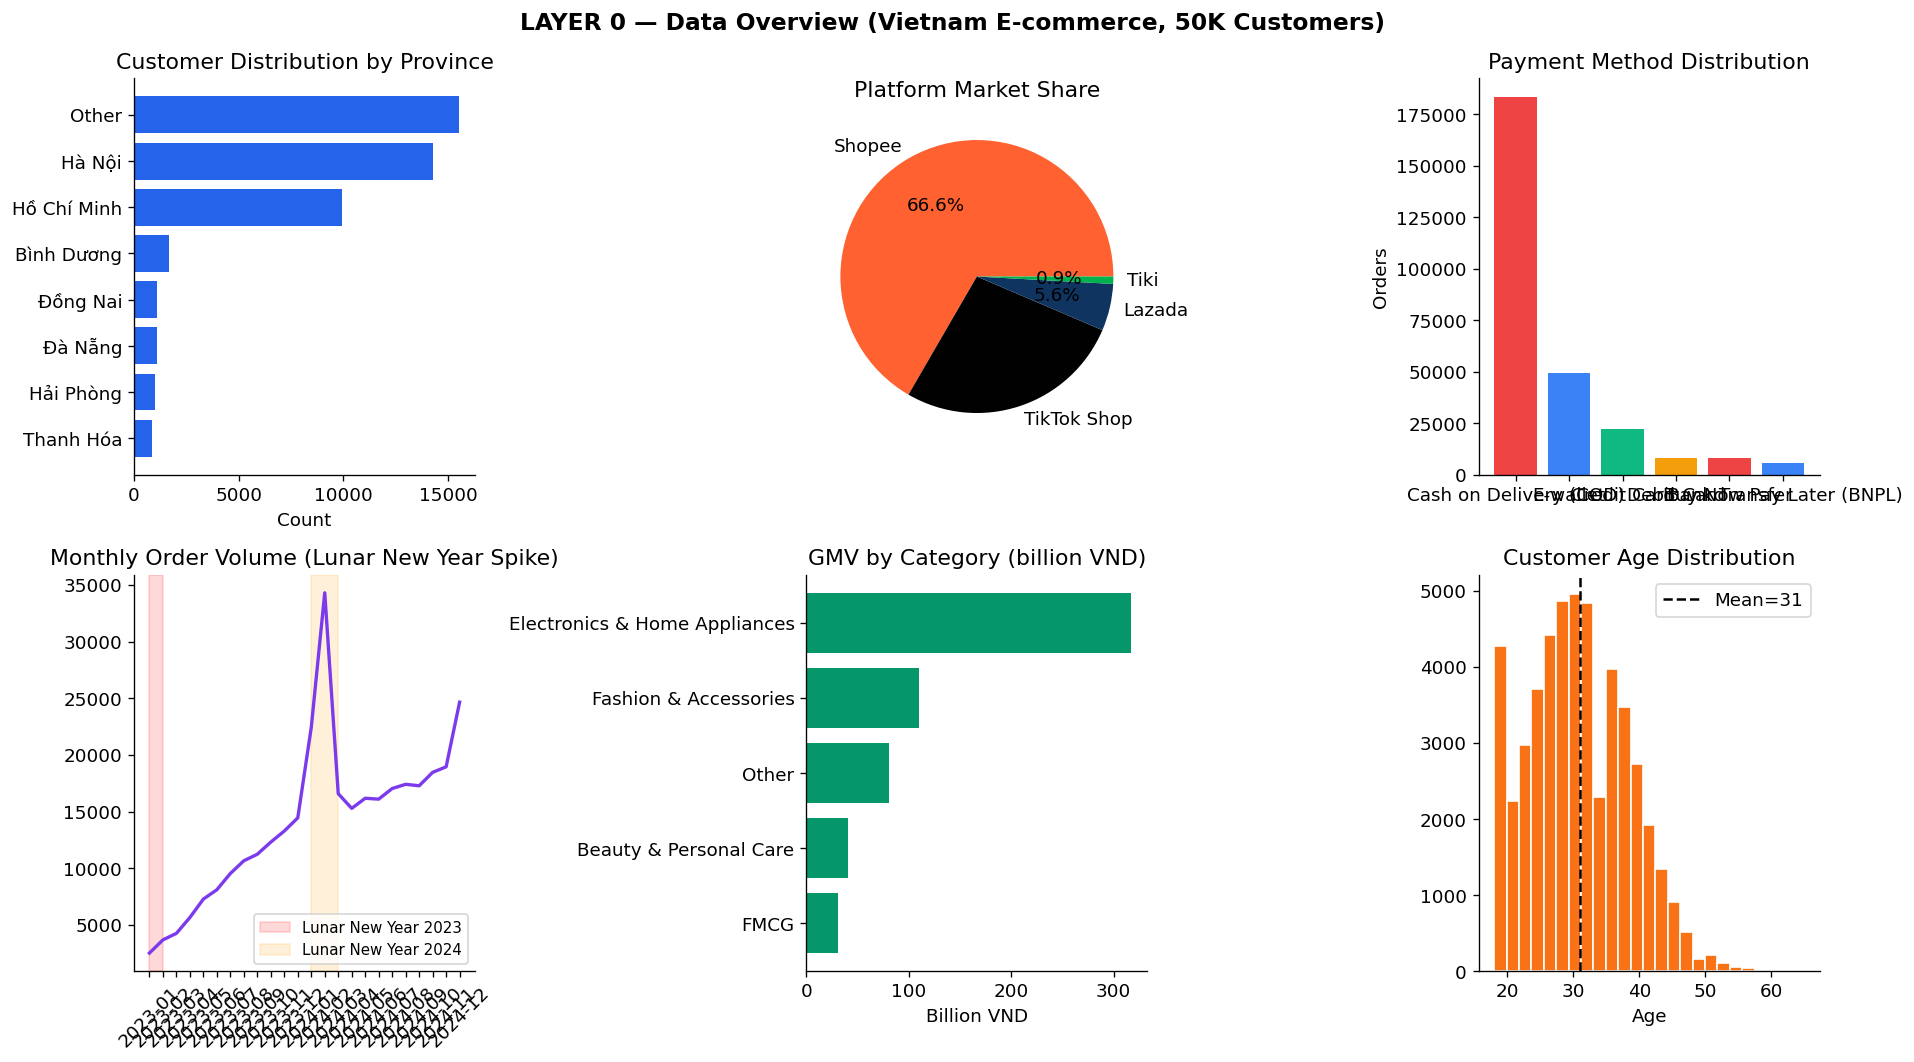

Layer 0 complete 


In [6]:
#Vietnam-specific constants
# Minimal imports so this cell runs on its own (no dependency on earlier cells)
import random, json
from datetime import datetime, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from faker import Faker

# Calibration parameters: read from vn_calibration_en.json (source: Bang_tong_hop_input_Buoc3.md, STT column)
import json as _json
with open('vn_calibration_en.json', encoding='utf-8') as _f:
    CAL = _json.load(_f)

_sim = CAL['simulation']
N_CUSTOMERS = _sim['N_CUSTOMERS']
SIM_START   = datetime.fromisoformat(_sim['SIM_START'])
SIM_END     = datetime.fromisoformat(_sim['SIM_END'])
SNAPSHOT    = datetime.fromisoformat(_sim['ANALYSIS_DATE'])   # analysis date (Step 2)
SEED        = _sim['SEED']                                    # RANDOM_STATE = 42

# Province shares: HCMC and Hanoi by GMV (Metric Q1/2024, secondary); remaining provinces by assumed weights
_hcm  = CAL['province_share_gmv']['Hồ Chí Minh']['value']
_hn   = CAL['province_share_gmv']['Hà Nội']['value']
_rest = {k: v for k, v in CAL['province_base_weights_rest'].items() if isinstance(v, (int, float))}
_rest_sum = sum(_rest.values())
VN_PROVINCES = ['Hồ Chí Minh', 'Hà Nội'] + list(_rest.keys())
PROV_WEIGHTS = [_hcm, _hn] + [v / _rest_sum * (1 - _hcm - _hn) for v in _rest.values()]

# Platforms, categories and payment methods (normalised to sum to 1)
PLATFORMS = list(CAL['platform_share'].keys())
PLAT_W    = np.array([CAL['platform_share'][p]['value'] for p in PLATFORMS])
PLAT_W    = PLAT_W / PLAT_W.sum()

CATEGORIES   = list(CAL['category_share'].keys())
CAT_W        = np.array([CAL['category_share'][c]['value'] for c in CATEGORIES])
CAT_W        = CAT_W / CAT_W.sum()
CAT_AOV_MEAN = {c: CAL['category_aov_vnd'][c]['value'] for c in CATEGORIES}

PAYMENT_METHODS = [k for k in CAL['payment_share_by_count'] if not k.startswith('_')]
PAY_W = np.array([CAL['payment_share_by_count'][m]['value'] for m in PAYMENT_METHODS])
PAY_W = PAY_W / PAY_W.sum()          # PCMI rounded values sum to 1.01 → normalised
PAY_DIGITAL = CAL['payment_digital_methods']

# Tết seasonality (SI) and order multipliers
_tet = CAL['tet']
TET_DATES       = [datetime.fromisoformat(d) for d in _tet['dates']]
TET_WINDOW_DAYS = _tet['window_days']
TET_MULT        = _tet['order_multiplier']
MEGA_MULT       = _tet['mega_sale_multiplier']
MEGA_DAYS       = [tuple(x) for x in _tet['mega_sale_days']]
_MAX_MULT       = max(TET_MULT, MEGA_MULT, 1.0)
assert _MAX_MULT <= 3.0, 'Maximum multiplier must be ≤ 3.0 (acceptance probability in random_order_date)'

fake = Faker('vi_VN')
Faker.seed(SEED)

print('Calibration parameters loaded from vn_calibration_en.json')


# Tết spike helper (order-density multiplier)
def tet_multiplier(dt: datetime) -> float:
    """Daily order-density multiplier (parameters: vn_calibration_en.json, 'tet' section).
    Within ±TET_WINDOW_DAYS days around Tết: TET_MULT. On 11/11 and 12/12: MEGA_MULT (assumption).
    """
    for tet in TET_DATES:
        if abs((dt - tet).days) <= TET_WINDOW_DAYS:
            return TET_MULT
    if (dt.month, dt.day) in MEGA_DAYS:
        return MEGA_MULT
    return 1.0

def random_order_date(join_date: datetime) -> datetime:
    days_since = (SIM_END - join_date).days
    if days_since <= 0:
        return join_date
    for _ in range(20):   # rejection sampling for seasonal spike
        d = join_date + timedelta(days=random.randint(0, days_since))
        if random.random() < (tet_multiplier(d) / _MAX_MULT):
            return d
    return join_date + timedelta(days=random.randint(0, days_since))

print('Helper functions loaded')

import re

# Vietnamese name lists & helpers (customer data)
HO = ['Nguyễn', 'Trần', 'Lê', 'Phạm', 'Hoàng', 'Huỳnh', 'Phan',
      'Vũ', 'Võ', 'Đặng', 'Bùi', 'Đỗ', 'Hồ', 'Ngô', 'Dương', 'Lý']

TEN_POOL = [
    'An', 'Anh', 'Bảo', 'Bình', 'Chi', 'Châu', 'Dung', 'Duy',
    'Đức', 'Hà', 'Hải', 'Hoa', 'Hùng', 'Hữu', 'Khoa', 'Lan',
    'Linh', 'Long', 'Mai', 'Minh', 'Nam', 'Nga', 'Nhung', 'Phong',
    'Phú', 'Phương', 'Quân', 'Quang', 'Tấn', 'Thảo', 'Thắng',
    'Thanh', 'Thu', 'Thị', 'Trang', 'Trí', 'Trung', 'Tuấn',
    'Tú', 'Văn', 'Việt', 'Xuân', 'Yến'
]

DOMAINS = ['gmail.com', 'yahoo.com', 'outlook.com', 'hotmail.com']

def vn_to_ascii(text: str) -> str:
    text = text.lower()
    replacements = {
        'à':'a','á':'a','ả':'a','ã':'a','ạ':'a',
        'ă':'a','ắ':'a','ặ':'a','ằ':'a','ẳ':'a','ẵ':'a',
        'â':'a','ấ':'a','ậ':'a','ầ':'a','ẩ':'a','ẫ':'a',
        'đ':'d',
        'è':'e','é':'e','ẻ':'e','ẽ':'e','ẹ':'e',
        'ê':'e','ế':'e','ệ':'e','ề':'e','ể':'e','ễ':'e',
        'ì':'i','í':'i','ỉ':'i','ĩ':'i','ị':'i',
        'ò':'o','ó':'o','ỏ':'o','õ':'o','ọ':'o',
        'ô':'o','ố':'o','ộ':'o','ồ':'o','ổ':'o','ỗ':'o',
        'ơ':'o','ớ':'o','ợ':'o','ờ':'o','ở':'o','ỡ':'o',
        'ù':'u','ú':'u','ủ':'u','ũ':'u','ụ':'u',
        'ư':'u','ứ':'u','ự':'u','ừ':'u','ử':'u','ữ':'u',
        'ỳ':'y','ý':'y','ỷ':'y','ỹ':'y','ỵ':'y',
    }
    for vn, en in replacements.items():
        text = text.replace(vn, en)
    return re.sub(r'[^a-z0-9]', '', text)

def vn_name() -> str:
    ho    = np.random.choice(HO)
    n_dem = np.random.choice([0, 1, 2], p=[0.30, 0.60, 0.10])
    dem   = ' '.join(np.random.choice(TEN_POOL, n_dem, replace=False)) if n_dem > 0 else ''
    ten   = np.random.choice(TEN_POOL)
    return f"{ho} {dem} {ten}".strip() if dem else f"{ho} {ten}"

def vn_email(name: str) -> str:
    base   = vn_to_ascii(name)
    suffix = np.random.choice([
        str(np.random.randint(10, 999)),
        str(np.random.randint(1990, 2005)),
        ''
    ])
    return f"{base}{suffix}@{np.random.choice(DOMAINS)}"

def vn_phone() -> str:
    # Common Vietnamese mobile prefixes
    prefix = np.random.choice([
        '032','033','034','035','036','037','038','039',  # Viettel
        '070','079','077','076','078',                    # Mobifone
        '056','058','089',                                # Vietnamobile / Gmobile
        '090','093','086','096','097','098',              # Viettel (legacy)
        '091','094',                                      # Mobifone (legacy)
        '092',                                            # Vinaphone (legacy)
    ])
    digits = ''.join([str(np.random.randint(0, 10)) for _ in range(7)])
    return f"{prefix}{digits}"

#TABLE 1: customers
np.random.seed(SEED)
random.seed(SEED)

join_dates = [
    SIM_START + timedelta(days=int(d))
    for d in np.random.exponential(scale=300, size=N_CUSTOMERS).clip(0, 730)
]

normalized_prov_weights = np.array(PROV_WEIGHTS) / np.sum(PROV_WEIGHTS)

names = [vn_name() for _ in range(N_CUSTOMERS)]
customers = pd.DataFrame({
    'customer_id':        [f'C{i:06d}' for i in range(N_CUSTOMERS)],
    'name':               names,
    'email':              [vn_email(n) for n in names],
    'phone':              [vn_phone() for _ in range(N_CUSTOMERS)],
    'province':           np.random.choice(VN_PROVINCES, N_CUSTOMERS, p=normalized_prov_weights),
    'gender':             np.random.choice(['Male', 'Female'], N_CUSTOMERS, p=[0.523, 0.477]),
    'age':                np.clip(np.random.normal(31, 8, N_CUSTOMERS).astype(int), 18, 65),
    'platform':           np.random.choice(PLATFORMS, N_CUSTOMERS, p=PLAT_W),
    'join_date':          join_dates,
    'preferred_category': np.random.choice(CATEGORIES, N_CUSTOMERS, p=CAT_W),
})

print(f'customers: {customers.shape}')
customers[['customer_id', 'name', 'email', 'phone', 'province', 'gender', 'age', 'platform']].head(5)

#TABLE 2: products
N_PRODUCTS = 5_000
prod_cats  = np.random.choice(CATEGORIES, N_PRODUCTS, p=CAT_W)
prod_prices = np.array([
    max(5_000, np.random.lognormal(
        np.log(CAT_AOV_MEAN[c]), 0.5
    ))
    for c in prod_cats
])

products = pd.DataFrame({
    'product_id':  [f'P{i:05d}' for i in range(N_PRODUCTS)],
    'category':    prod_cats,
    'price':       prod_prices.round(-2),   # round to nearest 100 VND
    'is_flash_sale': np.random.choice([0, 1], N_PRODUCTS, p=[0.85, 0.15]),
})

print(f'products: {products.shape}')
products.head(3)

#TABLE 3: orders (variable per customer)

rng = np.random.default_rng(SEED)
freq_lambdas = rng.gamma(shape=CAL['purchase_frequency']['gamma_shape'], scale=CAL['purchase_frequency']['gamma_scale'], size=N_CUSTOMERS).clip(CAL['purchase_frequency']['clip_min'], CAL['purchase_frequency']['clip_max'])

order_rows = []
order_id   = 0

for idx, row in customers.iterrows():
    tenure_years = max((SIM_END - row['join_date']).days / 365, 0.01)
    n_orders = max(1, int(rng.poisson(freq_lambdas[idx] * tenure_years)))

    for _ in range(n_orders):
        odate = random_order_date(row['join_date'])
        order_rows.append({
            'order_id':    f'O{order_id:08d}',
            'customer_id': row['customer_id'],
            'order_date':  odate,
            'platform':    row['platform'],
            'status':      np.random.choice(
                ['completed', 'returned', 'cancelled'],
                p=[0.82, 0.10, 0.08]
            ),
        })
        order_id += 1

orders = pd.DataFrame(order_rows)
print(f'orders: {orders.shape}  (avg {len(orders)/N_CUSTOMERS:.1f} per customer)')
orders.head(3)

#TABLE 4: order_items (vectorized ~50x faster)
rng2 = np.random.default_rng(SEED)

# Pre-index products by category
cat_idx = {c: products[products['category'] == c].index.to_numpy()
           for c in products['category'].unique()}
all_idx = products.index.to_numpy()

n_orders    = len(orders)
n_items_arr = rng2.integers(1, 5, size=n_orders)
total       = int(n_items_arr.sum())

# Repeat order rows
order_rep = orders.loc[orders.index.repeat(n_items_arr)].reset_index(drop=True)

# Category selection
pref_cats = order_rep['customer_id'].map(
    customers.set_index('customer_id')['preferred_category']
).to_numpy()
rand_cats  = rng2.choice(CATEGORIES, size=total, p=CAT_W)
use_pref   = rng2.random(total) < 0.6
chosen_cat = np.where(use_pref & (pref_cats != None), pref_cats, rand_cats)

# Sample one product per row
chosen_prod_idx = np.array([
    rng2.choice(cat_idx.get(c, all_idx)) for c in chosen_cat
])
chosen_prod = products.loc[chosen_prod_idx].reset_index(drop=True)

# Qty & discount
qty      = rng2.integers(1, 4, size=total)
disc_map = np.array([0, 0.05, 0.10, 0.15, 0.20])
discount = disc_map[rng2.choice(5, size=total, p=[0.55,0.15,0.15,0.10,0.05])]

prices = chosen_prod['price'].to_numpy()
order_items = pd.DataFrame({
    'item_id':    [f'I{i:09d}' for i in range(total)],
    'order_id':   order_rep['order_id'].to_numpy(),
    'product_id': chosen_prod['product_id'].to_numpy(),
    'category':   chosen_cat,
    'quantity':   qty,
    'unit_price': prices,
    'discount':   discount,
    'line_total': np.round(prices * qty * (1 - discount), -2),
})

print(f'order_items: {order_items.shape}')
order_items.head(3)

#TABLE 5: payments
order_totals = (
    order_items[order_items['order_id'].isin(
        orders[orders['status'] == 'completed']['order_id']
    )]
    .groupby('order_id')['line_total'].sum()
    .reset_index()
    .rename(columns={'line_total': 'amount'})
)

payments = order_totals.copy()
payments['payment_id'] = [f'PAY{i:08d}' for i in range(len(payments))]

order_date_map = orders.set_index('order_id')['order_date']
order_cust_map = orders.set_index('order_id')['customer_id']
cust_prov_map  = customers.set_index('customer_id')['province']

payments['_province'] = (
    payments['order_id']
    .map(order_cust_map)
    .map(cust_prov_map)
)

urban = payments['_province'].isin(['Hồ Chí Minh', 'Hà Nội', 'Đà Nẵng'])
n_urban  = int(urban.sum())
n_rural  = int((~urban).sum())

#Payment method mix
PAY_W = np.array(PAY_W, dtype=float)

# ASSUMPTION:
#   urban buyers tilt toward digital methods, COD under-weighted vs national.
#   Direction is supported qualitatively; magnitudes are simulation parameters.
URBAN_TILT = np.array([0.8, 1.6, 1.6, 1.6, 1.6, 1.6])

s = n_urban / (n_urban + n_rural)

for k in np.linspace(1.0, 0.0, 21):
    p_urban = PAY_W * (1 + k * (URBAN_TILT - 1))
    p_urban = p_urban / p_urban.sum()
    p_rural = (PAY_W - s * p_urban) / (1 - s) if s < 1 else PAY_W
    if (p_rural >= 0).all():
        break
p_rural = p_rural / p_rural.sum()
print(f'urban share={s:.1%}, tilt strength={k:.2f}')

payments['method'] = None
if n_urban:
    payments.loc[urban,  'method'] = np.random.choice(
        PAYMENT_METHODS, n_urban, p=p_urban)
if n_rural:
    payments.loc[~urban, 'method'] = np.random.choice(
        PAYMENT_METHODS, n_rural, p=p_rural)

base_dates = payments['order_id'].map(order_date_map)
rand_hours = pd.to_timedelta(
    np.random.randint(0, 49, size=len(payments)), unit='h'
)
payments['payment_date'] = base_dates + rand_hours

payments = payments.drop(columns=['_province'])

print(f'payments: {payments.shape}')
print(payments['method'].value_counts(normalize=True).round(3))
payments[['payment_id','order_id','amount','method']].head(3)

#Layer 0 Summary EDA
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('LAYER 0 — Data Overview (Vietnam E-commerce, 50K Customers)', fontsize=14, fontweight='bold')

#Province distribution
prov_cnt = customers['province'].value_counts().head(8)
axes[0,0].barh(prov_cnt.index[::-1], prov_cnt.values[::-1], color='#2563EB')
axes[0,0].set_title('Customer Distribution by Province')
axes[0,0].set_xlabel('Count')

#Platform share
plat_cnt = customers['platform'].value_counts()
axes[0,1].pie(plat_cnt, labels=plat_cnt.index, autopct='%1.1f%%',
              colors=['#FF6130','#010101','#0F3460','#00B14F'])
axes[0,1].set_title('Platform Market Share')

#Payment method
pay_cnt = payments['method'].value_counts()
axes[0,2].bar(pay_cnt.index, pay_cnt.values,
              color=['#EF4444','#3B82F6','#10B981','#F59E0B'])
axes[0,2].set_title('Payment Method Distribution')
axes[0,2].set_ylabel('Orders')

#4. Monthly order volume
orders['ym'] = orders['order_date'].dt.to_period('M')
monthly = orders.groupby('ym').size()
axes[1,0].plot(monthly.index.astype(str), monthly.values, color='#7C3AED', linewidth=2)
axes[1,0].axvspan(monthly.index.astype(str)[0], '2023-02',
                   alpha=0.15, color='red', label='Lunar New Year 2023')
axes[1,0].axvspan('2024-01', '2024-03', alpha=0.15, color='orange', label='Lunar New Year 2024')
axes[1,0].set_title('Monthly Order Volume (Lunar New Year Spike)')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(fontsize=9)

#Top categories by GMV
cat_gmv = (
    order_items.merge(orders[['order_id','status']], on='order_id')
    .query("status == 'completed'")
    .groupby('category')['line_total'].sum()
    .sort_values(ascending=True)
)
axes[1,1].barh(cat_gmv.index, cat_gmv.values / 1e9, color='#059669')
axes[1,1].set_title('GMV by Category (billion VND)')
axes[1,1].set_xlabel('Billion VND')

#Age distribution
axes[1,2].hist(customers['age'], bins=25, color='#F97316', edgecolor='white')
axes[1,2].axvline(31, color='black', linestyle='--', label='Mean=31')
axes[1,2].set_title('Customer Age Distribution')
axes[1,2].set_xlabel('Age')
axes[1,2].legend()

plt.tight_layout()
plt.savefig('layer0_eda.png', dpi=120, bbox_inches='tight')
plt.show()
print('Layer 0 complete ')

---
# LAYER 1 — Customer Segmentation (RFM-D)

**8 features**: R (Recency), F (Frequency), M (Monetary), D (Digital payment ratio),
SI (Seasonal Index), PD (Product Diversity), GS (Geographic Score), T (Tenure)

**Algorithm comparison**: K-Means (Elbow + Silhouette, K=2–10) vs GMM (EM + BIC)

**Target**: 5 segments → VIP | Regular | New | At-Risk | One-time

RFM-D: 50,000 customers; eligible for clustering (≥2 transactions): 44,157
  K=2 | Silhouette=0.314 | DB=1.334 | GMM BIC min=-496205.3 | seed spread=0.0
  K=3 | Silhouette=0.287 | DB=1.305 | GMM BIC min=-675949.4 | seed spread=107395.3
  K=4 | Silhouette=0.279 | DB=1.364 | GMM BIC min=-824685.2 | seed spread=116366.4
  K=5 | Silhouette=0.263 | DB=1.398 | GMM BIC min=-965324.2 | seed spread=46144.2
  K=6 | Silhouette=0.260 | DB=1.395 | GMM BIC min=-1011193.0 | seed spread=39467.2
  K=7 | Silhouette=0.265 | DB=1.277 | GMM BIC min=-1041742.1 | seed spread=24972.2
  K=8 | Silhouette=0.274 | DB=1.252 | GMM BIC min=-1080727.2 | seed spread=36890.1

Selected k per Step 2 rule: K=2 (Silhouette=0.314, DB=1.334)


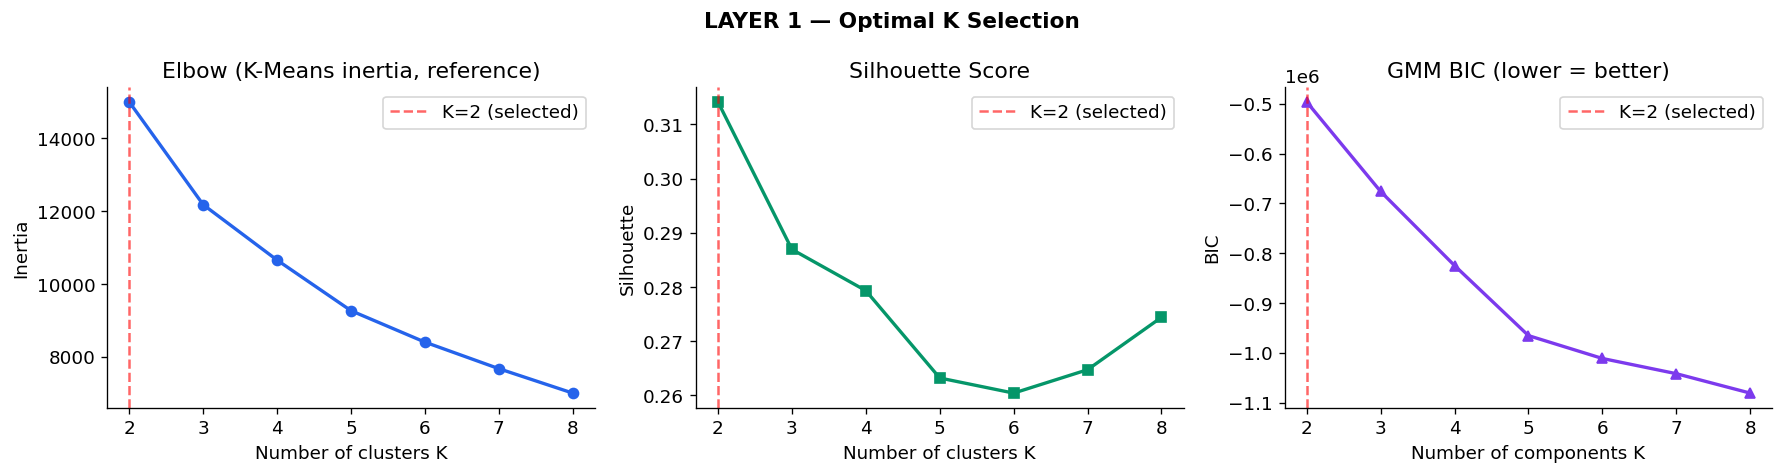


K-Means (main model)    | Silhouette=0.3141 | Davies-Bouldin=1.3339
GMM (comparison)        | Silhouette=0.3141 | Davies-Bouldin=1.3347
             count  avg_recency  avg_frequency  avg_monetary  avg_tenure
cluster_raw                                                             
0.0          21898        100.8           11.0     9267267.3       485.1
1.0          22259        102.4           10.6     8855452.7       477.6
Labels: {0.0: 'VIP', 1.0: 'At-Risk'}

Segment distribution:
segment
At-Risk    22259
VIP        21898
New         5843
Name: count, dtype: int64
  [OK] Payment method Cash on Delivery (COD): target=0.6634 | actual=0.6624 | deviation=-0.0010 (tolerance ±0.02)
  [OK] Payment method E-wallet: target=0.1782 | actual=0.1788 | deviation=+0.0006 (tolerance ±0.02)
  [OK] Payment method Credit Card: target=0.0792 | actual=0.0797 | deviation=+0.0005 (tolerance ±0.02)
  [OK] Payment method Debit Card: target=0.0297 | actual=0.0300 | deviation=+0.0003 (tolerance ±0.02)
  [OK] 

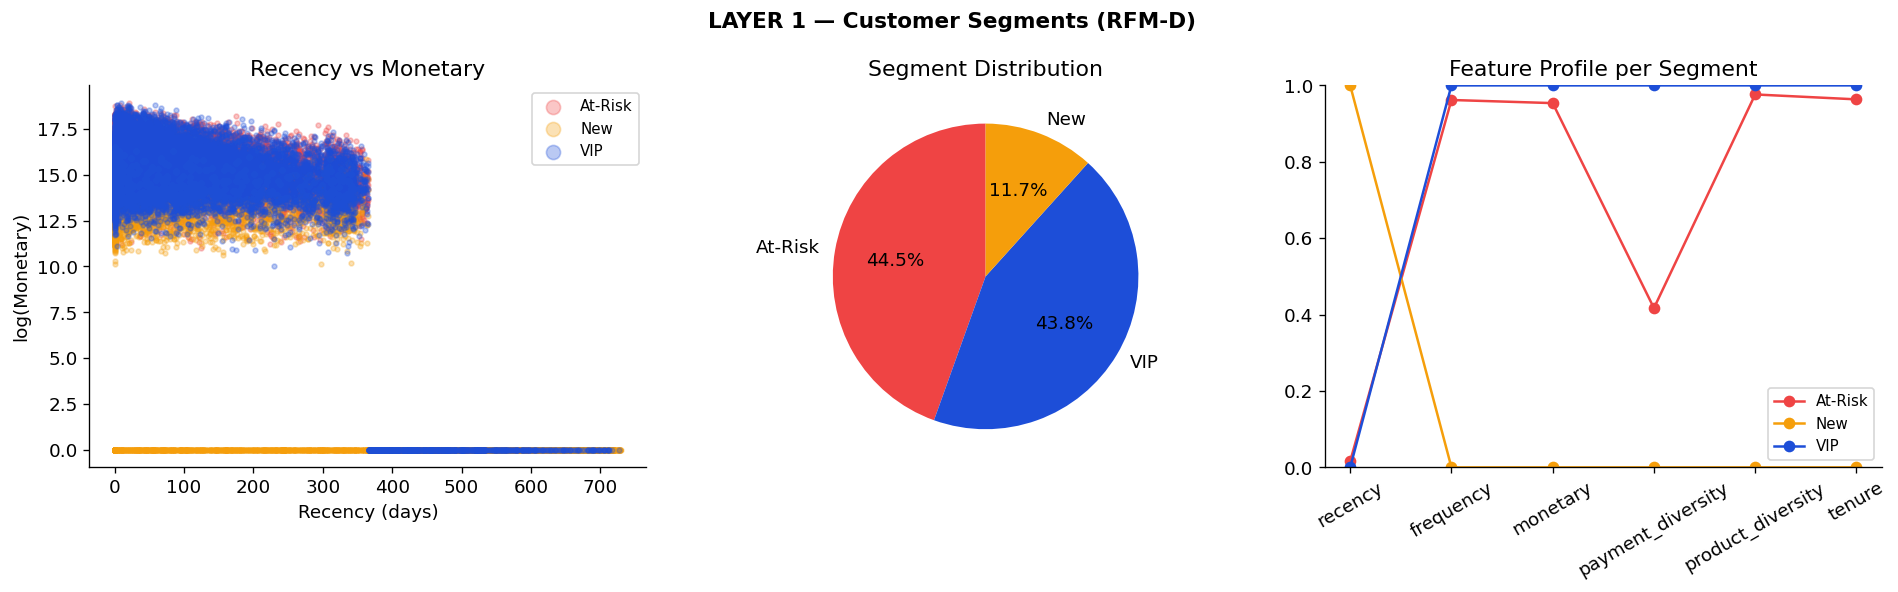

Layer 1 complete 


In [9]:
# ---------------------------------------------------------------------------
# RFM-D per Step 2 (Quy_tac_tinh_toan_RFM-D.md)
#   Analysis date A = SNAPSHOT. 12-month window W12 = (A − 12 months, A].
#   R: days from the latest completed transaction to A (full data window)
#   F: number of transaction lines (order_items) in W12
#   M: sum of line_total in W12
#   D: number of categories bought in W12 / total number of categories in the filtered data
#   SI, PD, GS, T: per the research model. PD = Shannon entropy (bits) of payment methods
#   Filter: only customers with ≥ 2 transaction lines in the full window enter clustering.
#   Other customers are labelled 'New'. Customers with no purchase in 12 months are kept (F = M = D = 0).
# ---------------------------------------------------------------------------
RFM_RULES = CAL['rfmd_rules']
W12_START = SNAPSHOT - pd.DateOffset(months=RFM_RULES['f_m_window_months'])
FEATURE_COLS = ['recency', 'frequency', 'monetary', 'product_diversity',
                'seasonal_index', 'payment_diversity', 'geo_score', 'tenure']

completed_orders = orders[orders['status'] == 'completed'].copy()

# Order totals (kept for later layers)
order_value = order_items.groupby('order_id')['line_total'].sum().reset_index()
order_value.columns = ['order_id', 'order_value']
completed_orders = completed_orders.merge(order_value, on='order_id', how='left')
completed_orders['order_date'] = pd.to_datetime(completed_orders['order_date'])

# Step 1: time window; transaction lines
rfm_orders = completed_orders[(completed_orders['order_date'] >= SIM_START) &
                              (completed_orders['order_date'] <= SNAPSHOT)]
rfm_lines = order_items.merge(rfm_orders[['order_id', 'customer_id', 'order_date']],
                              on='order_id', how='inner')
rfm_log = {'customers_total': int(customers.shape[0]),
           'orders_total': int(len(orders)),
           'orders_completed_in_window': int(len(rfm_orders)),
           'lines_in_window': int(len(rfm_lines)),
           'gift_card_filter': 'not applied (simulated data has no gift cards)'}

# Step 3: customers with ≥ 2 transaction lines in the full window
_n_lines = rfm_lines.groupby('customer_id').size()
eligible_ids = _n_lines[_n_lines >= RFM_RULES['min_transactions']].index
rfm_log['customers_eligible_ge2_lines'] = int(len(eligible_ids))

# Step 4: features for all customers (shared by ML and CLV); clustering uses eligible customers only
ix = pd.Index(customers['customer_id'].values, name='customer_id')
join_dt = pd.to_datetime(customers.set_index('customer_id')['join_date']).reindex(ix)

last_date = rfm_orders.groupby('customer_id')['order_date'].max().reindex(ix)
recency = (SNAPSHOT - last_date).dt.days.fillna((SNAPSHOT - join_dt).dt.days).rename('recency')

lines_w12 = rfm_lines[(rfm_lines['order_date'] > W12_START) & (rfm_lines['order_date'] <= SNAPSHOT)]
frequency = lines_w12.groupby('customer_id').size().reindex(ix, fill_value=0).rename('frequency')
monetary  = lines_w12.groupby('customer_id')['line_total'].sum().reindex(ix, fill_value=0).rename('monetary')

n_cat_total = rfm_lines['category'].nunique()
cat_w12 = lines_w12.groupby('customer_id')['category'].nunique().reindex(ix, fill_value=0)
product_diversity = (cat_w12 / n_cat_total).rename('product_diversity')

tet_mask = np.zeros(len(rfm_lines), dtype=bool)
for _t in TET_DATES:
    tet_mask |= ((rfm_lines['order_date'] - _t).abs().dt.days.to_numpy() <= TET_WINDOW_DAYS)
seasonal_index = (pd.Series(tet_mask, index=rfm_lines.index)
                  .groupby(rfm_lines['customer_id']).mean()
                  .reindex(ix, fill_value=0).rename('seasonal_index'))

pay_map = payments.merge(rfm_orders[['order_id', 'customer_id']], on='order_id', how='inner')
_cnt = pay_map.groupby(['customer_id', 'method']).size().unstack(fill_value=0)
_p = _cnt.div(_cnt.sum(axis=1), axis=0)
payment_diversity = (-(_p * np.log2(_p.where(_p > 0, 1.0))).sum(axis=1)
                     ).reindex(ix, fill_value=0).rename('payment_diversity')
digital_ratio = (pay_map.assign(_d=pay_map['method'].isin(PAY_DIGITAL).astype(int))
                 .groupby('customer_id')['_d'].mean().reindex(ix).rename('digital_ratio'))

GS_TIERS = CAL['geo_score_tier']['tiers']
geo_score = (customers.set_index('customer_id')['province']
             .map(lambda p: GS_TIERS.get(p, 1)).reindex(ix).rename('geo_score'))
tenure = (SNAPSHOT - join_dt).dt.days.rename('tenure')

rfmd = pd.concat([recency, frequency, monetary, product_diversity, seasonal_index,
                  payment_diversity, geo_score, tenure, digital_ratio], axis=1)
rfmd.index.name = 'customer_id'
rfmd['eligible'] = rfmd.index.isin(eligible_ids)
rfm_log['rfmd_rows'] = int(len(rfmd))

# Min-max scaling (Step 2): min and max computed on eligible customers
_elig = rfmd.loc[rfmd['eligible'], FEATURE_COLS]
_mn, _mx = _elig.min(), _elig.max()
_span = _mx - _mn
if (_span == 0).any():
    print('Warning: constant columns, set to 0:', list(_span[_span == 0].index))
X_df = ((_elig - _mn) / _span.replace(0, np.nan)).fillna(0.0)
X = X_df.to_numpy()
print(f'RFM-D: {len(rfmd):,} customers; eligible for clustering (≥2 transactions): {X.shape[0]:,}')

# ---------------------------------------------------------------------------
# Clustering per Step 2: K-Means is the main model, k = 2..8.
# Choose k: highest Silhouette (all customers); ties broken by lower Davies-Bouldin.
# GMM (full covariance, n_init = 10, seeds 0/42/123, lowest BIC) for comparison only.
# ---------------------------------------------------------------------------
from sklearn.metrics import silhouette_score, davies_bouldin_score

K_MIN, K_MAX = RFM_RULES['k_range']
K_RANGE   = range(K_MIN, K_MAX + 1)
KM_N_INIT = RFM_RULES['kmeans_n_init']
GMM_SEEDS = RFM_RULES['gmm_seeds']

inertias, silhouettes, dbs, bics_gmm = [], [], [], []
gmm_seed_spread = {}
for k in K_RANGE:
    km_k = KMeans(n_clusters=k, random_state=SEED, n_init=KM_N_INIT).fit(X)
    lab_k = km_k.labels_
    inertias.append(km_k.inertia_)
    silhouettes.append(silhouette_score(X, lab_k))
    dbs.append(davies_bouldin_score(X, lab_k))
    bics = [GaussianMixture(n_components=k, covariance_type='full', n_init=KM_N_INIT,
                            random_state=s).fit(X).bic(X) for s in GMM_SEEDS]
    bics_gmm.append(min(bics))
    gmm_seed_spread[k] = max(bics) - min(bics)
    print(f'  K={k} | Silhouette={silhouettes[-1]:.3f} | DB={dbs[-1]:.3f} | '
          f'GMM BIC min={min(bics):.1f} | seed spread={gmm_seed_spread[k]:.1f}')

ks = np.array(list(K_RANGE))
sil_r = np.round(np.array(silhouettes), 3)
cands = [i for i in range(len(ks)) if sil_r[i] == sil_r.max()]
best_idx = min(cands, key=lambda i: dbs[i])
BEST_K = int(ks[best_idx])
print(f'\nSelected k per Step 2 rule: K={BEST_K} '
      f'(Silhouette={silhouettes[best_idx]:.3f}, DB={dbs[best_idx]:.3f})')

# k-selection plots (1 × 3 layout kept from the previous version)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('LAYER 1 — Optimal K Selection', fontsize=13, fontweight='bold')
k_list = list(K_RANGE)

axes[0].plot(k_list, inertias, 'o-', color='#2563EB', linewidth=2)
axes[0].axvline(BEST_K, color='red', linestyle='--', alpha=0.6, label=f'K={BEST_K} (selected)')
axes[0].set_title('Elbow (K-Means inertia, reference)')
axes[0].set_xlabel('Number of clusters K')
axes[0].set_ylabel('Inertia')
axes[0].legend()

axes[1].plot(k_list, silhouettes, 's-', color='#059669', linewidth=2)
axes[1].axvline(BEST_K, color='red', linestyle='--', alpha=0.6, label=f'K={BEST_K} (selected)')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters K')
axes[1].set_ylabel('Silhouette')
axes[1].legend()

axes[2].plot(k_list, bics_gmm, '^-', color='#7C3AED', linewidth=2)
axes[2].axvline(BEST_K, color='red', linestyle='--', alpha=0.6, label=f'K={BEST_K} (selected)')
axes[2].set_title('GMM BIC (lower = better)')
axes[2].set_xlabel('Number of components K')
axes[2].set_ylabel('BIC')
axes[2].legend()

plt.tight_layout()
plt.savefig('layer1_k_selection.png', dpi=120, bbox_inches='tight')
plt.show()

# Final model: K-Means (n_init = 10, random_state = 42)
km_final = KMeans(n_clusters=BEST_K, random_state=SEED, n_init=KM_N_INIT)
km_labels = km_final.fit_predict(X)
sil_km = silhouette_score(X, km_labels)
db_km  = davies_bouldin_score(X, km_labels)

# GMM comparison: pick the seed with the lowest BIC
gm_fits   = [GaussianMixture(n_components=BEST_K, covariance_type='full', n_init=KM_N_INIT,
                             random_state=s).fit(X) for s in GMM_SEEDS]
gm_final  = min(gm_fits, key=lambda g: g.bic(X))
gm_labels = gm_final.predict(X)
sil_gm = silhouette_score(X, gm_labels)
db_gm  = davies_bouldin_score(X, gm_labels)

print(f'\nK-Means (main model)    | Silhouette={sil_km:.4f} | Davies-Bouldin={db_km:.4f}')
print(f'GMM (comparison)        | Silhouette={sil_gm:.4f} | Davies-Bouldin={db_gm:.4f}')

rfmd['cluster_raw'] = pd.Series(km_labels, index=X_df.index)

# Cluster profiles and labels (sorted by average spend)
cluster_stats = (rfmd[rfmd['eligible']].groupby('cluster_raw')
                 .agg(count=('recency', 'count'),
                      avg_recency=('recency', 'mean'),
                      avg_frequency=('frequency', 'mean'),
                      avg_monetary=('monetary', 'mean'),
                      avg_tenure=('tenure', 'mean'))
                 .round(1))
print(cluster_stats)

# Labels assigned by average-spend rank, not by the value of k:
#   highest-spend cluster → 'VIP'; lowest-spend cluster → 'At-Risk'; all others → 'Regular'.
# These labels match the Layer 4 strategy templates (TEMPLATE_STRATEGIES).
_order = cluster_stats['avg_monetary'].sort_values(ascending=False).index.tolist()
SEGMENT_NAMES = {c: 'Regular' for c in _order}
SEGMENT_NAMES[_order[0]] = 'VIP'
if len(_order) > 1:
    SEGMENT_NAMES[_order[-1]] = 'At-Risk'
print('Labels:', SEGMENT_NAMES)

# Customers with < 2 transactions (not clustered) are labelled 'New'
rfmd['segment'] = rfmd['cluster_raw'].map(SEGMENT_NAMES).fillna('New')

if 'segment' in customers.columns:
    customers = customers.drop(columns=['segment'])
customers = customers.merge(rfmd['segment'].reset_index(), on='customer_id', how='left')
customers['segment'] = customers['segment'].fillna('New')

seg_dist = customers['segment'].value_counts()
print('\nSegment distribution:')
print(seg_dist)

# ---------------------------------------------------------------------------
# Automatic checks: does the generated data reproduce the Step 3 parameters?
# Deviations outside the tolerance are flagged DEVIATION in calibration_log.json so vn_calibration_en.json can be adjusted.
# ---------------------------------------------------------------------------
TOL = CAL['validation_tolerance']
calib_checks = []


def _check(name, target, actual, tol, rel=False):
    dev = (actual / target - 1) if rel else (actual - target)
    ok = abs(dev) <= tol
    calib_checks.append({'check': name, 'target': round(float(target), 4),
                         'actual': round(float(actual), 4), 'deviation': round(float(dev), 4),
                         'tolerance': tol, 'status': 'OK' if ok else 'DEVIATION'})
    print(f"  [{'OK' if ok else 'DEVIATION'}] {name}: target={target:.4f} | "
          f"actual={actual:.4f} | deviation={dev:+.4f} (tolerance ±{tol})")
    return ok


# 1. Payment method shares (by transaction count, completed orders)
pay_share = payments['method'].value_counts(normalize=True)
for _m, _w in zip(PAYMENT_METHODS, PAY_W):
    _check(f'Payment method {_m}', _w, pay_share.get(_m, 0.0), TOL['cod_share_abs'])

# 2. Tết peak (2024): orders/day inside the Tết window vs normal days
_d = orders[(orders['status'] == 'completed')].copy()
_d['d'] = pd.to_datetime(_d['order_date']).dt.normalize()
_d = _d[_d['d'].dt.year == 2024]
_daily = _d.groupby('d').size().reindex(pd.date_range('2024-01-01', '2024-12-31'), fill_value=0)
_in_tet = np.zeros(len(_daily), dtype=bool)
for _t in TET_DATES:
    _in_tet |= (np.abs((_daily.index - _t).days) <= TET_WINDOW_DAYS)
_mega = np.array([(dt.month, dt.day) in MEGA_DAYS for dt in _daily.index])
_base = ~_in_tet & ~_mega
tet_ratio = _daily[_in_tet].mean() / _daily[_base].mean()
_check('Orders/day ratio: Tết window ÷ normal days (2024)', TET_MULT, tet_ratio,
       TOL['tet_ratio_rel'], rel=True)

# 3. Province distribution: customer share and GMV share
_cust_prov = customers.set_index('customer_id')['province']
_prov_share = customers['province'].value_counts(normalize=True)
for _p_name, _w in zip(VN_PROVINCES[:2], PROV_WEIGHTS[:2]):
    _check(f'Customer share {_p_name}', _w, _prov_share.get(_p_name, 0.0),
           TOL['province_gmv_share_abs'])
_gmv_prov = completed_orders.groupby(completed_orders['customer_id'].map(_cust_prov))['order_value'].sum()
_gmv_share = _gmv_prov / _gmv_prov.sum()
for _p_name in ['Hồ Chí Minh', 'Hà Nội']:
    _check(f'GMV share {_p_name}', CAL['province_share_gmv'][_p_name]['value'],
           _gmv_share.get(_p_name, 0.0), TOL['province_gmv_share_abs'])

calib_log = {
    'generated_at': datetime.now().isoformat(timespec='seconds'),
    'params_file': 'vn_calibration_en.json',
    'checks': calib_checks,
    'checks_ok': int(sum(c['status'] == 'OK' for c in calib_checks)),
    'checks_total': int(len(calib_checks)),
    'rfm_filter': rfm_log,
    'best_k': BEST_K,
    'silhouette_best': round(float(silhouettes[best_idx]), 4),
    'davies_bouldin_best': round(float(dbs[best_idx]), 4),
    'gmm_seed_spread': {int(k): round(float(v), 2) for k, v in gmm_seed_spread.items()},
}
with open('calibration_log.json', 'w', encoding='utf-8') as _f:
    json.dump(calib_log, _f, indent=2, ensure_ascii=False)
print(f"\nCalibration checks: {calib_log['checks_ok']}/{calib_log['checks_total']} OK "
      f"→ written to calibration_log.json")


#Segment visualisation
COLORS = {
    'VIP':      '#1D4ED8',
    'Regular':  '#059669',
    'New':      '#F59E0B',
    'At-Risk':  '#EF4444',
    'One-time': '#6B7280',
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('LAYER 1 — Customer Segments (RFM-D)', fontsize=13, fontweight='bold')

seg_data = rfmd.copy()
# Scatter: Recency vs Monetary
for seg, grp in seg_data.groupby('segment'):
    axes[0].scatter(grp['recency'], np.log1p(grp['monetary']),
                    alpha=0.3, s=8, label=seg, color=COLORS[seg])
axes[0].set_xlabel('Recency (days)')
axes[0].set_ylabel('log(Monetary)')
axes[0].set_title('Recency vs Monetary')
axes[0].legend(markerscale=3, fontsize=9)
# Pie chart
seg_cnt = seg_data['segment'].value_counts()
axes[1].pie(seg_cnt, labels=seg_cnt.index,
            colors=[COLORS[s] for s in seg_cnt.index],
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Segment Distribution')
# Radar / spider chart
features  = ['recency', 'frequency', 'monetary', 'payment_diversity', 'product_diversity', 'tenure']
seg_means = seg_data.groupby('segment')[features].mean()
seg_norm  = (seg_means - seg_means.min()) / (seg_means.max() - seg_means.min() + 1e-9)

for seg, row in seg_norm.iterrows():
    axes[2].plot(features, row.values, 'o-', label=seg, color=COLORS[seg], linewidth=1.5)
axes[2].set_title('Feature Profile per Segment')
axes[2].tick_params(axis='x', rotation=30)
axes[2].legend(fontsize=9)
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.savefig('layer1_segments.png', dpi=120, bbox_inches='tight')
plt.show()
print('Layer 1 complete ')

---
# LAYER 2 — CLV & Churn Risk Prediction

**Labels**:
- Y₁ — CLV (6-month future spend, regression)
- Y₂ — Churn flag (no order in next 90 days, classification)

**Pipeline**: SMOTE → XGBoost → Grid Search CV (5-fold) → SHAP

**Target metrics**: R² ≥ 0.85 (CLV) | AUC-ROC ≥ 0.90 | F1 ≥ 0.85 (Churn)

Feature matrix: (36144, 13)
Churn rate: 45.17%
CLV Regression R²: 0.3575
After SMOTE: [15815 15815]
Best params : {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 400}
AUC-ROC     : 0.7570
F1-Score    : 0.6447

Classification Report:
              precision    recall  f1-score   support

      Active       0.71      0.73      0.72      4002
     Churned       0.66      0.63      0.64      3227

    accuracy                           0.69      7229
   macro avg       0.69      0.68      0.68      7229
weighted avg       0.69      0.69      0.69      7229



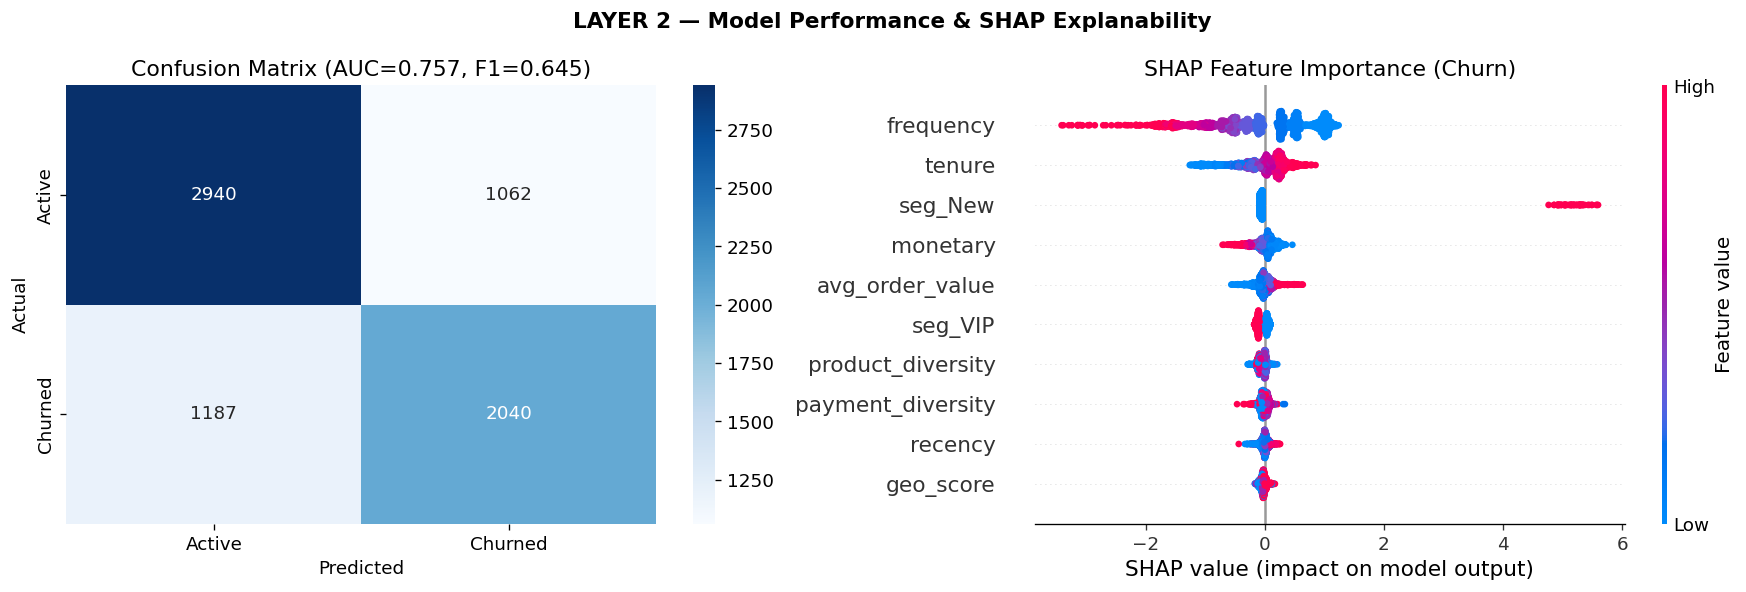

Raw CLV predictions below 0: 0 (clipped to 0)
Layer 2 complete 


In [10]:
#Build supervised labels
CUTOFF = datetime(2024, 7, 1)
train_orders = completed_orders[completed_orders['order_date'] < CUTOFF]
future_orders = completed_orders[completed_orders['order_date'] >= CUTOFF]
# Y1 — CLV
clv_6m = (
    future_orders.groupby('customer_id')['order_value'].sum()
    .rename('clv_6m')
)
# Y2 — Churn
has_order_90d = (
    future_orders[
        future_orders['order_date'] <= CUTOFF + timedelta(days=90)
    ]['customer_id'].unique()
)
# Build training features from pre-cutoff history
def build_features(order_df, snap_date):
    r = (
        order_df.groupby('customer_id')['order_date'].max()
        .apply(lambda d: (snap_date - d).days)
        .rename('recency')
    )
    f = order_df.groupby('customer_id').size().rename('frequency')
    m = order_df.groupby('customer_id')['order_value'].sum().rename('monetary')
    avg = order_df.groupby('customer_id')['order_value'].mean().rename('avg_order_value')
    return pd.concat([r, f, m, avg], axis=1)
X_base = build_features(train_orders, CUTOFF)

# Model features (D, SI, PD) built from pre-cutoff orders only, to avoid label leakage
pre_lines = order_items.merge(train_orders[['order_id', 'customer_id', 'order_date']],
                              on='order_id', how='inner')
pre_w12 = pre_lines[pre_lines['order_date'] > CUTOFF - pd.DateOffset(months=12)]
ix_m = X_base.index

n_cat_all = rfm_lines['category'].nunique()
cat_pre = pre_w12.groupby('customer_id')['category'].nunique().reindex(ix_m, fill_value=0)
D_pre = (cat_pre / n_cat_all).rename('product_diversity')

tet_pre = np.zeros(len(pre_lines), dtype=bool)
for _t in TET_DATES:
    tet_pre |= ((pre_lines['order_date'] - _t).abs().dt.days.to_numpy() <= TET_WINDOW_DAYS)
SI_pre = (pd.Series(tet_pre, index=pre_lines.index)
          .groupby(pre_lines['customer_id']).mean()
          .reindex(ix_m, fill_value=0).rename('seasonal_index'))

pay_pre = payments.merge(train_orders[['order_id', 'customer_id']], on='order_id', how='inner')
_cnt = pay_pre.groupby(['customer_id', 'method']).size().unstack(fill_value=0)
_p = _cnt.div(_cnt.sum(axis=1), axis=0)
PD_pre = (-(_p * np.log2(_p.where(_p > 0, 1.0))).sum(axis=1)
          ).reindex(ix_m, fill_value=0).rename('payment_diversity')

X_full = X_base.join(pd.concat([D_pre, SI_pre, PD_pre], axis=1), how='inner')
X_full = X_full.join(rfmd[['geo_score', 'tenure']], how='inner')

X_full = X_full.join(clv_6m, how='left').fillna(0)
X_full['churn'] = (~X_full.index.isin(has_order_90d)).astype(int)

print(f'Feature matrix: {X_full.shape}')
print(f"Churn rate: {X_full['churn'].mean():.2%}")
X_full.head(3)

#CLV Regression (XGBoost)
# 8 biến RFM-D (Mục 3.5, 3.7): không đưa biến giả phân khúc hay avg_order_value vào mô hình
feature_cols = ['recency', 'frequency', 'monetary', 'product_diversity',
                'seasonal_index', 'payment_diversity', 'geo_score', 'tenure']

Xm = X_full[feature_cols].values
ym_clv   = X_full['clv_6m'].values
ym_churn = X_full['churn'].values

X_tr, X_te, y_clv_tr, y_clv_te = train_test_split(Xm, ym_clv, test_size=0.2, random_state=SEED)
_, _, y_ch_tr, y_ch_te = train_test_split(Xm, ym_churn, test_size=0.2, random_state=SEED)

# XGBoost Regressor
# Không dùng early stopping trên tập kiểm định (tránh rò rỉ); tham số cố định như evaluate_models.py
xgb_reg = xgb.XGBRegressor(
    n_estimators=400, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=SEED
)
xgb_reg.fit(X_tr, y_clv_tr)

pred_clv = xgb_reg.predict(X_te)
r2 = r2_score(y_clv_te, pred_clv)
print(f'CLV Regression R²: {r2:.4f}')

#Churn Classification: SMOTE + XGBoost
sm = SMOTE(random_state=SEED, k_neighbors=5)
X_tr_sm, y_ch_tr_sm = sm.fit_resample(X_tr, y_ch_tr)
print(f'After SMOTE: {np.bincount(y_ch_tr_sm)}')
# Grid Search (lightweight grid)
param_grid = {
    'max_depth':   [4, 6],
    'learning_rate': [0.05, 0.10],
    'n_estimators': [200, 400],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
xgb_clf = xgb.XGBClassifier(
    eval_metric='auc',
    subsample=0.8, colsample_bytree=0.8, random_state=SEED
)
grid = GridSearchCV(xgb_clf, param_grid, cv=cv, scoring='roc_auc',
                    n_jobs=-1, verbose=0)
grid.fit(X_tr_sm, y_ch_tr_sm)

best_clf = grid.best_estimator_
y_prob   = best_clf.predict_proba(X_te)[:, 1]
y_pred   = (y_prob >= 0.5).astype(int)
auc = roc_auc_score(y_ch_te, y_prob)
f1  = f1_score(y_ch_te, y_pred)
print(f'Best params : {grid.best_params_}')
print(f'AUC-ROC     : {auc:.4f}')
print(f'F1-Score    : {f1:.4f}')
print('\nClassification Report:')
print(classification_report(y_ch_te, y_pred, target_names=['Active','Churned']))

#SHAP Explanability
explainer  = shap.TreeExplainer(best_clf)
shap_vals  = explainer.shap_values(X_te[:2000])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('LAYER 2 — Model Performance & SHAP Explanability', fontsize=13, fontweight='bold')
# Confusion matrix
cm = confusion_matrix(y_ch_te, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Active','Churned'], yticklabels=['Active','Churned'])
axes[0].set_title(f'Confusion Matrix (AUC={auc:.3f}, F1={f1:.3f})')
axes[0].set_ylabel('Actual'); axes[0].set_xlabel('Predicted')
# SHAP summary
plt.sca(axes[1])
shap.summary_plot(
    shap_vals, X_te[:2000],
    feature_names=feature_cols,
    show=False, max_display=10, plot_size=None
)
axes[1].set_title('SHAP Feature Importance (Churn)')
plt.tight_layout()
plt.savefig('layer2_model.png', dpi=120, bbox_inches='tight')
plt.show()

# Attach predictions to customers
X_full['churn_prob']   = best_clf.predict_proba(Xm)[:, 1]
# Clip negative CLV predictions to 0: spend cannot be negative, and clv_6m is a sum of order values
raw_clv = xgb_reg.predict(Xm)
print(f"Raw CLV predictions below 0: {(raw_clv < 0).sum():,} (clipped to 0)")
X_full['predicted_clv'] = np.clip(raw_clv, 0, None)
print('Layer 2 complete ')

---
# LAYER 3 — Automated Journey Mapping

**5 stages**: Awareness → Consideration → First Purchase → Retention → Advocacy

Customers are placed on the funnel by Tenure, Recency, and Order count.
Logistic regression computes **drop-off probability** per stage per segment.

Journey stage × segment counts:
segment         At-Risk   New    VIP
stage                               
Advocacy          12873     0  12836
Awareness           907  3055    885
Consideration         0   940      0
First Purchase      661   167    588
Retention          7818  1681   7589
Logistic Regression AUC: 0.9684

Drop-off probability matrix:
segment         At-Risk    New    VIP
stage                                
Awareness         1.000  0.853  1.000
Consideration     0.500  0.410  0.500
First Purchase    0.377  0.665  0.372
Retention         0.883  0.864  0.876
Advocacy          0.132  0.500  0.123


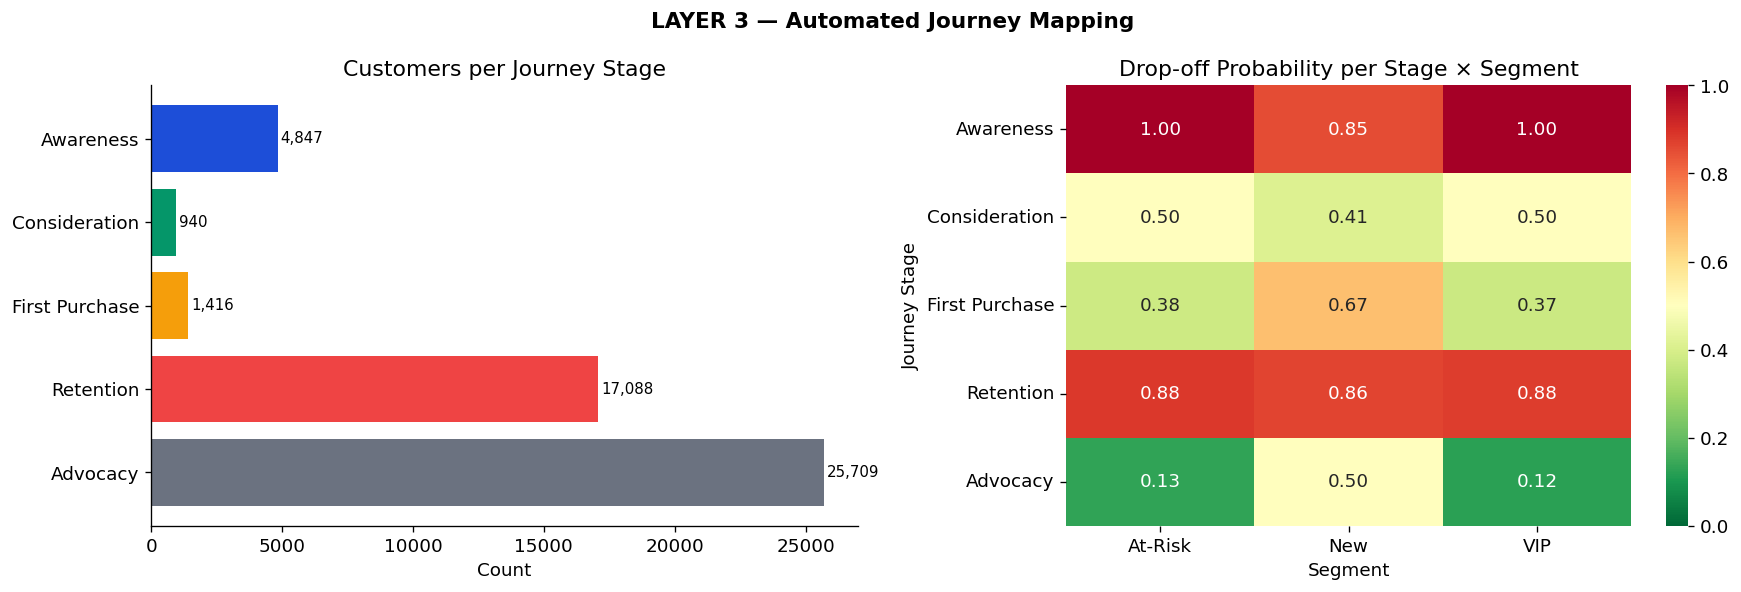

Layer 3 complete 


In [11]:
#Journey stage assignment
STAGES = ['Awareness', 'Consideration', 'First Purchase', 'Retention', 'Advocacy']
def assign_stage(row):
    f = row.get('frequency', 0)
    t = row.get('tenure', 0)
    r = row.get('recency', 999)
    if f == 0:
        return 'Awareness'
    elif f == 1 and t < 30:
        return 'Consideration'
    elif f <= 2 and t < 90:
        return 'First Purchase'
    elif f >= 3 and r <= 90:
        return 'Advocacy'
    else:
        return 'Retention'
journey_data = rfmd.copy()
journey_data['stage'] = journey_data.apply(assign_stage, axis=1)

stage_seg = journey_data.groupby(['stage','segment']).size().unstack(fill_value=0)
print('Journey stage × segment counts:')
print(stage_seg)

#Drop-off probability via Logistic Regression
STAGE_ORDER = {s: i for i, s in enumerate(STAGES)}
journey_data['stage_num'] = journey_data['stage'].map(STAGE_ORDER)

# Binary drop-off: did NOT reach the next stage
journey_data['dropped'] = (
    journey_data['stage_num'] < len(STAGES) - 1
).astype(int)

seg_enc = LabelEncoder()
journey_data['seg_enc'] = seg_enc.fit_transform(journey_data['segment'].fillna('New'))

feat_journey = ['stage_num', 'seg_enc', 'recency', 'frequency', 'monetary', 'tenure']
Xj = journey_data[feat_journey].fillna(0).values
yj = journey_data['dropped'].values

Xj_tr, Xj_te, yj_tr, yj_te = train_test_split(Xj, yj, test_size=0.2, random_state=SEED)
lr = LogisticRegression(max_iter=500, random_state=SEED)
lr.fit(Xj_tr, yj_tr)

print(f'Logistic Regression AUC: {roc_auc_score(yj_te, lr.predict_proba(Xj_te)[:,1]):.4f}')

# Compute mean drop-off probability per (stage, segment)
journey_data['dropoff_prob'] = lr.predict_proba(Xj)[:, 1]
dropoff_matrix = (
    journey_data.groupby(['stage','segment'])['dropoff_prob']
    .mean().unstack(fill_value=0.5)
)
# Reorder stages
dropoff_matrix = dropoff_matrix.reindex(STAGES)
print('\nDrop-off probability matrix:')
print(dropoff_matrix.round(3))

#Journey Funnel Visualisation
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('LAYER 3 — Automated Journey Mapping', fontsize=13, fontweight='bold')

# Funnel bar chart
stage_counts = journey_data['stage'].value_counts().reindex(STAGES, fill_value=0)
bars = axes[0].barh(STAGES[::-1], stage_counts.values[::-1],
                    color=['#1D4ED8','#059669','#F59E0B','#EF4444','#6B7280'][::-1])
for bar, val in zip(bars, stage_counts.values[::-1]):
    axes[0].text(val + 100, bar.get_y() + bar.get_height()/2,
                 f'{val:,}', va='center', fontsize=9)
axes[0].set_title('Customers per Journey Stage')
axes[0].set_xlabel('Count')

# Drop-off heat-map
if not dropoff_matrix.empty:
    sns.heatmap(
        dropoff_matrix.fillna(0.5),
        annot=True, fmt='.2f', cmap='RdYlGn_r',
        ax=axes[1], vmin=0, vmax=1
    )
axes[1].set_title('Drop-off Probability per Stage × Segment')
axes[1].set_xlabel('Segment')
axes[1].set_ylabel('Journey Stage')

plt.tight_layout()
plt.savefig('layer3_journey.png', dpi=120, bbox_inches='tight')
plt.show()
print('Layer 3 complete ')

---
# LAYER 4 — AI Strategy Generation (LLM-RAG)

**Architecture**:
1. Knowledge base — 50+ Vietnamese e-commerce marketing case studies
2. FAISS vector DB (sentence-transformers embeddings)
3. LangChain RAG → Groq + Llama 3.1 70B (free tier)
4. Output → 5 strategy templates (email copy, discount logic, re-engagement flow)

> **Note**: Set `GROQ_API_KEY` in environment or `.env` for live LLM responses.
> Falls back to template-based generation if no API key is found.

In [12]:
import os
try:
    from google.colab import userdata
    os.environ['GROQ_API_KEY'] = userdata.get('GROQ_API_KEY')
    print('GROQ_API_KEY successfully loaded from Colab Secrets.')
except Exception as e:
    print(f'Failed to load GROQ_API_KEY from Colab Secrets: {e}')

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

GROQ_API_KEY = os.environ.get('GROQ_API_KEY', '')
LLM_READY = bool(GROQ_API_KEY)

if LLM_READY:
    try:
        from langchain_groq import ChatGroq
        from langchain_core.messages import HumanMessage, SystemMessage

        llm = ChatGroq(
            api_key=GROQ_API_KEY,
            model_name='openai/gpt-oss-120b', temperature=0.2, max_tokens=4096,
        )
        print(' Groq LLM initialised with max_tokens=4096.')
    except Exception as e:
        print(f' LLM init failed: {e}. Using template mode.')
        LLM_READY = False
else:
    print(' No GROQ_API_KEY found. Falling back to template mode.')

GROQ_API_KEY successfully loaded from Colab Secrets.
 Groq LLM initialised with max_tokens=4096.


In [13]:
import json
from pathlib import Path

# Định nghĩa cấu trúc chiến lược mẫu làm fallback nếu cần
TEMPLATE_STRATEGIES = {
    'VIP': {
        'title': 'VIP Exclusive Engagement',
        'email_subject': 'Special Offer for Our VIP Customer!',
        'email_body': 'We appreciate your loyalty. Enjoy early access to our upcoming holiday flash sale.',
        'discount_logic': 'No-minimum-spend 20% discount voucher up to 500,000 VND.',
        'reengagement_flow': 'Zalo OA direct message -> Personal RM outreach -> Exclusive gift box.',
        'kpi_target': 'AOV +20%, 6-month retention >80%'
    },
    'Regular': {
        'title': 'Regular Growth & Cross-sell',
        'email_subject': 'Selected Products Just for You!',
        'email_body': 'Check out these personalized recommendations based on your preferences.',
        'discount_logic': 'Bundle deal: Buy 2 items, get 10% off the cheaper item.',
        'reengagement_flow': 'In-app recommendations banner -> Push notification -> Follow-up email.',
        'kpi_target': 'Purchase frequency +15%, Basket size +20%'
    },
    'New': {
        'title': 'New Customer Onboarding',
        'email_subject': 'Welcome to Our Store! Your Gift Awaits.',
        'email_body': 'Thank you for joining us. Here is a special welcome voucher for your first order.',
        'discount_logic': '20% off first order + free shipping voucher.',
        'reengagement_flow': 'Welcome email (day 1) -> Coupon reminder (day 3) -> Category guide (day 7).',
        'kpi_target': 'Conversion rate to first purchase >30%'
    },
    'At-Risk': {
        'title': 'At-Risk Win-back Campaign',
        'email_subject': 'We Miss You! Here is a Gift for Your Return.',
        'email_body': 'We noticed you haven\'t shopped in a while. Come back and discover our new collections.',
        'discount_logic': 'Reactivation voucher of 15% off next order.',
        'reengagement_flow': 'Win-back email (day 60) -> Special discount SMS (day 75) -> Exit survey.',
        'kpi_target': 'Reactivation rate >10%, Churn reduction >15%'
    }
}

# Sử dụng biến 'updated_strategies' hoặc fallback sang cấu trúc mẫu nếu updated_strategies trống
strategies_to_write = updated_strategies if ('updated_strategies' in globals() and updated_strategies) else TEMPLATE_STRATEGIES

# Ghi đè tệp strategies.json để đồng bộ với Streamlit Dashboard
out_path = Path("strategies.json")
with out_path.open("w", encoding="utf-8") as f:
    json.dump(strategies_to_write, f, ensure_ascii=False, indent=2)

print(f"strategies.json written to: {out_path.resolve()}")

strategies.json written to: /content/strategies.json


In [14]:
import json, re

STRATEGY_KEYS = ["email_subject", "email_body", "discount_logic", "reengagement_flow", "kpi_target"]
BANNED_PHRASES = ["delve", "unlock", "elevate", "seamless", "tapestry", "game-changer",
                  "fast-paced", "in today's", "unleash", "embark"]
NUMBER_PATTERN = r"\d[\d,.]*\s*(?:%|VND|K\b|hours?|days?|points?)"

def humanize_text(text: str) -> str:
    """Light cleanup of AI-style text. Never changes numbers, codes or discount amounts."""
    text = text.replace("\u2014", ", ").replace("\u2013", "-")
    text = re.sub(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", "", text)
    text = re.sub(r"!{2,}", "!", text)
    return re.sub(r"[ \t]+", " ", text).strip()

def flag_banned(text: str) -> list:
    low = text.lower()
    return [p for p in BANNED_PHRASES if p in low]

def _text(content):
    """Return the reply as plain text, whether the API gives a string or a list of parts."""
    if isinstance(content, list):
        return "".join(p.get("text", "") if isinstance(p, dict) else str(p) for p in content)
    return str(content)

def _parse_json_block(text):
    try:
        return json.loads(text[text.index("{"): text.rindex("}") + 1])
    except (ValueError, json.JSONDecodeError):
        return None

REGEN_SYSTEM = "\n".join([
    "You are an email marketing specialist for an e-commerce brand in Vietnam.",
    "Reply ONLY with a JSON object with exactly these keys: email_subject, email_body, discount_logic, reengagement_flow, kpi_target.",
    "Write all values in English. No text outside the JSON.",
    "",
    "Rules:",
    "- Email marketing only. Do not propose SMS, push notifications, ads, chat apps or phone calls.",
    "- email_subject: one specific subject line, under 60 characters, no emojis, no exclamation marks.",
    "- email_body: a COMPLETE email of 90 to 150 words. Start with 'Hi [Name],', then 2 or 3 short paragraphs that refer to the customer's situation, one clear call to action with the placeholder [Link], and end with the sign-off '[Shop Name] Team'. Plain sentences, no emojis, no em dashes.",
    "- discount_logic: one complete sentence describing the offer and its conditions.",
    "- reengagement_flow: a numbered sequence of 2 or 3 emails, each with its send day and purpose, for example '1. Day 0: welcome-back email with the offer'.",
    "- kpi_target: one complete sentence with a measurable target.",
    "- Never write any numeric quantity with units like %, VND, K, hours, days, or points unless that exact number with its unit is explicitly provided in the input prompt.",
    "- For any discounts, reward points, duration, hour limits, or targets not in the input prompt, you MUST use placeholders: [X%], [X VND], [X hours], [X days], or [X points].",
    "- Do not write concrete quantities like '48 hours', '72 hours', 'two hours', 'double points' or '10%'. You must use '[X hours]', '[X points]' or '[X%]' instead.",
    "- Avoid AI-style phrases such as 'delve', 'unlock', 'elevate', 'seamless', 'game-changer'.",
])

def check_strategy(values: dict, prompt: str) -> list:
    """Return a list of rule violations (empty list = passes)."""
    problems = []
    allowed = {n.strip() for n in re.findall(NUMBER_PATTERN, prompt)}
    for k in STRATEGY_KEYS:
        for n in re.findall(NUMBER_PATTERN, values[k]):
            if n.strip() not in allowed:
                problems.append(f"{k} contains '{n}', which is not in the input")
    words = len(values["email_body"].split())
    if not 90 <= words <= 150:
        problems.append(f"email_body has {words} words; the rule is 90 to 150")
    return problems

def generate_strategy(segment: str, churn_prob: float, clv: float, stage: str) -> dict:
    """Generate an email strategy via RAG + LLM. Retries with the rule violation as feedback."""
    query = f"segment={segment} churn_prob={churn_prob:.2f} stage={stage}"
    context_docs = retrieve(query, k=3) if 'retrieve' in globals() else []
    context_text = "\n".join([d["text"] for d in context_docs]) if context_docs else ""
    base = TEMPLATE_STRATEGIES.get(segment, {})

    human_base = (
        f"Customer profile: Segment={segment}, Churn Risk={churn_prob:.0%}, "
        f"Predicted CLV={clv:,.0f} VND, Journey Stage={stage}.\n"
        f"Relevant case studies:\n{context_text}\n\n"
        "Write the five values."
    )

    feedback, last_problem = "", ""
    for attempt in range(1, 4):
        try:
            resp = llm.invoke([SystemMessage(content=REGEN_SYSTEM),
                               HumanMessage(content=human_base + feedback)])
        except Exception as e:
            raise RuntimeError(f"{segment}: LLM call failed: {e}") from e

        raw = _text(resp.content)
        parsed = _parse_json_block(raw)
        if not (parsed and all(k in parsed for k in STRATEGY_KEYS)):
            last_problem = f"reply was not valid JSON with the required keys (starts with {raw[:120]!r})"
        else:
            values = {k: humanize_text(str(parsed[k])) for k in STRATEGY_KEYS}
            problems = check_strategy(values, human_base)
            if not problems:
                return {
                    "title": base.get("title", segment),
                    "segment": segment,
                    **values,
                    "style_flags": sorted({p for k in STRATEGY_KEYS for p in flag_banned(values[k])}),
                    "churn_prob": f"{churn_prob:.1%}",
                    "predicted_clv": f"{clv:,.0f} VND",
                    "journey_stage": stage,
                    "retrieved_cases": [d["id"] for d in context_docs] if context_docs else [],
                    "generated_by": "LLM (openai/gpt-oss-120b)",
                }
            last_problem = "; ".join(problems)

        print(f"  {segment} attempt {attempt} rejected: {last_problem}")
        feedback = (f"\n\nYour previous reply was rejected because: {last_problem}. "
                    "Rewrite all five values and follow every rule exactly.")

    raise RuntimeError(f"{segment}: failed after 3 attempts. Last problem: {last_problem}")

---
# OUTPUT — Streamlit Dashboard

Run the cell below to generate `app.py`, then launch with:
```bash
streamlit run app.py
```

**5 modules**: Segment Overview | Journey Flow | Risk-Value Matrix | Strategy Panel | KPI Trends

In [17]:
import json, time
import numpy as np
import pandas as pd

# Khôi phục kiểm tra cấu hình regex theo mong muốn của user
print('hours' in NUMBER_PATTERN, 'check_strategy' in globals())

# Khởi tạo khách hàng enriched 'customers_out' trực tiếp nếu chưa có trong bộ nhớ
if 'customers_out' not in globals():
    print("Đang tự động khởi tạo 'customers_out' từ các dữ liệu phân cụm trong bộ nhớ...")
    customers_out = customers.copy()
    customers_out = customers_out.merge(
        rfmd[['recency','frequency','monetary']].reset_index().rename(columns={'index':'customer_id'}),
        on='customer_id', how='left'
    )
    customers_out = customers_out.merge(
        X_full[['churn_prob','predicted_clv']].reset_index().rename(columns={'index':'customer_id'}),
        on='customer_id', how='left'
    )
    customers_out = customers_out.merge(
        journey_data[['stage']].reset_index().rename(columns={'index':'customer_id'}),
        on='customer_id', how='left'
    )
    extra_cols = ['product_diversity', 'seasonal_index', 'payment_diversity', 'geo_score', 'tenure']
    extra_cols = [c for c in extra_cols if c not in customers_out.columns]
    customers_out = customers_out.merge(
        rfmd[extra_cols].reset_index().rename(columns={'index': 'customer_id'}),
        on='customer_id', how='left'
    )
    customers_out['join_date'] = customers_out['join_date'].astype(str)
    customers_out['model_scored'] = customers_out['customer_id'].isin(X_full.index)

# Every segment in the data, with 'New' always included
segment_list = sorted(set(customers_out['segment'].dropna().unique()) | {'New'})
print(f"Generating strategies for: {segment_list}")

updated_strategies = {}
failed = {}
MAX_TRIES = 3

for seg in segment_list:
    seg_data = customers_out[customers_out['segment'] == seg]
    if seg_data.empty:
        failed[seg] = "no customers in this segment"
        continue

    mean_churn = float(seg_data['churn_prob'].mean())
    mean_clv = float(seg_data['predicted_clv'].mean())
    mode = seg_data['stage'].mode() if 'stage' in seg_data.columns else pd.Series(dtype=object)
    common_stage = str(mode.iloc[0]) if not mode.empty else "Retention"
    print(f"- {seg}: churn={mean_churn:.1%}, CLV={mean_clv:,.0f} VND, stage={common_stage}")

    last_err = None
    for attempt in range(1, MAX_TRIES + 1):
        try:
            updated_strategies[seg] = generate_strategy(
                segment=seg, churn_prob=mean_churn, clv=mean_clv, stage=common_stage)
            print(f"  ok (attempt {attempt})")
            break
        except RuntimeError as e:
            last_err = str(e)
            print(f"  attempt {attempt} failed: {e}")
            time.sleep(2)
    else:
        failed[seg] = last_err

# All-or-nothing: write the file only when every segment succeeded
if failed or set(updated_strategies) != set(segment_list):
    raise RuntimeError(f"Strategies incomplete, nothing written. Failed: {failed}")

strategies = updated_strategies  # cell 16 writes from this name
with open('strategies.json', 'w', encoding='utf-8') as f:
    json.dump(updated_strategies, f, ensure_ascii=False, indent=2)
print(f"\nDone: {len(updated_strategies)} segments written to strategies.json")

True True
Đang tự động khởi tạo 'customers_out' từ các dữ liệu phân cụm trong bộ nhớ...
Generating strategies for: ['At-Risk', 'New', 'VIP']
- At-Risk: churn=45.3%, CLV=4,481,457 VND, stage=Advocacy
  At-Risk attempt 1 rejected: email_body has 78 words; the rule is 90 to 150
  ok (attempt 1)
- New: churn=99.8%, CLV=565,208 VND, stage=Awareness
  ok (attempt 1)
- VIP: churn=43.7%, CLV=4,619,350 VND, stage=Advocacy
  ok (attempt 1)

Done: 3 segments written to strategies.json


In [18]:
#Save data artefacts for the dashboard
import os, json

OUTPUT_DIR = '.'

customers.to_csv(f'{OUTPUT_DIR}/customers.csv', index=False)
products.to_csv(f'{OUTPUT_DIR}/products.csv', index=False)
orders.to_csv(f'{OUTPUT_DIR}/orders.csv', index=False)
order_items.to_csv(f'{OUTPUT_DIR}/order_items.csv', index=False)
payments.to_csv(f'{OUTPUT_DIR}/payments.csv', index=False)

# customers_enriched
customers_out = customers.copy()
customers_out = customers_out.merge(
    rfmd[['recency','frequency','monetary']].reset_index().rename(columns={'index':'customer_id'}),
    on='customer_id', how='left'
)
customers_out = customers_out.merge(
    X_full[['churn_prob','predicted_clv']].reset_index().rename(columns={'index':'customer_id'}),
    on='customer_id', how='left'
)
customers_out = customers_out.merge(
    journey_data[['stage']].reset_index().rename(columns={'index':'customer_id'}),
    on='customer_id', how='left'
)
extra_cols = ['product_diversity', 'seasonal_index', 'payment_diversity', 'geo_score', 'tenure']
extra_cols = [c for c in extra_cols if c not in customers_out.columns]
customers_out = customers_out.merge(
    rfmd[extra_cols].reset_index().rename(columns={'index': 'customer_id'}),
    on='customer_id', how='left'
)
customers_out['join_date'] = customers_out['join_date'].astype(str)
customers_out['model_scored'] = customers_out['customer_id'].isin(X_full.index)
customers_out.to_csv(f'{OUTPUT_DIR}/customers_enriched.csv', index=False)

# orders_enriched
orders_out = orders.copy()
orders_out['order_date'] = orders_out['order_date'].astype(str)
if 'ym' in orders_out.columns:
    orders_out['ym'] = orders_out['ym'].astype(str)
orders_out.to_csv(f'{OUTPUT_DIR}/orders_enriched.csv', index=False)

# Xác định chiến lược để ghi (Sử dụng updated_strategies đã tạo hoặc fallback về TEMPLATE_STRATEGIES)
expected = set(customers_out['segment'].dropna().unique()) | {'New'}
if 'updated_strategies' not in globals() or set(updated_strategies) != expected:
    raise RuntimeError("updated_strategies is incomplete. Run cell 17 successfully first.")
strategies_to_write = updated_strategies

# Ghi đè tệp strategies.json để đồng bộ với Streamlit Dashboard
with open(f'{OUTPUT_DIR}/strategies.json', 'w', encoding='utf-8') as f:
    json.dump(strategies_to_write, f, ensure_ascii=False, indent=2)

print(' saved:')
print(f'  customers.csv          : {len(customers):,} rows')
print(f'  products.csv           : {len(products):,} rows')
print(f'  orders.csv             : {len(orders):,} rows')
print(f'  order_items.csv        : {len(order_items):,} rows')
print(f'  payments.csv           : {len(payments):,} rows')
print(f'  customers_enriched.csv : {len(customers_out):,} rows')
print(f'  orders_enriched.csv    : {len(orders_out):,} rows')
print(f'  strategies.json        : {len(strategies_to_write)} segments')

 saved:
  customers.csv          : 50,000 rows
  products.csv           : 5,000 rows
  orders.csv             : 337,464 rows
  order_items.csv        : 843,753 rows
  payments.csv           : 276,763 rows
  customers_enriched.csv : 50,000 rows
  orders_enriched.csv    : 337,464 rows
  strategies.json        : 3 segments


### Launch the Streamlit dashboard with a public tunnel
Run the cell below to start the Streamlit server in the background and get a public URL through `ngrok`.

In [19]:
!pip install -q streamlit streamlit-option-menu pyngrok plotly
!streamlit --version
!pkill -f streamlit

Streamlit, version 1.66.0


In [20]:
import json, os, time
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve, confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# --- KHÔI PHỤC BIẾN NẾU THIẾU TRONG BỘ NHỚ KERNEL ---
if 'y_ch_te' not in globals() or 'y_prob' not in globals():
    print("Không tìm thấy biến mô hình trong bộ nhớ. Đang tự động khôi phục dữ liệu từ tệp CSV...")
    SEED = 42
    CUTOFF = pd.Timestamp('2024-07-01')

    # Đọc dữ liệu từ các file CSV đã lưu trữ
    if os.path.exists('orders.csv'):
        orders = pd.read_csv('orders.csv')
        orders['order_date'] = pd.to_datetime(orders['order_date'])
    else:
        raise FileNotFoundError("Không tìm thấy tệp orders.csv. Vui lòng chạy lại pipeline dữ liệu trước.")

    if os.path.exists('order_items.csv'):
        order_items = pd.read_csv('order_items.csv')
    else:
        raise FileNotFoundError("Không tìm thấy tệp order_items.csv.")

    if os.path.exists('customers.csv'):
        customers = pd.read_csv('customers.csv')
    else:
        raise FileNotFoundError("Không tìm thấy tệp customers.csv.")

    if os.path.exists('customers_enriched.csv'):
        customers_enriched = pd.read_csv('customers_enriched.csv')
        rfmd = customers_enriched.set_index('customer_id')
    else:
        raise FileNotFoundError("Không tìm thấy tệp customers_enriched.csv.")

    # Khôi phục dữ liệu completed_orders
    completed_orders = orders[orders['status'] == 'completed'].copy()
    order_value = order_items.groupby('order_id')['line_total'].sum().reset_index().rename(columns={'line_total':'order_value'})
    completed_orders = completed_orders.merge(order_value, on='order_id', how='left')

    train_orders = completed_orders[completed_orders['order_date'] < CUTOFF]
    future_orders = completed_orders[completed_orders['order_date'] >= CUTOFF]

    clv_6m = future_orders.groupby('customer_id')['order_value'].sum().rename('clv_6m')
    has_order_90d = future_orders[future_orders['order_date'] <= CUTOFF + pd.Timedelta(days=90)]['customer_id'].unique()

    # Xây dựng đặc trưng
    r = train_orders.groupby('customer_id')['order_date'].max().apply(lambda d: (CUTOFF - d).days).rename('recency')
    f = train_orders.groupby('customer_id').size().rename('frequency')
    m_val = train_orders.groupby('customer_id')['order_value'].sum().rename('monetary')
    avg = train_orders.groupby('customer_id')['order_value'].mean().rename('avg_order_value')
    X_base = pd.concat([r, f, m_val, avg], axis=1)

    X_full = X_base.join(rfmd[['payment_diversity','seasonal_index','product_diversity','geo_score','tenure']], how='inner')
    X_full = X_full.join(clv_6m, how='left').fillna(0)
    X_full['churn'] = (~X_full.index.isin(has_order_90d)).astype(int)

    feature_cols = ['recency', 'frequency', 'monetary', 'product_diversity',
                    'seasonal_index', 'payment_diversity', 'geo_score', 'tenure']
    Xm = X_full[feature_cols].values
    ym_clv = X_full['clv_6m'].values
    ym_churn = X_full['churn'].values

    from sklearn.model_selection import train_test_split
    X_tr, X_te, y_clv_tr, y_clv_te = train_test_split(Xm, ym_clv, test_size=0.2, random_state=SEED)
    X_tr, X_te, y_ch_tr, y_ch_te = train_test_split(Xm, ym_churn, test_size=0.2, random_state=SEED)

    # Huấn luyện nhanh XGBoost để khôi phục trạng thái mô hình
    from imblearn.over_sampling import SMOTE
    import xgboost as xgb
    sm = SMOTE(random_state=SEED)
    X_tr_sm, y_ch_tr_sm = sm.fit_resample(X_tr, y_ch_tr)

    best_clf = xgb.XGBClassifier(learning_rate=0.05, max_depth=4, n_estimators=200, eval_metric='auc', random_state=SEED)
    best_clf.fit(X_tr_sm, y_ch_tr_sm)
    y_prob = best_clf.predict_proba(X_te)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    xgb_reg = xgb.XGBRegressor(n_estimators=400, max_depth=5, learning_rate=0.05, random_state=SEED, eval_metric='rmse')
    xgb_reg.fit(X_tr, y_clv_tr)
    r2 = r2_score(y_clv_te, xgb_reg.predict(X_te))
    auc = roc_auc_score(y_ch_te, y_prob)
    f1 = f1_score(y_ch_te, y_pred)

    # Khôi phục SHAP nhanh
    import shap
    explainer = shap.TreeExplainer(best_clf)
    shap_vals = explainer.shap_values(X_te[:2000])
    print("✅ Đã khôi phục hoàn toàn mô hình và dữ liệu kiểm thử từ các tệp CSV!")

# --- BẮT ĐẦU CHẠY THỐNG KÊ MÔ HÌNH VÀ EXPORT QUY TRÌNH ---
COL2CODE = {"recency": "R", "frequency": "F", "monetary": "M", "product_diversity": "D",
            "seasonal_index": "SI", "payment_diversity": "PD", "geo_score": "GS", "tenure": "T"}

def code_dict(vals):
    return {COL2CODE[c]: float(v) for c, v in zip(feature_cols, vals) if c in COL2CODE}

m = json.load(open("model_metrics.json")) if os.path.exists("model_metrics.json") else {}

fpr, tpr, _ = roc_curve(y_ch_te, y_prob)
tn, fp, fn, tp = confusion_matrix(y_ch_te, y_pred).ravel()

shap_arr = shap_vals[1] if isinstance(shap_vals, list) else shap_vals
if np.ndim(shap_arr) == 3:
    shap_arr = shap_arr[:, :, 1]

rows = []
for name, mdl in [("Logistic Regression", LogisticRegression(max_iter=1000)),
                  ("Random Forest", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)),
                  ("XGBoost", best_clf)]:
    t0 = time.time()
    if name != "XGBoost":
        mdl.fit(X_tr_sm, y_ch_tr_sm)
    secs = round(time.time() - t0, 1) if name != "XGBoost" else None
    p = mdl.predict_proba(X_te)[:, 1]
    yp = (p >= 0.5).astype(int)
    rows.append({"Model": name, "AUC-ROC": round(roc_auc_score(y_ch_te, p), 4),
                 "F1-Score": round(f1_score(y_ch_te, yp), 4),
                 "Precision": round(precision_score(y_ch_te, yp), 4),
                 "Recall": round(recall_score(y_ch_te, yp), 4),
                 "Training Time (s)": secs})

m.update({
    "model_version": "XGBoost v1.0",
    "trained_at": time.strftime("%Y-%m-%d"),
    "roc": {"fpr": [float(x) for x in fpr], "tpr": [float(x) for x in tpr], "auc": float(auc)},
    "confusion_matrix": {"tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)},
    "model_comparison": rows,
    "shap_mean_abs": code_dict(np.abs(shap_arr).mean(axis=0)),
    "kb_size": 20,
})

proposed = next(r for r in rows if r["Model"] == "XGBoost")
baselines = [r for r in rows if r["Model"] != "XGBoost"]
bench_rows = []
for metric in ["AUC-ROC", "F1-Score", "Precision", "Recall"]:
    best_b = max(baselines, key=lambda r: r[metric])
    p_score, b_score = proposed[metric], best_b[metric]
    bench_rows.append({
        "Task": "Churn prediction",
        "Proposed Model": "XGBoost",
        "Baseline 1": "Logistic Regression",
        "Baseline 2": "Random Forest",
        "Metric": metric,
        "Proposed Score": p_score,
        "Best Baseline Score": b_score,
        "Improvement %": round((p_score - b_score) / b_score * 100, 2) if b_score else None,
    })
m["benchmark"] = bench_rows

if 'dropoff_matrix' not in globals():
    m["dropoff_prob"] = {}
else:
    m["dropoff_prob"] = {
        str(seg): {str(stg): float(p) for stg, p in row.dropna().items()}
        for seg, row in dropoff_matrix.T.iterrows()
    }

m["clv_r2"] = float(r2)
m["churn_auc"] = float(auc)
m["churn_f1"] = float(f1)
m["feature_importance"] = {
    "clv": code_dict(xgb_reg.feature_importances_),
    "churn": code_dict(best_clf.feature_importances_),
}

json.dump(m, open("model_metrics.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(m["confusion_matrix"]), m["rocFilter" if "rocFilter" in m else "roc"]["auc"], len(rows), "models exported")


{"tp": 2040, "fp": 1062, "fn": 1187, "tn": 2940} 0.7569809765089565 3 models exported


In [21]:
!grep -c "ICLM Dashboard" /content/app.py
!grep -c "Vietnam E-Commerce" /content/app.py

1
0


# LAST

In [22]:
import os, subprocess, time, socket
from google.colab import userdata
from pyngrok import ngrok

APP_PATH = '/content/app.py'
LOG_PATH = '/content/streamlit.log'

# 1. Read secrets from Colab Secrets (names must match exactly)
try:
    os.environ['GROQ_API_KEY'] = userdata.get('GROQ_API_KEY')
except Exception as e:
    print(f'GROQ_API_KEY not loaded: {e}')

NGROK_TOKEN = userdata.get('NGROK_AUTH_TOKEN')
if not NGROK_TOKEN:
    raise ValueError('NGROK_AUTH_TOKEN is empty. Add it to Colab Secrets and run again.')
ngrok.set_auth_token(NGROK_TOKEN)

# 2. Stop old processes
subprocess.run(['pkill', '-f', 'streamlit'])
ngrok.kill()
time.sleep(2)

# 3. Start Streamlit in the background, logging to a file
log = open(LOG_PATH, 'w')
subprocess.Popen(['streamlit', 'run', APP_PATH,
                  '--server.port', '8501',
                  '--server.headless', 'true'],
                 stdout=log, stderr=subprocess.STDOUT, cwd='/content')

# 4. Wait until port 8501 accepts connections
for _ in range(60):
    try:
        socket.create_connection(('127.0.0.1', 8501), timeout=1).close()
        print('Streamlit is up on 8501')
        break
    except OSError:
        time.sleep(1)
else:
    print(open(LOG_PATH).read()[-2000:])
    raise SystemExit('Streamlit did not start. Check the log above.')

# 5. Open the public tunnel only after Streamlit is running
print('Dashboard URL:', ngrok.connect(8501, 'http').public_url)

Streamlit is up on 8501
Dashboard URL: https://trapeze-filling-energize.ngrok-free.dev


In [ ]:
print("min:", X_df.min().round(3).to_dict())
print("max:", X_df.max().round(3).to_dict())
const = [c for c in X_df.columns if X_df[c].nunique() <= 1]
out = [c for c in X_df.columns if (X_df[c] < 0).any() or (X_df[c] > 1).any()]
print("Constant columns:", const if const else "none")
print("Columns outside [0, 1]:", out if out else "none")
print("Rows used for scaling:", len(X_df))

In [ ]:
elig = rfmd[rfmd['eligible']]
prof = elig.groupby('cluster_raw')[['recency', 'frequency', 'monetary', 'tenure',
                                    'product_diversity', 'seasonal_index',
                                    'payment_diversity', 'geo_score']].mean().round(2)
prof['count'] = elig.groupby('cluster_raw').size()
print(prof)
prof.to_csv('cluster_profile.csv')

In [ ]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

rows = []
for k, sk, dbk in zip(range(K_MIN, K_MAX + 1), silhouettes, dbs):
    best = min((GaussianMixture(n_components=k, covariance_type='full',
                                n_init=KM_N_INIT, random_state=s).fit(X)
                for s in GMM_SEEDS), key=lambda g: g.bic(X))
    lab = best.predict(X)
    rows.append({
        'k': k,
        'KMeans_Silhouette': round(sk, 4), 'KMeans_DB': round(dbk, 4),
        'GMM_BIC_min': round(best.bic(X), 1),
        'GMM_Silhouette': round(silhouette_score(X, lab), 4),
        'GMM_DB': round(davies_bouldin_score(X, lab), 4),
        'GMM_seed_spread': round(gmm_seed_spread[k], 1),
    })
comp = pd.DataFrame(rows)
print(comp.to_string(index=False))
comp.to_csv('kmeans_vs_gmm.csv', index=False)

In [ ]:
from google.colab import files
files.download('/content/kmeans_vs_gmm.csv')
files.download('/content/cluster_profile.csv')

=== Global Normalized 0-1 Values of Clusters ===


,recency,frequency,monetary,tenure,product_diversity,seasonal_index,payment_diversity,geo_score,segment,count
cluster_raw,,,,,,,,,,
0.0,0.138646,0.128417,0.056457,0.664552,0.568554,0.145982,0.406266,0.987213,VIP,21898
1.0,0.140883,0.123727,0.053948,0.654244,0.557339,0.142223,0.169415,0.190912,At-Risk,22259


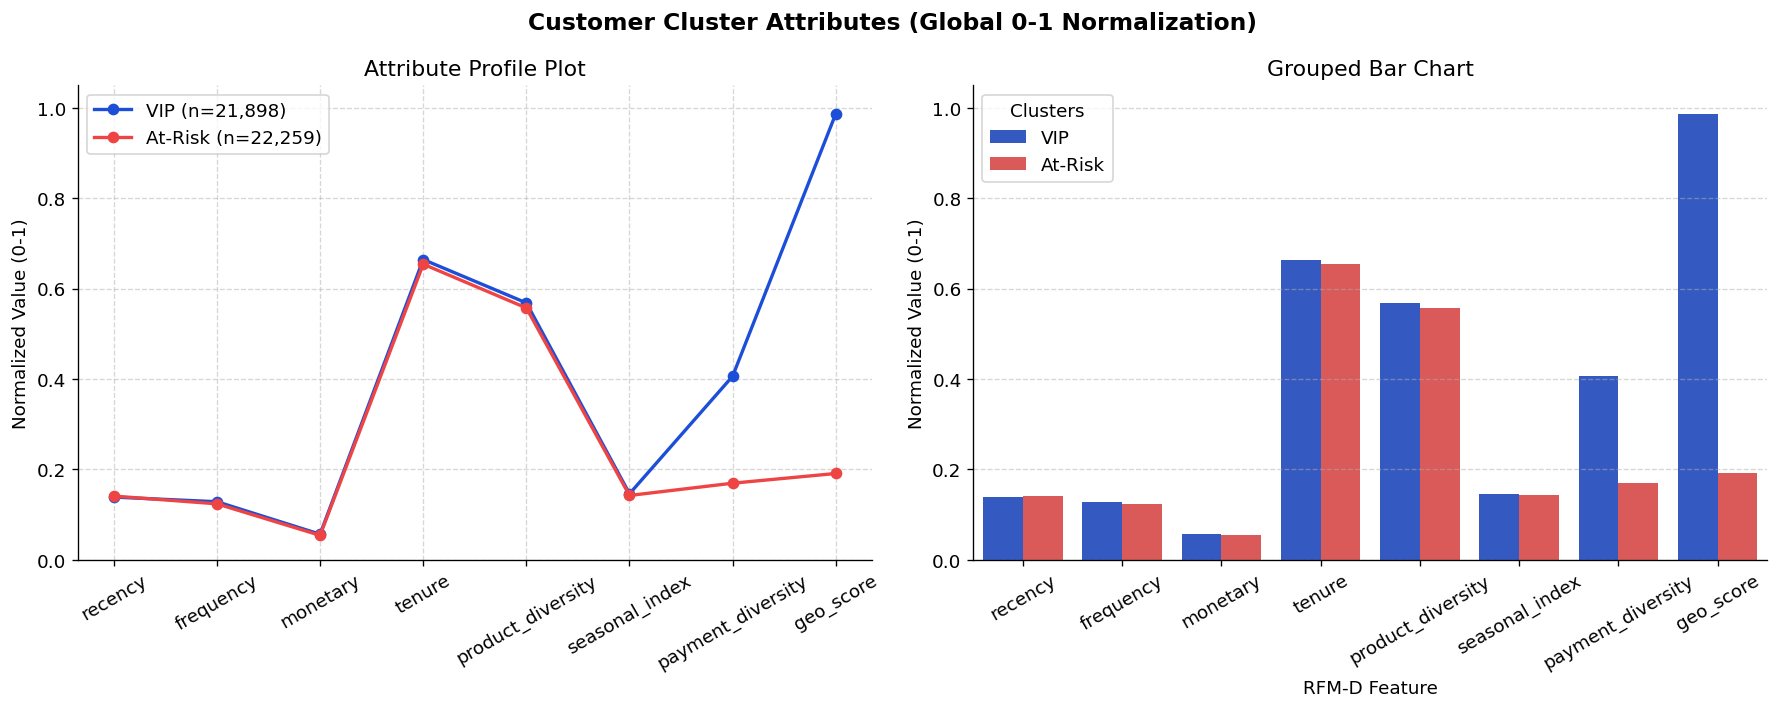

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Read cluster profile and full customer dataset
elig_df = rfmd[rfmd['eligible']]
features_to_plot = ['recency', 'frequency', 'monetary', 'tenure', 'product_diversity', 'seasonal_index', 'payment_diversity', 'geo_score']

# 2. Compute Min and Max on all eligible customers (Population-wide) for accurate normalization
pop_min = elig_df[features_to_plot].min()
pop_max = elig_df[features_to_plot].max()
pop_span = pop_max - pop_min

# 3. Normalize cluster means based on global Min-Max
cluster_means = elig_df.groupby('cluster_raw')[features_to_plot].mean()
cluster_norm = (cluster_means - pop_min) / pop_span
cluster_norm['segment'] = cluster_norm.index.map(SEGMENT_NAMES)
cluster_norm['count'] = elig_df.groupby('cluster_raw').size()

print("=== Global Normalized 0-1 Values of Clusters ===")
display(cluster_norm)

# 4. Plotting
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120)
fig.suptitle('Customer Cluster Attributes (Global 0-1 Normalization)', fontsize=14, fontweight='bold')

# Option 1: Attribute Profile / Radar-like line plot
colors_map = {'VIP': '#1D4ED8', 'Regular': '#059669', 'At-Risk': '#EF4444', 'New': '#F59E0B'}

for idx, row in cluster_norm.iterrows():
    seg_name = row['segment']
    axes[0].plot(features_to_plot, row[features_to_plot].values, 'o-',
                 label=f"{seg_name} (n={int(row['count']):,})",
                 color=colors_map.get(seg_name, '#6B7280'), linewidth=2)
axes[0].set_title('Attribute Profile Plot')
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel('Normalized Value (0-1)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Option 2: Grouped Bar Chart
melted_df = cluster_norm.reset_index().melt(id_vars=['segment', 'count'], value_vars=features_to_plot,
                                            var_name='Feature', value_name='Normalized Value')
sns.barplot(data=melted_df, x='Feature', y='Normalized Value', hue='segment',
            palette=colors_map, ax=axes[1])
axes[1].set_title('Grouped Bar Chart')
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel('Normalized Value (0-1)')
axes[1].set_xlabel('RFM-D Feature')
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(True, axis='y', linestyle='--', alpha=0.5)
axes[1].legend(title='Clusters')

plt.tight_layout()
plt.savefig('cluster_profile_normalized.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
model_df = X_full[['recency', 'frequency', 'monetary', 'product_diversity',
                   'seasonal_index', 'payment_diversity', 'geo_score', 'tenure',
                   'clv_6m', 'churn']].copy()
model_df.index.name = 'customer_id'
model_df.to_csv('model_dataset.csv')
print(model_df.shape)   # kỳ vọng 36.144 dòng

In [ ]:
from google.colab import files
files.download('/content/model_dataset.csv')

In [ ]:
!pip install -q statsmodels

In [ ]:
%%writefile h2_h5_regression.py
import pandas as pd, sys
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

d = pd.read_csv(sys.argv[1], index_col='customer_id')
FEAT = ['recency', 'frequency', 'monetary', 'product_diversity',
        'seasonal_index', 'payment_diversity', 'geo_score', 'tenure']
Z = (d[FEAT] - d[FEAT].mean()) / d[FEAT].std()
Xz = sm.add_constant(Z)

print('=== VIF (kiểm tra cộng tuyến) ===')
for i, c in enumerate(FEAT, start=1):
    print(f'{c:20s} {variance_inflation_factor(Xz.values, i):.2f}')

print('\n=== CLV (OLS): Y1 = clv_6m ===')
ols = sm.OLS(d['clv_6m'], Xz).fit()
print(ols.summary2().tables[1].round(4))
print('R² =', round(ols.rsquared, 4))

print('\n=== Churn (logistic): Y2 = churn ===')
logit = sm.Logit(d['churn'], Xz).fit(disp=0)
print(logit.summary2().tables[1].round(4))
print('Pseudo R² =', round(logit.prsquared, 4))

print('\n=== Xếp hạng |hệ số| ===')
print('CLV   :', ols.params.drop('const').abs().sort_values(ascending=False).round(4).to_dict())
print('Churn :', logit.params.drop('const').abs().sort_values(ascending=False).round(4).to_dict())

In [ ]:
model_df = X_full[['recency', 'frequency', 'monetary', 'product_diversity',
                   'seasonal_index', 'payment_diversity', 'geo_score', 'tenure',
                   'clv_6m', 'churn']].copy()
model_df.index.name = 'customer_id'
model_df.to_csv('model_dataset.csv')
print(model_df.shape)

In [ ]:
!python h2_h5_regression.py model_dataset.csv | tee h2_h5_output.txt

In [ ]:
from google.colab import files
files.download('/content/h2_h5_output.txt')

In [ ]:
import numpy as np, pandas as pd
sv = shap_vals
Xs = X_te[:2000]
rows = []
for i, n in enumerate(feature_cols):
    rows.append((n, np.abs(sv[:, i]).mean(), np.corrcoef(Xs[:, i], sv[:, i])[0, 1]))
print(pd.DataFrame(rows, columns=['feature', 'mean_abs_shap', 'corr(value, shap)'])
        .sort_values('mean_abs_shap', ascending=False).round(4).to_string(index=False))